# Code 207 — Final version: everything that worked in the previous versions

This notebook brings together the elements validated across versions:

- **Clean data**: inputs reprojected to Merchich / Nord Maroc (EPSG:26191) and checked (`code200`, `code201`); a single 250 m grid for the whole forest (`code108`); conversion to degrees only for Open-Meteo and Planetary Computer (`code203`).
- **Correct labels**: dNBR at the 0.27 threshold, images just before and just after the fire, 2 km FIRMS mask, check against the official area (`code106`); unusable fires removed (`code204`).
- **No leakage**: satellite images only between D-10 (D-20 for Landsat) and D-1 (`code107`).
- **Variables**: fixed factors, aspect via circular mean (`code204`), pre-fire satellite variables, and years since the last fire (`code205`).
- **Fuel rule** applied after prediction: zero risk if the cell burned less than one year ago, divided by 2 between 1 and 5 years (`code206`).
- **Honest evaluation**: 12 splits, each fire evaluated by a model that has never seen it (`code204`).
- **Daily weather danger** over 976 summer days 2017-2024 (`code204`).

The last cell displays the **final summary** to be reported in the report.


In [1]:
%pip install -q geopandas rasterio rasterstats shapely pyproj matplotlib pandas numpy requests scikit-learn pystac-client planetary-computer pyarrow joblib xgboost lightgbm


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os, json, math, hashlib, warnings, random, time
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt, rasterio, joblib, requests
from shapely.geometry import box
from shapely import from_wkb
from rasterstats import zonal_stats
from rasterio.windows import from_bounds as rio_from_bounds
import pystac_client, planetary_computer as pc
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score, confusion_matrix, r2_score)
from IPython.display import display

ROOT=Path(os.environ.get('PROJECT_ROOT','/Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem'))
REPROJ=ROOT/'data_prepared/reprojete_26191'   # code202: all local inputs reprojected to EPSG:26191 by code200
FOREST=REPROJ/'limites_forets_26191.shp'   # replaces limites_Bouhachem.shp from code105 (23/09/2026):
                                                # new file with 6 parts (a-f, 'nom' column already present),
                                                # now including Jbel Sougna (d, e, f - 3 distinct sub-areas)
DEM=REPROJ/'mnt_bouhachem_26191_30m.tif'
POPULATION=REPROJ/'population_2017_26191_100m.tif'   # code202: population recomputed on the new grid
FIRMS_DIR=REPROJ/'feux_FIRMS'
SOURCE_89=ROOT/'data_prepared/code89_risque_feu_aujourdhui'
WINDOW_CACHE_SOURCE_89=SOURCE_89/'cache/fenetres'   # code202: code89 caches (old NBR rule), read only for
                                                    # no-fire days, the summer climatology and the auxiliary proxy model
SAT_CACHE_89=SOURCE_89/'cache/satellite'
PREP_90=ROOT/'data_prepared/code90_risque_feu_aujourdhui'          # to reuse the structural factors already computed by code90
PREP=ROOT/'data_prepared/code207_risque_feu_final'
REPORT=ROOT/'outputs/code207_risque_feu_final'
for folder in [PREP,REPORT]: folder.mkdir(parents=True,exist_ok=True)
PREP_201=ROOT/'data_prepared/code201_risque_feu_2005_2022_jbelsougna'   # code202: reuse the computations already done by code201
WINDOW_CACHE_89=PREP_201/'cache/fenetres'   # code202: clean daily cache (new NBR rule: images between D-10/D-20 and D-1)
                                         # - keeps the name WINDOW_CACHE_89 so that all existing code uses it unchanged

CRS='EPSG:26191'; GRID=250; FIRE_RADIUS=500; SEED=93
TRAIN_START=pd.Timestamp('2017-01-01')   # start of the PAMF causal history, as in code89/code90

# --- Selected events, corrected on 22/09/2026 based on a precise timeline ---
# (official start/containment dates, see user message detailing 5 fires):
#   - Bouhachem 2020 : 25/08 -> contained 01/09/2020 (~1100 ha)              -> KEPT
#   - Bouhachem 2022 : 25/07 -> contained 02/08/2022 (>7500 ha)              -> KEPT
#   - Sahel El Menzla / Larache 2022 : 13-18/07/2022 (>10500 ha)            -> EXCLUDED (neighboring forest, NOT Bouhachem)
#   - Derdara / Chefchaouen 2021 : 14-18/08/2021 (>725 ha)                  -> EXCLUDED for now (location
#     uncertain relative to the limites_Bouhachem.shp polygon -> see the geographic check cell
#     below, which automatically tests whether there are local FIRMS detections INSIDE the forest in this window)
#   - Jbel Lahbib / Tétouan-Larache 2017 : 30/06-03/07/2017 (>500 ha)       -> EXCLUDED (neighboring forest, NOT Bouhachem)
FIRE_2020_DATE        = pd.Timestamp('2020-08-25')   # official start date (corrected, was 26/08)
FIRE_2020_BEFORE      = pd.Timestamp('2020-08-24')   # code106: moved closer to the fire (before: 2020-08-18)   # Sentinel-2 image before the 2020 fire (dNBR)
FIRE_2020_AFTER       = pd.Timestamp('2020-09-02')   # code106: moved closer to the fire (before: 2020-09-10)   # after image, well after containment (01/09)
FIRE_2022_BEFORE      = pd.Timestamp('2022-07-24')   # code106: moved closer to the fire (before: 2022-07-15)   # Sentinel-2 image before the 2022 fire (safety margin before 25/07)
FIRE_2022_AFTER       = pd.Timestamp('2022-08-03')   # code106: moved closer to the fire (before: 2022-08-15)   # after image (corrected: the old date 27/07 fell IN THE MIDDLE OF the
                                                      # fire while still active, contained only on 02/08 -> underestimated the burned area)
FIRE_2022_EVENT_DATE  = pd.Timestamp('2022-07-25')   # actual FIRMS date confirmed (detections on 25 and 26/07/2022)

# --- Precise timeline received on 23/09/2026: Derdara/Sougna 2021 becomes a 3rd training fire,
# and the 2 dates in 2025 (13/08 and 21/08) that seemed to be TWO CANDIDATES for ONE SINGLE uncertain fire are
# actually TWO DISTINCT, confirmed FIRES (Derdara 12-18/08, then Bouhachem-near-Derdara 21-24/08)
# -> the cell that decided between the two becomes a simple informative confirmation (see below),
# and the blind test is now run separately for each (blind test cell). ---
DERDARA_2021_DATE     = pd.Timestamp('2021-08-14')   # start ~14:30, Jbel Sougna / Sougna sector, between Derdara and
                                                      # Tanaqoub (confirmed 23/09/2026) - it is precisely to cover
                                                      # this sector that the shapefile was extended to parts d/e/f (code105)
DERDARA_2021_BEFORE   = pd.Timestamp('2021-08-13')   # code106: moved closer to the fire (before: 2021-08-05)   # safety margin before the start
DERDARA_2021_AFTER    = pd.Timestamp('2021-08-19')   # code106: moved closer to the fire (before: 2021-09-05)   # well after full containment (18/08, ~1100 ha according to
                                                      # the most recent timeline received on 23/09/2026, corrects
                                                      # the first estimate of ~725 ha)

# 2 additional fires (extended timeline received on 23/09/2026, Tanaqoub/Bouhachem sector, part 'c'
# of the shapefile = Tanaqoub/Derdara Sud): within the Sentinel-2 period (operational since 2017), therefore usable
# for dNBR, unlike the older events documented below.
FIRE_2019A_DATE    = pd.Timestamp('2019-08-13')   # Tanaqoub-Bouhachem, village (douar) Beni Belal - large fire, contained after >15h
FIRE_2019A_BEFORE  = pd.Timestamp('2019-08-12')   # code106: moved closer to the fire (before: 2019-08-01)
FIRE_2019A_AFTER   = pd.Timestamp('2019-08-15')   # code106: moved closer to the fire (before: 2019-08-28)   # before the start of the 2nd fire's window (05/09)
FIRE_2019B_DATE    = pd.Timestamp('2019-09-13')   # Tanaqoub-Bouhachem, new fire, contained by emergency services
FIRE_2019B_BEFORE  = pd.Timestamp('2019-09-12')   # code106: moved closer to the fire (before: 2019-09-05)   # after the August fire was resolved
FIRE_2019B_AFTER   = pd.Timestamp('2019-09-15')   # code106: moved closer to the fire (before: 2019-09-30)

# 4 older fires (extended timeline received on 23/09/2026, historical study of the province of
# Chefchaouen): prior to Sentinel-2 (operational since 2015). In code103 they were EXCLUDED
# because no dNBR was possible. Since code104 (23/09/2026), dNBR is computed for these 4 dates using
# the LANDSAT archive (Landsat 5 TM, operational until end of 2011, covers these 2 dates well) instead of
# Sentinel-2 - see _resolve_burn_scene_landsat. Coarser resolution (30 m versus 10-20 m for
# Sentinel-2) but a real spectral check, far more reliable than a single FIRMS/MODIS point
# (1 km, often blind to fires of this size - MODIS before VIIRS 2012 is particularly coarse).
SENTINEL2_AVAILABLE_FROM = pd.Timestamp('2015-06-01')   # automatic Landsat/Sentinel-2 switch in compute_dnbr_label
LANDSAT_SR_SCALE  = 0.0000275   # standard USGS Collection 2 Level 2 coefficients (surface reflectance)
LANDSAT_SR_OFFSET = -0.2        # DN -> reflectance: refl = DN * LANDSAT_SR_SCALE + LANDSAT_SR_OFFSET

FIRE_2005_DATE    = pd.Timestamp('2005-09-21')   # Tanaqoub-Bouhachem, 214 ha burned
FIRE_2005_BEFORE  = pd.Timestamp('2005-09-20')   # code106: moved closer to the fire (before: 2005-08-01)
FIRE_2005_AFTER   = pd.Timestamp('2005-09-23')   # code106: moved closer to the fire (before: 2005-11-15)

FIRE_2009A_DATE   = pd.Timestamp('2009-07-26')   # Derdara - Jbel Sougna, 149 ha burned, start reported at 16:00.
                                                  # FIRMS confirms a detection on 28/07/2009 (+2d, within the
                                                  # tolerance window of the FIRMS fallback - see label_fire_window)
FIRE_2009A_BEFORE = pd.Timestamp('2009-07-25')   # code106: moved closer to the fire (before: 2009-06-01)
FIRE_2009A_AFTER  = pd.Timestamp('2009-07-28')   # code106: moved closer to the fire (before: 2009-10-01)

# MERGED in code105 (23/09/2026): Derdara-Bouhachem (11/08, 168 ha) and Mont Bouhachem (12/08,
# >20 ha) were treated as 2 distinct fires in code104. A continuous FIRMS detection over 2
# consecutive days (11-12/08/2009), described in both sources around "Bouhachem", is the typical
# signature of ONE SINGLE fire spreading over 2 days, not of 2 independent fires - so we merge them
# into a single training event 2009BC rather than counting them twice.
# Pre-2025 FIRMS summary (confirmed 23/09/2026): 2009a (26/07) has a detection 2 days later (28/07);
# 2009BC (11-12/08) has a continuous detection over the 2 days; ONLY 2005 (21/09) has no confirmed
# FIRMS detection - its label will therefore rely entirely on the Landsat dNBR, with no possible fallback.
FIRE_2009BC_DATE    = pd.Timestamp('2009-08-11')   # Derdara-Bouhachem / Mont Bouhachem, complex 11-12/08/2009 (168+20 ha)
FIRE_2009BC_BEFORE  = pd.Timestamp('2009-08-10')   # code106: moved closer to the fire (before: 2009-06-15)
FIRE_2009BC_AFTER   = pd.Timestamp('2009-08-14')   # code106: moved closer to the fire (before: 2009-10-15)

# History: these 4 fires were EXCLUDED in code103 (no Sentinel-2 available before 2015).
# Since code104, they are checked by dNBR using the Landsat archive and included in EVENTS_ENTRAINEMENT
# (see following cells) - this dict remains available, empty for now, in case a future fire
# turns out to be truly unverifiable (neither Landsat nor FIRMS).
EXCLUDED_PRE_SENTINEL2_EVENTS = {}

# 2025 EVENT A "Derdara": start 12/08, 3 of the 4 hotspots contained on the 13th, circumscribed on the 14th, extinction
# confirmed on the 15th, isolated flare-up on the 18th contained the same day.
PRE_2025_DERDARA           = pd.Timestamp('2025-08-11')   # code106: moved closer to the fire (before: 2025-08-05)
TEST_DATE_2025_DERDARA     = pd.Timestamp('2025-08-12')   # code202: day of the start (before: 13/08), as for training
AFTER_2025_DERDARA         = pd.Timestamp('2025-08-19')   # after the flare-up of the 18th, before the start of the 2nd fire (21/08)

# 2025 EVENT B "Bouhachem, near Derdara": start 21/08, active hotspots 22-23, full containment on the 24th.
PRE_2025_BOUHACHEM_PRES_DERDARA        = pd.Timestamp('2025-08-20')   # code106: moved closer to the fire (before: 2025-08-19)   # same image as AFTER_2025_DERDARA (just
                                                                        # after fire A was resolved, before B)
TEST_DATE_2025_BOUHACHEM_PRES_DERDARA  = pd.Timestamp('2025-08-21')
AFTER_2025_BOUHACHEM_PRES_DERDARA      = pd.Timestamp('2025-08-25')   # code106: moved closer to the fire (before: 2025-08-29)

# Backward compatibility: aliases to event A (Derdara) for any code that still expects these generic names.
PRE_2025_DATE   = PRE_2025_DERDARA
TEST_DATE_2025  = TEST_DATE_2025_DERDARA
AFTER_2025_DATE = AFTER_2025_DERDARA

# code106: 'debut'/'fin' = start and containment (FIRMS mask of the ground truth); 'sd_avant'/'sd_apres' = maximum
# image search window (days), so that the ground truth of one fire does not contain the other (A: 12-18/08, B: 21-24/08).
EVENEMENTS_2025 = [
    {'nom':'Derdara','slug':'derdara','pre':PRE_2025_DERDARA,'test':TEST_DATE_2025_DERDARA,'after':AFTER_2025_DERDARA,
     'debut':pd.Timestamp('2025-08-12'),'fin':pd.Timestamp('2025-08-18'),'sd_avant':None,'sd_apres':2},
    {'nom':'Bouhachem, near Derdara','slug':'bouhachem_pres_derdara','pre':PRE_2025_BOUHACHEM_PRES_DERDARA,
     'test':TEST_DATE_2025_BOUHACHEM_PRES_DERDARA,'after':AFTER_2025_BOUHACHEM_PRES_DERDARA,
     'debut':pd.Timestamp('2025-08-21'),'fin':pd.Timestamp('2025-08-24'),'sd_avant':6,'sd_apres':None},
]

# Approximate windows of the neighboring fires not kept (for the automatic geographic check):
EXCLUDED_NEIGHBOR_EVENTS = {
    'Larache/Sahel_El_Menzla_2022': (pd.Timestamp('2022-07-13'), pd.Timestamp('2022-07-18')),
    'Jbel_Lahbib_Tetouan_2017':     (pd.Timestamp('2017-06-30'), pd.Timestamp('2017-07-03')),
}

BURN_DNBR_THRESHOLD = 0.27   # code106 (before: 0.10): start of USGS "moderate" severity; 0.10 = "unburned" limit,
                             # exceeded by simple summer drying -> labels 10 to 90 times too large in code105
N_NEG_DAYS = 20               # number of additional "no-fire" days drawn from the code89 cache
NEG_EXCLUSION_DAYS = 30       # margin in days around each fire to exclude "negative" days (smoke, post-fire stress...)
FIRE_2020_WINDOW_DAYS = 2      # tolerance (in days) around FIRE_2020_DATE if no FIRMS detection falls exactly on that day

# --- NEW (code106) ---
AGE_MAX_SENTINEL2 = 10   # code202: maximum age (days) of the Sentinel-2 image used for the day's NBR/NDVI/NDMI
AGE_MAX_LANDSAT   = 20   # code202: same for Landsat (2005/2009, 16-day revisit)
# In both cases, the image must be taken no later than the DAY BEFORE the studied day (D-1): never the same day.
CELL_HA = (GRID/100)**2          # area of one cell in hectares (6.25 ha for 250 m)
FIRMS_MASK_BUFFER_M = 2000       # a cell is 'burned' only if it is less than 2 km from a FIRMS detection of the fire
FACTEUR_SURFACE_MAX = 2.0        # if the label exceeds 2 x the official area -> keep the cells with the highest dNBR
FRACTIONS_ALERTE_CANDIDATES = [0.05,0.10,0.15,0.20]   # share of cells on alert each day (chosen in validation; 20 % max to remain useful in the field)
MOIS_ETE = [6,7,8,9]             # reference months for the daily weather danger index
DANGER_VARS = {'temperature_2m_max':+1,'vpd_max':+1,'wind_speed_10m_max':+1,'relative_humidity_2m_min':-1}  # +1: higher = more dangerous

print('Cache code89:',WINDOW_CACHE_89)
print('Training fires (Sentinel-2): 2020 ({}), 2022 ({}), Derdara 2021 ({}), Tanaqoub 2019a ({}), Tanaqoub 2019b ({})'.format(
      FIRE_2020_DATE.date(),FIRE_2022_EVENT_DATE.date(),DERDARA_2021_DATE.date(),FIRE_2019A_DATE.date(),FIRE_2019B_DATE.date()))
print('Training fires (Landsat, pre-2015): 2005 ({}), 2009a ({}), 2009bc ({}, merged 11-12/08 - only date '
      'confirmed by FIRMS before 2025)'.format(FIRE_2005_DATE.date(),FIRE_2009A_DATE.date(),FIRE_2009BC_DATE.date()))
print('Blind tests 2025:',', '.join('{} ({})'.format(e['nom'],e['test'].date()) for e in EVENEMENTS_2025))
if EXCLUDED_PRE_SENTINEL2_EVENTS:
    print('Documented but excluded fires (unverifiable):',', '.join(EXCLUDED_PRE_SENTINEL2_EVENTS))


# ------------------------------------------------------------------
# code201 (fix): internet connection test BEFORE any computation. Sentinel-2/Landsat (Planetary Computer)
# and the weather (Open-Meteo) are read online: without a connection, the notebook stops here with a clear
# message, instead of silently replacing all dNBR labels with FIRMS further on.
# ------------------------------------------------------------------
import socket
def verifier_connexion(hotes=('planetarycomputer.microsoft.com','archive-api.open-meteo.com')):
    for hote in hotes:
        try:
            socket.create_connection((hote,443),timeout=10).close()
        except OSError as exc:
            raise ConnectionError("No access to {} ({}). Check the internet connection (Wi-Fi, VPN, proxy), "
                                  "then rerun the notebook from the start.".format(hote,exc)) from None
    print('Internet connection OK:',', '.join(hotes))
verifier_connexion()


# ------------------------------------------------------------------
# code202: check of the reprojected inputs - each file must exist and be in EPSG:26191.
# ------------------------------------------------------------------
OSM_DIR_REPROJ=REPROJ/'osm'
LULC_REPROJ=REPROJ/'occupation_sol_2021_26191_10m.tif'
def controler_inputs_reprojetes():
    from pyproj import CRS as _CRS
    attendu=_CRS.from_user_input(CRS)
    fichiers=[FOREST,DEM,POPULATION,LULC_REPROJ]+sorted(FIRMS_DIR.glob('fire_*.shp'))+sorted(OSM_DIR_REPROJ.glob('osm_code13_2022_*.parquet'))
    if not REPROJ.exists() or len(fichiers)<4+3+5:
        raise FileNotFoundError("Incomplete reprojected inputs in {}: run code200_reprojection_inputs_merchich first.".format(REPROJ))
    for p in fichiers:
        if not p.exists(): raise FileNotFoundError('Missing reprojected file: '+str(p))
        if p.suffix=='.tif':
            with rasterio.open(p) as s: crs=s.crs
        elif p.suffix=='.shp': crs=gpd.read_file(p,rows=1).crs
        else: crs=gpd.read_parquet(p).crs
        if crs is None or not _CRS.from_user_input(crs).equals(attendu):
            raise ValueError('{} is not in {} ({}): rerun code200.'.format(p.name,CRS,crs))
        print('  {:<50} {}'.format(str(p.relative_to(REPROJ)),CRS))
    print('All local inputs are in',CRS)
controler_inputs_reprojetes()


# ------------------------------------------------------------------
# code201 (fix): Open-Meteo sometimes responds very slowly (ReadTimeout after 120 s). Each request
# is now retried up to 5 times, with an increasing wait (10, 20, 40, 80 s) between attempts.
# ------------------------------------------------------------------
def requete_avec_reessais(url,params=None,timeout=120,essais=5,attente=10):
    for k in range(essais):
        try:
            r=requests.get(url,params=params,timeout=timeout)
            if r.status_code in (429,500,502,503,504): raise requests.HTTPError('statut {}'.format(r.status_code))
            return r
        except (requests.Timeout,requests.ConnectionError,requests.HTTPError) as exc:
            if k==essais-1: raise
            print('  {}: attempt {}/{} failed ({}) - retrying in {} s.'.format(url.split('/')[2],k+1,essais,type(exc).__name__,attente*2**k))
            time.sleep(attente*2**k)


Cache code89: /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/data_prepared/code201_risque_feu_2005_2022_jbelsougna/cache/fenetres
Training fires (Sentinel-2): 2020 (2020-08-25), 2022 (2022-07-25), Derdara 2021 (2021-08-14), Tanaqoub 2019a (2019-08-13), Tanaqoub 2019b (2019-09-13)
Training fires (Landsat, pre-2015): 2005 (2005-09-21), 2009a (2009-07-26), 2009bc (2009-08-11, merged 11-12/08 - only date confirmed by FIRMS before 2025)
Blind tests 2025: Derdara (2025-08-12), Bouhachem, near Derdara (2025-08-21)
Internet connection OK: planetarycomputer.microsoft.com, archive-api.open-meteo.com
  limites_forets_26191.shp                           EPSG:26191
  mnt_bouhachem_26191_30m.tif                        EPSG:26191
  population_2017_26191_100m.tif                     EPSG:26191
  occupation_sol_2021_26191_10m.tif                  EPSG:26191
  feux_FIRMS/fire_archive_M-C61_811482_26191.shp     EPSG:26191
  feux_FIRMS/fire_archive_SV-C2_806566_26191.shp     EPSG:26191
  feux_FIR

In [3]:
# Same grid and same FIRMS as code89/code90
# ------------------------------------------------------------------
# code202: projection check of the forest. The .prj is an ESRI "Nord_Maroc" (Merchich, Lambert conformal
# conic) with the same parameters as EPSG:26191: the reprojection must therefore not move the polygon.
# ------------------------------------------------------------------
forest_brut=gpd.read_file(FOREST)
print('Forest shapefile projection:',forest_brut.crs.name if forest_brut.crs else 'NONE')
forest=forest_brut.to_crs(CRS)
_ecart=np.abs(np.asarray(forest.total_bounds)-np.asarray(forest_brut.total_bounds)).max()
if _ecart>1:
    print('WARNING: reprojecting to {} moves the forest by {:.1f} m although the parameters are identical - '
          'keeping the original coordinates (set_crs) so as not to shift the forest.'.format(CRS,_ecart))
    forest=forest_brut.set_crs(CRS,allow_override=True)
else:
    print('Forest reprojection to {}: shift {:.2f} m (expected ~0) - OK.'.format(CRS,_ecart))
forest['partie']=forest['nom'].astype(str).str.lower() if 'nom' in forest else [chr(97+k) for k in range(len(forest))]

# ------------------------------------------------------------------
# code202: ONE SINGLE grid over the whole forest (the 6 parts combined). A 250 m cell exists only
# once, even if it straddles two parts. `partie` = the part that covers the largest area of the
# cell, kept only for information and diagnostics (never used by the model).
# ------------------------------------------------------------------
foret_unique=forest.geometry.union_all()
minx,miny,maxx,maxy=foret_unique.bounds
_sindex=forest.sindex
rows=[]
for x in np.arange(math.floor(minx/GRID)*GRID,maxx,GRID):
    for y in np.arange(math.floor(miny/GRID)*GRID,maxy,GRID):
        carre=box(x,y,x+GRID,y+GRID)
        geom=carre.intersection(foret_unique)
        if geom.is_empty or geom.area<100: continue
        _cand=forest.iloc[list(_sindex.query(carre,predicate='intersects'))]
        _partie=_cand.partie.iloc[int(np.argmax(_cand.geometry.intersection(carre).area.to_numpy()))] if len(_cand) else '?'
        rows.append({'id_cell':f'foret_{len(rows):05d}','partie':_partie,'geometry':geom})
grid=gpd.GeoDataFrame(rows,crs=CRS)

# ------------------------------------------------------------------
# code203: CENTER and RECTANGLE of the forest computed in Merchich (meters), then converted to WGS 84 degrees
# ONLY for the two online services that require it (Open-Meteo: a point; Planetary Computer:
# a search rectangle). Conversion by PROJ with Merchich -> WGS 84 datum shift (~335 m here).
# The rectangle is densified (21 points per side): a straight rectangle in Merchich is slightly curved in
# degrees, its 4 corners alone would not be enough to enclose it.
# ------------------------------------------------------------------
from pyproj import Transformer
from shapely.geometry import Point
_vers_wgs84=Transformer.from_crs(CRS,'EPSG:4326',always_xy=True)
CENTRE_MERCHICH=foret_unique.centroid
BBOX_MERCHICH=foret_unique.bounds
_lon,_lat=_vers_wgs84.transform(CENTRE_MERCHICH.x,CENTRE_MERCHICH.y)
CENTRE_WGS84=Point(_lon,_lat)
BBOX_WGS84=list(_vers_wgs84.transform_bounds(*BBOX_MERCHICH,densify_pts=21))
print('Forest center        : Merchich X = {:.1f} m, Y = {:.1f} m  ->  WGS 84 lat = {:.6f}°, lon = {:.6f}°'.format(
      CENTRE_MERCHICH.x,CENTRE_MERCHICH.y,CENTRE_WGS84.y,CENTRE_WGS84.x))
print('Forest rectangle     : Merchich X {:.0f} -> {:.0f} m, Y {:.0f} -> {:.0f} m'.format(
      BBOX_MERCHICH[0],BBOX_MERCHICH[2],BBOX_MERCHICH[1],BBOX_MERCHICH[3]))
print('                       WGS 84 lon {:.5f} -> {:.5f}°, lat {:.5f} -> {:.5f}°'.format(
      BBOX_WGS84[0],BBOX_WGS84[2],BBOX_WGS84[1],BBOX_WGS84[3]))
print('(These degree values are only used to query Open-Meteo and Planetary Computer; all computations stay in Merchich.)')
grid['surface_foret_km2']=grid.area/1_000_000
print('Single grid: {} cells over the whole forest ({:.0f} ha). Indicative breakdown by part:'.format(
      len(grid),grid.area.sum()/1e4),grid.partie.value_counts().sort_index().to_dict())

fire_frames=[]
for path in FIRMS_DIR.rglob('fire_*.shp'):
    f=gpd.read_file(path)
    print('  {}: projection {}'.format(path.name,f.crs.name if f.crs else 'NONE'))
    if f.crs is None: raise ValueError('FIRMS file without projection (.prj missing): '+str(path))
    f=f.to_crs(CRS)
    f['date']=pd.to_datetime(f['ACQ_DATE'],errors='coerce').dt.normalize()
    f['frp']=pd.to_numeric(f['FRP'],errors='coerce').fillna(0)
    fire_frames.append(f[['date','frp','geometry']])
firms=gpd.GeoDataFrame(pd.concat(fire_frames,ignore_index=True),crs=CRS).dropna(subset=['date'])
firms=firms[firms.geometry.intersects(forest.geometry.union_all().buffer(5000))]
firms=firms.drop_duplicates(subset=['date','geometry']).sort_values('date').reset_index(drop=True)
print(len(grid),'cells | FIRMS',firms.date.min().date(),'→',firms.date.max().date())
print('Projection check: {} FIRMS point(s) within the forest itself, {} within 5 km.'.format(
      int(firms.geometry.within(foret_unique).sum()),len(firms)))

Forest shapefile projection: Merchich / Nord Maroc
Forest reprojection to EPSG:26191: shift 0.00 m (expected ~0) - OK.
Forest center        : Merchich X = 496720.1 m, Y = 514113.5 m  ->  WGS 84 lat = 35.227937°, lon = -5.434393°
Forest rectangle     : Merchich X 481506 -> 518126 m, Y 494731 -> 532314 m
                       WGS 84 lon -5.60187 -> -5.19891°, lat 35.05310 -> 35.39195°
(These degree values are only used to query Open-Meteo and Planetary Computer; all computations stay in Merchich.)
Single grid: 6071 cells over the whole forest (25866 ha). Indicative breakdown by part: {'a': 4480, 'b': 489, 'c': 551, 'd': 319, 'e': 156, 'f': 76}
  fire_archive_M-C61_811482_26191.shp: projection Merchich / Nord Maroc
  fire_nrt_SV-C2_806566_26191.shp: projection Merchich / Nord Maroc
  fire_archive_SV-C2_806566_26191.shp: projection Merchich / Nord Maroc
6071 cells | FIRMS 2005-05-09 → 2026-06-05
Projection check: 445 FIRMS point(s) within the forest itself, 1176 within 5 km.


In [4]:
# ------------------------------------------------------------------
# code202: check of the SINGLE forest, in Merchich / Nord Maroc (EPSG:26191), coordinates in meters.
# (The old cell that displayed the center of each part in degrees was removed: it was used
# only for display and took part in no computation.)
# ------------------------------------------------------------------
_centre=foret_unique.centroid
print('Single forest: {} polygon(s) merged into a single geometry, area {:.0f} ha, system {}.'.format(
      len(forest),foret_unique.area/1e4,grid.crs.to_string()))
print('Forest center: X = {:.0f} m, Y = {:.0f} m (Merchich / Nord Maroc).'.format(_centre.x,_centre.y))
print('Extent: X {:.0f} -> {:.0f} m, Y {:.0f} -> {:.0f} m.'.format(*foret_unique.bounds[0::2],*foret_unique.bounds[1::2]))


Single forest: 6 polygon(s) merged into a single geometry, area 25866 ha, system EPSG:26191.
Forest center: X = 496720 m, Y = 514114 m (Merchich / Nord Maroc).
Extent: X 481506 -> 518126 m, Y 494731 -> 532314 m.


## Inventory of all available fire episodes (beyond 2020 and 2022)

Before limiting ourselves to 2 training events, it is worth checking how many other FIRMS detection episodes actually exist in/near the forest over the whole period covered by the local files. Raw detections are grouped into episodes (days close in time) rather than listed day by day, to give a real list of candidates for additional events — which could reduce the generalization problem observed in leave-one-fire-out.

The full table is also exported to CSV (`inventaire_episodes_firms_bouhachem.csv`) so it can be inspected or shared outside Jupyter without risking display truncation.

In [5]:
# ------------------------------------------------------------------
# Inventory of ALL FIRMS detection episodes in/near the forest, over the whole period
# available in the local shapefile - not only 2020 and 2022. Used to identify other fires
# usable as additional training events (see the discussion on the lack of
# data with only 2 events in leave-one-fire-out).
#
# Raw detections are grouped into "episodes" (consecutive or close days, tolerance of
# 5 days between two detections, to account for gaps due to clouds/satellite passes) because
# a single fire usually spans several days - looking day by day would strongly underestimate
# each event and would mix a real large fire with isolated noise.
# ------------------------------------------------------------------
forest_only=forest.geometry.union_all()
firms_in_forest=firms[firms.geometry.within(forest_only.buffer(GRID))]  # tolerance of one grid cell
detections_par_jour=(firms_in_forest.assign(jour=firms_in_forest.date.dt.date)
                      .groupby('jour')
                      .agg(nb_detections=('frp','size'),frp_total=('frp','sum'))
                      .sort_index())

jours_tries=list(detections_par_jour.index)
episodes=[]
if jours_tries:
    courant=[jours_tries[0]]
    for jour in jours_tries[1:]:
        if (jour-courant[-1]).days<=5:
            courant.append(jour)
        else:
            episodes.append(courant); courant=[jour]
    episodes.append(courant)

evenements_connus=[(FIRE_2020_DATE.date(),'incendie_2020_deja_utilise'),
                    (FIRE_2022_EVENT_DATE.date(),'incendie_2022_deja_utilise')]

rows=[]
for ep in episodes:
    debut,fin=ep[0],ep[-1]
    sous=detections_par_jour.loc[ep]
    chevauche=[nom for date_connue,nom in evenements_connus
               if (debut-pd.Timedelta(days=5))<=date_connue<=(fin+pd.Timedelta(days=5))]
    rows.append({'debut':debut,'fin':fin,'duree_jours':(fin-debut).days+1,
                 'nb_jours_avec_detection':len(ep),'nb_detections_total':int(sous.nb_detections.sum()),
                 'frp_total':float(sous.frp_total.sum()),
                 'deja_utilise_comme':', '.join(chevauche) if chevauche else ''})

inventaire_episodes=pd.DataFrame(rows).sort_values('frp_total',ascending=False).reset_index(drop=True)

print('{} distinct day(s) with FIRMS detection in/near the forest, grouped into {} episode(s), '
      'between {} and {} (local data).'.format(
      len(detections_par_jour),len(inventaire_episodes),firms.date.min().date(),firms.date.max().date()))
print('Episodes already used for training (2020, 2022) are marked in the "deja_utilise_comme" column.')
print('Each OTHER episode is a potential candidate to check (geography, exact dates, Sentinel-2')
print('availability) before adding it as an additional training event.')

pd.set_option('display.max_rows',None); pd.set_option('display.width',200)
display(inventaire_episodes)
pd.reset_option('display.max_rows'); pd.reset_option('display.width')

chemin_inventaire=REPORT/'inventaire_episodes_firms_bouhachem.csv'
inventaire_episodes.to_csv(chemin_inventaire,index=False)
print('Full inventory exported (for sharing/inspection outside Jupyter):',chemin_inventaire)

89 distinct day(s) with FIRMS detection in/near the forest, grouped into 57 episode(s), between 2005-05-09 and 2026-06-05 (local data).
Episodes already used for training (2020, 2022) are marked in the "deja_utilise_comme" column.
Each OTHER episode is a potential candidate to check (geography, exact dates, Sentinel-2
availability) before adding it as an additional training event.


,debut,fin,duree_jours,nb_jours_avec_detection,nb_detections_total,frp_total,deja_utilise_comme
0,2022-07-25,2022-07-26,2,2,184,13431.57,incendie_2022_deja_utilise
1,2020-08-26,2020-09-06,12,11,229,4597.82,incendie_2020_deja_utilise
2,2021-08-14,2021-08-18,5,5,109,2442.41,
3,2025-08-21,2025-08-22,2,2,20,1413.68,
4,2005-07-21,2005-07-21,1,1,3,1072.90,
5,2025-08-12,2025-08-13,2,2,40,644.63,
6,2017-10-15,2017-10-15,1,1,34,626.85,
7,2009-08-11,2009-08-12,2,2,10,587.80,
8,2012-09-21,2012-09-23,3,2,3,181.00,
9,2012-03-12,2012-03-13,2,2,3,112.60,


Full inventory exported (for sharing/inspection outside Jupyter): /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/outputs/code207_risque_feu_final/inventaire_episodes_firms_bouhachem.csv


## Geographic check of neighboring fires (Larache 2022, Derdara 2021, Jbel Lahbib 2017)

These 3 fires are documented in external sources but described as located in **neighboring**
forests, not in the Bouhachem massif itself (`limites_Bouhachem.shp`). Rather than trusting
the place names in press articles, we check here directly whether there are **local** FIRMS
detections (the shapefile already loaded in this notebook) that actually fall inside the
forest polygon during these date windows. If so, the fire spread into Bouhachem and
could be added to training; if not, the exclusion is confirmed.

In [6]:
# ------------------------------------------------------------------
# For each neighboring fire not kept, check whether there are FIRMS detections *inside* the forest
# (firms_in_forest, tolerance 1 grid cell) during its date window. `firms` already contains
# a wider buffer (5 km around the forest) so the detections of these neighboring fires should
# normally appear there, but NOT in firms_in_forest if the fire is actually outside.
# ------------------------------------------------------------------
for nom,(debut,fin) in EXCLUDED_NEIGHBOR_EVENTS.items():
    proche=firms[(firms.date>=debut-pd.Timedelta(days=1))&(firms.date<=fin+pd.Timedelta(days=1))]
    dedans=firms_in_forest[(firms_in_forest.date>=debut-pd.Timedelta(days=1))&(firms_in_forest.date<=fin+pd.Timedelta(days=1))]
    print('{:<32} {} -> {}: {} detection(s) nearby (5km buffer), of which {} ACTUALLY inside the forest.'.format(
          nom,debut.date(),fin.date(),len(proche),len(dedans)))
    if len(dedans):
        print('   -> WARNING: this fire seems to have reached the Bouhachem forest itself. Dates concerned:',
              sorted(dedans.date.dt.date.unique()),'. To be re-assessed as a potential training event.')
    else:
        print('   -> no detection inside the forest: exclusion confirmed, this event stays out of training.')


Larache/Sahel_El_Menzla_2022     2022-07-13 -> 2022-07-18: 0 detection(s) nearby (5km buffer), of which 0 ACTUALLY inside the forest.
   -> no detection inside the forest: exclusion confirmed, this event stays out of training.
Jbel_Lahbib_Tetouan_2017         2017-06-30 -> 2017-07-03: 0 detection(s) nearby (5km buffer), of which 0 ACTUALLY inside the forest.
   -> no detection inside the forest: exclusion confirmed, this event stays out of training.


In [7]:
# Structural factors: reuse the cache already computed by code90 if it exists (same grid, same id_cell),
# otherwise recompute them once with exactly the same method as code90.
#
# FIX (code105, 23/09/2026): this cache was originally computed on the OLD grid (limites_Bouhachem.shp,
# without Jbel Sougna). Before trusting it, we check that ALL id_cell values of the CURRENT grid (with
# Jbel Sougna = parts d/e/f) are actually present in it - otherwise a plain 'left' merge would silently leave
# altitude_m/pente_pct/exposition_deg/... as NaN for the whole Jbel Sougna area (then imputed with an irrelevant
# global median, without any warning). If id_cell values are missing, everything is recomputed from the DEM/OSM
# instead of reusing a partial cache.
cache_structural = PREP_90/'facteurs_structurels_code90.parquet'
_reuse_cache_structural = False
if False and cache_structural.exists():   # code202 : never reused, the factors are recomputed from the reprojected inputs
    structural_flat = pd.read_parquet(cache_structural)
    _manquants = set(grid.id_cell) - set(structural_flat.id_cell)
    if _manquants:
        print("WARNING: the code90 structural cache ({}) does not cover {} cell(s) of the current grid "
              "(probably Jbel Sougna, added on 23/09/2026 - also check that mnt_bouhachem.tif and the "
              "OSM files actually cover this area geographically) -> full recomputation from the DEM/OSM.".format(
              cache_structural,len(_manquants)))
    else:
        _reuse_cache_structural = True

if _reuse_cache_structural:
    # Only id_cell + geometry are taken from `grid`: if `grid` were merged in full, the shared
    # columns (surface_foret_km2, partie...) would be duplicated as _x/_y by the merge and break
    # `causal_pamf` further down (frame.surface_foret_km2 would no longer exist under that name).
    structural = grid[['id_cell','geometry']].merge(structural_flat, on='id_cell', how='left', validate='one_to_one')
    structural = gpd.GeoDataFrame(structural, geometry='geometry', crs=CRS)
    print('Structural factors reused from code90:', cache_structural)
else:
    OSM_DIR=OSM_DIR_REPROJ   # code202 : reprojected OSM
    OSM_FILES={
     'distance_route_m':OSM_DIR/'osm_code13_2022_distance_route_m.parquet',
     'distance_piste_m':OSM_DIR/'osm_code13_2022_distance_piste_m.parquet',
     'distance_batiment_m':OSM_DIR/'osm_code13_2022_distance_batiment_m.parquet',
     'distance_douar_m':OSM_DIR/'osm_code13_2022_distance_douar_m.parquet',
     'distance_agriculture_m':OSM_DIR/'osm_code13_2022_distance_agriculture_m.parquet'}
    LULC=LULC_REPROJ         # code202 : reprojected land cover (10 m, EPSG:26191)

    structural=grid.copy(); centroids=structural.geometry.centroid
    for name,path in OSM_FILES.items():
        if not path.exists(): raise FileNotFoundError(path)
        raw=pd.read_parquet(path)
        objects=gpd.GeoSeries(from_wkb(raw['geom'].to_numpy()),crs=CRS)
        structural[name]=centroids.distance(objects.union_all()).astype(float)

    pressure=[]
    for name in OSM_FILES:
        scale=max(float(structural[name].quantile(.95)),1.)
        pressure.append(1-(structural[name]/scale).clip(0,1))
    structural['pression_humaine_01']=pd.concat(pressure,axis=1).mean(axis=1)

    with rasterio.open(LULC) as src:
        cats=zonal_stats(structural.to_crs(src.crs),str(LULC),categorical=True,nodata=src.nodata,all_touched=False)
    structural['occupation_sol_2021']=[max(row,key=row.get) if row else np.nan for row in cats]
    fuel_lookup={1:0.,2:.85,4:.55,5:.65,7:.10,8:.15,9:0.,10:np.nan,11:.75}
    structural['combustibilite_01']=structural.occupation_sol_2021.map(fuel_lookup).astype(float)

    with rasterio.open(DEM) as src:
        dem=src.read(1).astype('float32'); invalid=(dem==src.nodata) if src.nodata is not None else ~np.isfinite(dem)
        dem[invalid]=np.nan
        yres=abs(src.transform.e); xres=abs(src.transform.a)
        dzdy,dzdx=np.gradient(dem,yres,xres)
        slope=np.sqrt(dzdx**2+dzdy**2)*100
        aspect=(np.degrees(np.arctan2(-dzdx,dzdy))+360)%360
        cells=structural.to_crs(src.crs)
        zs=zonal_stats(cells,dem,affine=src.transform,stats=['mean'],nodata=np.nan,all_touched=True)
        ps=zonal_stats(cells,slope,affine=src.transform,stats=['mean'],nodata=np.nan,all_touched=True)
        # code204 : aspect by CIRCULAR MEAN (mean of the sines and cosines). A plain mean of the
        # degrees gave ~180° (south) for a north-facing slope whose pixels are ~355° and ~5°.
        az_sin=zonal_stats(cells,np.sin(np.radians(aspect)),affine=src.transform,stats=['mean'],nodata=np.nan,all_touched=True)
        az_cos=zonal_stats(cells,np.cos(np.radians(aspect)),affine=src.transform,stats=['mean'],nodata=np.nan,all_touched=True)
    structural['altitude_m']=[z['mean'] for z in zs]
    structural['pente_pct']=[z['mean'] for z in ps]
    _s=np.array([np.nan if z['mean'] is None else z['mean'] for z in az_sin],float)
    _c=np.array([np.nan if z['mean'] is None else z['mean'] for z in az_cos],float)
    structural['exposition_deg']=(np.degrees(np.arctan2(_s,_c))+360)%360
    # code202 : population (inhabitants per cell) recomputed on the new grid
    if POPULATION.exists():
        with rasterio.open(POPULATION) as src:
            _pop=zonal_stats(structural.to_crs(src.crs),str(POPULATION),stats=['sum'],nodata=src.nodata,all_touched=True)
        structural['population']=[z['sum'] if z['sum'] is not None else 0. for z in _pop]
    else:
        print('WARNING: population raster not found ({}) - population variable missing.'.format(POPULATION))
    structural.drop(columns='geometry').to_parquet(PREP/'facteurs_structurels_code207.parquet',index=False)
    print('Structural factors recomputed from the inputs reprojected to {}.'.format(CRS))

display(structural.drop(columns='geometry').describe().T)

Structural factors recomputed from the inputs reprojected to EPSG:26191.


,count,mean,std,min,25%,50%,75%,max
surface_foret_km2,6071.0,0.042605,0.020482,0.000102,0.026484,0.050741,0.061316,0.062500
distance_route_m,6071.0,1071.223099,933.400255,0.143140,367.539608,809.110022,1508.955201,4879.658161
distance_piste_m,6071.0,820.889215,507.519371,0.303806,425.802158,766.096855,1138.595781,2933.138984
distance_batiment_m,6071.0,2312.157003,1575.529477,0.000000,1082.821879,1888.628908,3278.447448,7397.147758
distance_douar_m,6071.0,4593.258825,2188.915093,168.764695,2797.606522,4386.420497,6309.459437,10140.440915
distance_agriculture_m,6071.0,2205.464309,1997.283691,0.000000,538.372317,1697.819951,3403.648725,9332.974580
pression_humaine_01,6071.0,0.576165,0.173376,0.089514,0.481217,0.612929,0.700002,0.962845
occupation_sol_2021,6063.0,2.940459,2.660782,1.000000,2.000000,2.000000,2.000000,11.000000
combustibilite_01,6063.0,0.826942,0.097859,0.000000,0.850000,0.850000,0.850000,0.850000
altitude_m,6071.0,794.294353,335.516937,190.235352,498.996046,749.691895,1069.283708,1636.857220


In [8]:
# ------------------------------------------------------------------
# Coverage check per forest part (Bouhachem / Derdara / Tanaqoub / Jbel Sougna x3): the
# local DEM (mnt_bouhachem.tif) and the OSM files may originally have been computed only over
# the Bouhachem extent - if so, altitude_m/pente_pct/exposition_deg (and the OSM distances)
# would be NaN for all cells of the parts added later, which would SILENTLY break
# training/testing on those areas (missing features -> imputed with a global median value that is not
# locally relevant). The previous cell (code105) already recomputes automatically from the DEM/
# OSM if the code90 cache does not cover all id_cell values of the current grid - but that is useless if
# the DEM/OSM files themselves do not geographically cover Jbel Sougna (d/e/f): that is what
# this cell checks. If a part has very low coverage below, a DEM/OSM extraction regenerated
# over the extent of all 6 parts is needed, not just Bouhachem.
# ------------------------------------------------------------------
colonnes_a_verifier=[c for c in ['altitude_m','pente_pct','exposition_deg','distance_route_m','distance_piste_m',
                                  'distance_batiment_m','distance_douar_m','distance_agriculture_m',
                                  'occupation_sol_2021','combustibilite_01'] if c in structural.columns]
_base_couverture=structural.drop(columns=['partie'],errors='ignore')[['id_cell']+colonnes_a_verifier]
couverture_par_partie=_base_couverture.merge(grid[['id_cell','partie']],on='id_cell',how='left')
couverture_par_partie=couverture_par_partie.groupby('partie')[colonnes_a_verifier].apply(lambda d:d.notna().mean())
print('Coverage (share of NON-missing cells) by forest part and by structural factor:')
display(couverture_par_partie)
for _partie in couverture_par_partie.index:
    _pires=couverture_par_partie.loc[_partie][couverture_par_partie.loc[_partie]<0.5]
    if len(_pires):
        print('  WARNING: part "{}" has coverage < 50% for: {} - the DEM/structural cache probably does '
              'not cover this area.'.format(_partie,', '.join(_pires.index)))


Coverage (share of NON-missing cells) by forest part and by structural factor:


,altitude_m,pente_pct,exposition_deg,distance_route_m,distance_piste_m,distance_batiment_m,distance_douar_m,distance_agriculture_m,occupation_sol_2021,combustibilite_01
partie,,,,,,,,,,
a,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.998437,0.998437
b,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.997955,0.997955
c,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000
d,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000
e,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000
f,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000


In [9]:
def label_fire_today(frame,date):
    date=pd.Timestamp(date).normalize(); active=firms[firms.date==date]
    if active.empty:return np.zeros(len(frame),dtype='uint8')
    return frame.geometry.intersects(active.geometry.union_all().buffer(FIRE_RADIUS)).astype('uint8').to_numpy()

def causal_pamf(frame,date):
    # Only fires from 2017 up to D-1: no leakage from the target day.
    date=pd.Timestamp(date).normalize()
    prior=firms[(firms.date>=TRAIN_START)&(firms.date<date)]
    counts=pd.Series(0.,index=frame.id_cell)
    frp=pd.Series(0.,index=frame.id_cell)
    if not prior.empty:
        joined=gpd.sjoin(prior,frame[['id_cell','geometry']],predicate='within',how='inner')
        if len(joined):
            counts=joined.groupby('id_cell').size().reindex(frame.id_cell,fill_value=0).astype(float)
            frp=joined.groupby('id_cell').frp.sum().reindex(frame.id_cell,fill_value=0).astype(float)
    area=frame.surface_foret_km2.clip(lower=1e-6).to_numpy()
    raw=counts.to_numpy()/area
    out=pd.DataFrame({'pamf_feux_km2':raw,'pamf_log1p':np.log1p(raw),'frp_historique_km2':frp.to_numpy()/area},index=frame.index)
    out['pamf_classe_1_5']=1
    positive=out.pamf_feux_km2>0
    if positive.sum()>=5:
        out.loc[positive,'pamf_classe_1_5']=pd.qcut(out.loc[positive,'pamf_feux_km2'],5,labels=False,duplicates='drop').astype(int)+1
    return out

# ------------------------------------------------------------------
# Topoclimate (Chefchaouen-Ouazzane method, Assali et al. 2016; see the provided GIS/AI workflow):
# combines the aspect of each cell (static, already computed by the structural factors) with the
# mean wind direction of the day (dynamic) to identify slopes exposed to dry/hot wind.
# Published formula: index = 2 + cos(aspect - wind_direction) + cos(aspect - 180), angles in
# radians. High values = drier/windier slope, hence more favourable to ignition.
# ------------------------------------------------------------------
WIND_DIR_CACHE = PREP/'direction_vent_cache.parquet'

def _load_wind_dir_cache():
    if WIND_DIR_CACHE.exists():
        return pd.read_parquet(WIND_DIR_CACHE).set_index('date')['wind_direction_deg'].to_dict()
    return {}

def _save_wind_dir_cache(cache_dict):
    WIND_DIR_CACHE.parent.mkdir(parents=True,exist_ok=True)
    pd.DataFrame({'date':list(cache_dict.keys()),'wind_direction_deg':list(cache_dict.values())}).to_parquet(WIND_DIR_CACHE,index=False)

_WIND_DIR_MEMO=_load_wind_dir_cache()

def get_wind_direction_deg(date,operational=False):
    """Mean (circular, speed-weighted) wind direction of the day at the forest centroid.
    Cached separately (dedicated file), without ever touching the existing code89/code90 caches,
    to avoid a network call each time an already-seen date is read again."""
    date=pd.Timestamp(date).normalize(); key=date.date().isoformat()
    if key in _WIND_DIR_MEMO and not (operational and date.normalize()==pd.Timestamp.now().normalize()):
        return _WIND_DIR_MEMO[key]
    center=CENTRE_WGS84   # code203 : center computed in Merchich then converted (see the grid cell)
    url='https://api.open-meteo.com/v1/forecast' if operational else 'https://archive-api.open-meteo.com/v1/archive'
    response=requete_avec_reessais(url,params={'latitude':center.y,'longitude':center.x,
      'start_date':key,'end_date':key,
      'hourly':'wind_speed_10m,wind_direction_10m','timezone':'Africa/Casablanca'},timeout=120)
    response.raise_for_status(); hourly=response.json()['hourly']
    spd=np.asarray([np.nan if x is None else x for x in hourly.get('wind_speed_10m',[])],float)
    wdir=np.asarray([np.nan if x is None else x for x in hourly.get('wind_direction_10m',[])],float)
    valid=np.isfinite(spd)&np.isfinite(wdir)&(spd>0)
    if valid.sum():
        rad=np.radians(wdir[valid])
        u=np.sum(spd[valid]*np.sin(rad)); v=np.sum(spd[valid]*np.cos(rad))
        value=float((np.degrees(np.arctan2(u,v))+360)%360)
    else:
        value=np.nan
    _WIND_DIR_MEMO[key]=value; _save_wind_dir_cache(_WIND_DIR_MEMO)
    return value

def compute_topoclimat(exposition_deg,wind_direction_deg,n_classes=5):
    exp_rad=np.radians(exposition_deg); wind_rad=np.radians(wind_direction_deg)
    brut=2+np.cos(exp_rad-wind_rad)+np.cos(exp_rad-np.radians(180))
    return brut

def classify_topoclimat(brut,n_classes=5):
    values=pd.Series(brut); unique=values[np.isfinite(values)].unique()
    if len(unique)<n_classes: return pd.Series(3,index=values.index,dtype=int)
    classes=pd.qcut(values,n_classes,labels=False,duplicates='drop').astype('Int64')+1
    return classes.fillna(3).astype(int)

def _band_means(href,frame):
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR',GDAL_HTTP_MULTIRANGE='YES',VSI_CACHE='TRUE'):
        with rasterio.open(href) as src:
            cells=frame.to_crs(src.crs); bounds=cells.total_bounds
            window=rio_from_bounds(*bounds,transform=src.transform).round_offsets().round_lengths()
            array=src.read(1,window=window,boundless=True,fill_value=src.nodata or 0).astype('float32')
            transform=src.window_transform(window); nodata=src.nodata or 0
    stats=zonal_stats(cells,array,affine=transform,stats=['mean'],nodata=nodata,all_touched=True)
    return np.asarray([x['mean'] if x['mean'] is not None else np.nan for x in stats])

def _sentinel_indices(date,lookback=30,min_coverage=0.90,max_candidates=6,max_tuiles_par_date=3):
    # Called only when the day's window does not exist. The bands already
    # present in the code89 satellite cache are reused.
    #
    # FIX (23/09/2026): since the forest covers 3 parts (Bouhachem/Derdara/Tanaqoub), its
    # bounding box can extend over several Sentinel-2 granules/tiles - a single tile is no longer enough
    # to cover 90% of the AOI (ceiling observed ~83% whatever the date, confirmed in practice:
    # same number of valid cells on completely different dates). We now search, for
    # each candidate acquisition DATE, ALL tiles of that satellite pass (same acquisition
    # minutes, complementary and non-redundant tiles) and MERGE them into a mosaic before
    # computing the coverage, instead of restricting ourselves to a single tile per date.
    date=pd.Timestamp(date).normalize(); aoi=list(BBOX_WGS84)   # code203 : rectangle computed in Merchich then converted
    stac=pystac_client.Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',modifier=pc.sign_inplace)
    search=stac.search(collections=['sentinel-2-l2a'],bbox=aoi,
      datetime=f'{(date-pd.Timedelta(days=lookback)).date()}/{date.date()}',
      query={'eo:cloud_cover':{'lt':50}})
    items=list(search.items())
    if not items: raise RuntimeError(f'No Sentinel-2 scene before {date.date()}')

    groupes={}
    for raw in items:
        d=pd.Timestamp(raw.datetime).tz_localize(None).normalize()
        groupes.setdefault(d,[]).append(raw)
    dates_triees=sorted(groupes,reverse=True)  # most recent first, as before

    tried=[]; meilleur=None  # (coverage, result, scene_date, items_utilises) of the best READABLE candidate
    for scene_date in dates_triees[:max_candidates]:
        candidats=sorted(groupes[scene_date],key=lambda it:it.properties.get('eo:cloud_cover',100))[:max_tuiles_par_date]
        result={'ndvi':np.full(len(grid),np.nan),'ndmi':np.full(len(grid),np.nan),'nbr':np.full(len(grid),np.nan)}
        items_utilises=[]
        for raw in candidats:
            item=pc.sign(raw); cache=SAT_CACHE_89/f'{item.id}.npz'
            try:
                # FIX (23/09/2026): SAT_CACHE_89 is SHARED between all notebook versions
                # (code103/104/105...) and keyed only by item.id, without ever checking that the cached
                # array matches the CURRENT grid - yet limites_forets.shp (6 parts, Jbel
                # Sougna) does not have the same number of cells as the old limites_Bouhachem.shp (3 parts).
                # The same Sentinel-2 scene already seen under the old grid therefore returned a shorter
                # array, causing "boolean index did not match indexed array" further down as soon as that result
                # was combined with a mosaic sized for the new grid. We now ignore any
                # cache whose length does not match len(grid), and recompute it.
                if cache.exists() and len(np.load(cache)['nbr'])==len(grid):
                    saved=np.load(cache); tuile={k:saved[k] for k in ['ndvi','ndmi','nbr']}
                else:
                    # A transient network/read error (Planetary Computer throttling, /vsicurl timeout,
                    # etc.) on ONE tile must not make the whole search fail: we log it and
                    # move on to the next tile of the same pass, instead of letting the exception propagate.
                    b04=_band_means(item.assets['B04'].href,grid); b08=_band_means(item.assets['B08'].href,grid)
                    b11=_band_means(item.assets['B11'].href,grid); b12=_band_means(item.assets['B12'].href,grid)
                    if str(raw.properties.get('s2:processing_baseline','00.00'))>='04.00': b04-=1000;b08-=1000;b11-=1000;b12-=1000
                    with np.errstate(divide='ignore',invalid='ignore'):
                        tuile={'ndvi':(b08-b04)/(b08+b04),'ndmi':(b08-b11)/(b08+b11),'nbr':(b08-b12)/(b08+b12)}
                    SAT_CACHE_89.mkdir(parents=True,exist_ok=True); np.savez_compressed(cache,**tuile)
            except Exception as exc:
                tried.append((item.id,'erreur : {}'.format(exc)))
                time.sleep(3)  # short pause: bursts of failures look like network/PC throttling
                continue
            manquant=np.isnan(result['nbr'])
            for k in result: result[k][manquant]=tuile[k][manquant]
            items_utilises.append(item.id)
            if np.isfinite(result['nbr']).mean()>=min_coverage: break
        coverage=float(np.isfinite(result['nbr']).mean())
        tried.append((scene_date.date().isoformat(),items_utilises,round(coverage,3)))
        if not items_utilises: continue
        if coverage>=min_coverage:
            return result,scene_date
        if meilleur is None or coverage>meilleur[0]:
            meilleur=(coverage,result,scene_date,items_utilises)
    # No date reaches the ideal threshold (90%), even when mosaicking several tiles: unlike the
    # dNBR (which has its own fallback to FIRMS and can afford to be strict), nbr_last/nbr_trend_day are
    # only auxiliary variables of the risk model - blocking them completely would break the
    # construction of the training events and negative days. We therefore fall back on the
    # BEST actually readable mosaic found, even below the threshold, rather than failing.
    if meilleur is not None:
        coverage,result,scene_date,items_utilises=meilleur
        print('  WARNING {}: no date gives a mosaic >= {:.0%} of the forest among {} candidate date(s); '
              'falling back to the best one found ({}, coverage {:.0%}).'.format(
              date.date(),min_coverage,len(tried),items_utilises,coverage))
        return result,scene_date
    raise RuntimeError('No readable Sentinel-2 tile before {} among {} candidate date(s) tried (all failed to read): {}.'.format(
        date.date(),len(tried),tried))

def _meteo_spatialisee(date,frame,operational=False):
    """Fetches the day's weather (a single Open-Meteo call, at the forest centroid).
    HISTORY: an attempt to spatialize temperature/VPD per cell via a thermal gradient
    (-6.5°C/km on altitude_m) was REVERTED here. Diagnosis: delta_temp=-0.0065*(altitude_m-mean
    altitude) depends ONLY on altitude_m (already a model column) and is IDENTICAL every day - so
    temperature_2m/_max/_min/vpd_mean/vpd_max each became a simple monotonic transformation of
    altitude_m (correlation close to -1, confirmed in reparer_caches_essentiels). With only 2 independent
    training fires, this multiplied by 6 (altitude_m + 5 near-duplicates) the weight given to
    "the altitude where THOSE particular fires were" instead of providing genuinely distinct weather information
    per cell - ROC-AUC on the 2025 blind test (vs dNBR ground truth): 0.80 -> 0.12. We therefore return to A
    SINGLE weather value per day, duplicated on all cells (as before); relief is already
    represented by altitude_m alone, without duplicating it in 5 disguised forms.
    Isolated in its own function so that this weather fix can be re-applied to an already
    existing cache (nbr_last/spectral already correct) without redoing the whole Sentinel-2 search, which is network-expensive -
    see repatcher_meteo_seule and reparer_caches_essentiels."""
    date=pd.Timestamp(date).normalize()
    center=CENTRE_WGS84   # code203 : center computed in Merchich then converted (see the grid cell)
    url='https://api.open-meteo.com/v1/forecast' if operational else 'https://archive-api.open-meteo.com/v1/archive'
    variables=['temperature_2m','relative_humidity_2m','wind_speed_10m','precipitation']
    response=requete_avec_reessais(url,params={'latitude':center.y,'longitude':center.x,
      'start_date':date.date().isoformat(),'end_date':date.date().isoformat(),
      'hourly':','.join(variables+['wind_direction_10m']),'timezone':'Africa/Casablanca'},timeout=120)
    response.raise_for_status(); hourly=response.json()['hourly']
    out={}
    for variable in variables:
        values=np.asarray([np.nan if x is None else x for x in hourly[variable]],float)
        out[variable]=float(np.nansum(values) if variable=='precipitation' else np.nanmean(values))
        out[variable+'_max']=float(np.nanmax(values)); out[variable+'_min']=float(np.nanmin(values))

    # Wind direction: speed-weighted circular mean (a plain mean of the degrees
    # would be wrong for an angular quantity, e.g. 350 deg and 10 deg would wrongly give 180 deg).
    wdir=np.asarray([np.nan if x is None else x for x in hourly.get('wind_direction_10m',[])],float)
    wspd=np.asarray([np.nan if x is None else x for x in hourly['wind_speed_10m']],float)
    valid_wd=np.isfinite(wdir)&np.isfinite(wspd)&(wspd>0)
    if valid_wd.sum():
        rad=np.radians(wdir[valid_wd])
        u=np.sum(wspd[valid_wd]*np.sin(rad)); v=np.sum(wspd[valid_wd]*np.cos(rad))
        out['wind_direction_deg']=float((np.degrees(np.arctan2(u,v))+360)%360)
    else:
        out['wind_direction_deg']=np.nan

    # VPD: computed once from the hourly temperature/humidity at the centroid (a single value,
    # duplicated on all cells - same logic as temperature/humidity/precipitation above).
    temp_hourly=np.asarray([np.nan if x is None else x for x in hourly['temperature_2m']],float)
    rh_hourly=np.asarray([np.nan if x is None else x for x in hourly['relative_humidity_2m']],float)
    with np.errstate(invalid='ignore'):
        vpd_hourly=.6108*np.exp(17.27*temp_hourly/(temp_hourly+237.3))*(1-rh_hourly/100)
    out['vpd_mean']=float(np.nanmean(vpd_hourly)); out['vpd_max']=float(np.nanmax(vpd_hourly))
    return out

def repatcher_meteo_seule(date):
    """Re-applies ONLY the weather fix (spatialized temperature + VPD) to an ALREADY
    EXISTING cache whose spectral part (nbr_last...) is already correct - much faster than a full
    regeneration via _create_missing_cache (which needlessly redoes the whole Sentinel-2 search, the
    network-expensive part, when only the weather needs to change)."""
    date=pd.Timestamp(date).normalize(); cache_path=WINDOW_CACHE_89/f'{date.date()}.parquet'
    frame=gpd.read_parquet(cache_path)
    for col,values in _meteo_spatialisee(date,frame).items():
        frame[col]=values
    frame.to_parquet(cache_path,index=False)
    return cache_path

def _create_missing_cache(date,operational=False):
    date=pd.Timestamp(date).normalize(); static89=gpd.read_parquet(SOURCE_89/'cache/static.parquet')
    # FIX (23/09/2026): same class of bug as SAT_CACHE_89/DNBR_CACHE_DIR/the code90 structural cache
    # (cache SHARED between notebook versions, never revalidated against the current grid) - but spotted here
    # only now: SOURCE_89/'cache/static.parquet' comes from code89 and was never regenerated for
    # Jbel Sougna, so it is still at the old size (5542 cells). Without this check, `frame=static89.copy()`
    # below then received ndvi_last/nbr_last... columns of length 6098 (computed on `grid`,
    # up to date) assigned into a DataFrame of 5542 rows -> "ValueError: Length of values (6098) does not
    # match length of index (5542)" (seen while building the daily cache of the 2005 event). We start again
    # from `grid` (always up to date) if the coverage does not match, taking from static89 only its
    # own columns (absent from grid) - these are NaN for Jbel Sougna, with no consequence: they
    # are replaced right after either by the spectral computation or by the merge with `structural` later
    # in load_code89_day.
    if len(static89)!=len(grid) or set(grid.id_cell)-set(static89.id_cell):
        manquantes=set(grid.id_cell)-set(static89.id_cell)
        print("WARNING: the code89 static cache ({}) does not cover the whole current grid ({} missing "
              "cell(s), probably Jbel Sougna) - rebuilding from `grid`.".format(
              SOURCE_89/'cache/static.parquet',len(manquantes)))
        extra=[c for c in static89.columns if c not in grid.columns]
        static89=grid.merge(static89[['id_cell']+extra],on='id_cell',how='left',validate='one_to_one')
        static89=gpd.GeoDataFrame(static89,geometry='geometry',crs=CRS)
    # FIX (code105, 23/09/2026): _sentinel_indices queries only Sentinel-2, which does not exist
    # before ~2015 - called as is on a date such as 2005-09-21, it raised RuntimeError('Aucune scène
    # Sentinel-2 antérieure à 2005-09-21') before even reaching the dNBR/Landsat logic of the
    # next cell. Here we switch to _landsat_indices (Landsat archive via Planetary Computer) for any date earlier
    # than SENTINEL2_AVAILABLE_FROM, exactly as compute_dnbr_label already does for the dNBR label.
    _indices_fn=_landsat_indices if date<SENTINEL2_AVAILABLE_FROM else _sentinel_indices
    # NEW (code201): the image must be taken between D-AGE_MAX and D-1 (never the same day, never an
    # image older than AGE_MAX days). _indices_fn(date_fin, lookback=n) searches in [date_fin-n, date_fin].
    _age_max=AGE_MAX_LANDSAT if date<SENTINEL2_AVAILABLE_FROM else AGE_MAX_SENTINEL2
    _veille=date-pd.Timedelta(days=1)
    try:
        recent,recent_date=_indices_fn(_veille,lookback=_age_max-1)
    except RuntimeError as exc:
        print("  {}: no valid image between {} and {} ({}) - satellite variables for the day left empty.".format(
              date.date(),(date-pd.Timedelta(days=_age_max)).date(),_veille.date(),exc))
        recent,recent_date=None,None
    older=None
    if recent is not None:
        try:
            older,older_date=_indices_fn(recent_date-pd.Timedelta(days=20),lookback=(60 if date<SENTINEL2_AVAILABLE_FROM else 40))
        except RuntimeError as exc:
            print("  {}: no older image for the trend ({}) - trend left empty.".format(date.date(),exc))
    frame=static89.copy()
    _vide=np.full(len(frame),np.nan)
    for index in ['ndvi','ndmi','nbr']:
        last=recent[index] if recent is not None else _vide
        if older is not None:
            trend=(recent[index]-older[index])/max((recent_date-older_date).days,1)
        else:
            trend=_vide
        frame[index+'_last']=last; frame[index+'_trend_day']=trend
        frame[index+'_today_est']=last   # code202 : no more extrapolation (variable removed from the model)
    age=(date-recent_date).days if recent_date is not None else np.nan
    frame['image_age_days']=age; frame['spectral_observed_today']=0   # always 0: never an image on the same day

    for col,values in _meteo_spatialisee(date,frame,operational=operational).items():
        frame[col]=values

    frame['doy_sin']=np.sin(2*np.pi*date.dayofyear/365.25);frame['doy_cos']=np.cos(2*np.pi*date.dayofyear/365.25)
    frame['date']=date.date().isoformat();frame['satellite_date']=recent_date.date().isoformat() if recent_date is not None else None
    frame['cache_version']='code201'
    WINDOW_CACHE_89.mkdir(parents=True,exist_ok=True); path=WINDOW_CACHE_89/f'{date.date()}.parquet'
    frame.to_parquet(path,index=False); print('New cache created once:',path)
    return path

def load_code89_day(date,include_target=True,allow_missing_download=False,operational=False,cache_dir=None):
    # code202 : cache_dir allows reading another folder (e.g. WINDOW_CACHE_SOURCE_89 for days without fire)
    date=pd.Timestamp(date).normalize(); path=(cache_dir or WINDOW_CACHE_89)/f'{date.date()}.parquet'
    if not path.exists():
        if allow_missing_download: path=_create_missing_cache(date,operational=operational)
        else: raise FileNotFoundError(f'Cache code89 missing for {date.date()}.')
    cached=gpd.read_parquet(path)
    keep=[c for c in cached.columns if c not in structural.columns or c=='id_cell']
    frame=structural.merge(cached[keep],on='id_cell',how='left',validate='one_to_one')
    frame=gpd.GeoDataFrame(frame,geometry='geometry',crs=CRS)
    pamf=causal_pamf(frame,date)
    for col in pamf: frame[col]=pamf[col].to_numpy()

    # code202 : NDVI/NDMI of the latest image (before D), no more extrapolated value
    ndvi=((frame['ndvi_last']+1)/2).clip(0,1)
    dryness=(1-(frame['ndmi_last']+1)/2).clip(0,1)
    frame['inflammabilite_01']=(.45*frame.combustibilite_01+.20*ndvi+.35*dryness).clip(0,1)

    # Topoclimate: if the daily cache predates the addition of this variable, we fetch (and
    # cache separately) the day's wind direction rather than recomputing the whole existing cache.
    if 'wind_direction_deg' not in frame.columns or frame['wind_direction_deg'].isna().all():
        frame['wind_direction_deg']=get_wind_direction_deg(date,operational=operational)
    frame['topoclimat_brut']=compute_topoclimat(frame['exposition_deg'].to_numpy(),frame['wind_direction_deg'].to_numpy())
    frame['topoclimat_classe_1_5']=classify_topoclimat(frame['topoclimat_brut']).to_numpy()

    if include_target: frame['fire_today']=label_fire_today(frame,date)
    return frame

In [10]:
# ------------------------------------------------------------------
# Refined label of the 2022 fire by NBR difference (dNBR), from Sentinel-2 scenes
# before/after chosen to ACTUALLY cover the forest (Sentinel-2 scenes have diagonal
# no-data edges depending on the satellite orbit, which can fall right on a small study
# area such as Bouhachem depending on the date). If no valid scene is found, we automatically fall back
# on the FIRMS label (with a tolerance of a few days) so that the notebook
# runs to the end without manual intervention.
# The before/after dates of 2020 and 2022 are fixed -> the RESULT (label + dNBR, not just the raw
# bands) is cached per date pair (see DNBR_CACHE_DIR below): once resolved a
# first time, a new run of the notebook entirely skips the Sentinel-2 search for those
# dates (several minutes saved on each run).
# ------------------------------------------------------------------
warnings.filterwarnings('ignore', message='.*DoesNotConformTo.*')

def _band_pair_cached(item,frame):
    cache=SAT_CACHE_89/f'{item.id}_b08b12.npz'
    if cache.exists():
        # FIX (23/09/2026, same bug as _sentinel_indices): this cache is shared between all
        # notebook versions and did not check that its length matched the current grid - a
        # scene already processed under the old limites_Bouhachem.shp (5542 cells) returned an array that was too
        # short once the grid switched to limites_forets.shp (6098 cells with Jbel Sougna), hence
        # the error "boolean index did not match indexed array ... size 5542 ... 6098" observed at run time
        # on 2020/2022/Derdara 2021/Tanaqoub 2019a/b. The cache is ignored if its length does not match.
        saved=np.load(cache)
        if len(saved['b08'])==len(frame):
            return saved['b08'],saved['b12']
    b08=_band_means(item.assets['B08'].href,frame); b12=_band_means(item.assets['B12'].href,frame)
    SAT_CACHE_89.mkdir(parents=True,exist_ok=True); np.savez_compressed(cache,b08=b08,b12=b12)
    return b08,b12

def _resolve_burn_scene(date,direction,frame=None,search_days=15,min_coverage=0.90,max_candidates=6,max_tuiles_par_date=3):
    """Searches, among several candidate DATES close to `date`, for the one that gives the
    best MOSAIC of the forest footprint (several Sentinel-2 tiles merged, not a single
    scene). Returns (list of tile ids used, nbr_array, coverage).
    FIX (23/09/2026, as in _sentinel_indices): since the forest covers 3 parts (Bouhachem/
    Derdara/Tanaqoub), its bounding rectangle spills over several Sentinel-2 tiles - a single
    tile capped coverage at ~83% whatever the date (confirmed in practice: same number of
    valid cells for 2020/2022/Derdara 2021, completely different dates). All tiles from the same satellite
    pass (same acquisition minutes, complementary tiles) are now merged
    before measuring coverage, and the computation is still not blocked if no date reaches the
    ideal threshold (90%) - fallback to the best actually readable mosaic found (with a warning),
    RuntimeError only if really no tile could be read at all."""
    if frame is None: frame=grid
    date=pd.Timestamp(date).normalize(); aoi=list(BBOX_WGS84)   # code203 : rectangle computed in Merchich then converted
    stac=pystac_client.Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',modifier=pc.sign_inplace)
    if direction=='before':
        window=f'{(date-pd.Timedelta(days=search_days)).date()}/{date.date()}'
    else:
        window=f'{date.date()}/{(date+pd.Timedelta(days=search_days)).date()}'
    search=stac.search(collections=['sentinel-2-l2a'],bbox=aoi,datetime=window,query={'eo:cloud_cover':{'lt':60}})
    items=list(search.items())
    if not items: raise RuntimeError('No Sentinel-2 scene {} {} ({}-day window).'.format(direction,date.date(),search_days))

    groupes={}
    for raw in items:
        d=pd.Timestamp(raw.datetime).tz_localize(None).normalize()
        groupes.setdefault(d,[]).append(raw)
    dates_triees=sorted(groupes,key=lambda d:abs((d-date).total_seconds()))

    tried=[]; meilleur=None  # (coverage, items_utilises, nbr) of the best READABLE mosaic, even below the ideal threshold
    for group_date in dates_triees[:max_candidates]:
        candidats=sorted(groupes[group_date],key=lambda it:it.properties.get('eo:cloud_cover',100))[:max_tuiles_par_date]
        b08_mosaic=np.full(len(frame),np.nan); b12_mosaic=np.full(len(frame),np.nan); items_utilises=[]
        for raw in candidats:
            item=pc.sign(raw)
            try:
                # Same protection as _sentinel_indices: a transient read error (throttling,
                # /vsicurl timeout) on one tile must not interrupt the whole search.
                b08,b12=_band_pair_cached(item,frame)
            except Exception as exc:
                tried.append((item.id,'erreur : {}'.format(exc)))
                time.sleep(3)  # short pause: bursts of failures look like network/PC throttling
                continue
            if str(item.properties.get('s2:processing_baseline','00.00'))>='04.00': b08=b08-1000;b12=b12-1000
            manquant=np.isnan(b08_mosaic)
            b08_mosaic[manquant]=b08[manquant]; b12_mosaic[manquant]=b12[manquant]
            items_utilises.append(item.id)
            if np.isfinite(b08_mosaic).mean()>=min_coverage: break
        coverage=float(np.isfinite(b08_mosaic).mean())
        tried.append((group_date.date().isoformat(),items_utilises,round(coverage,3)))
        if not items_utilises: continue
        with np.errstate(divide='ignore',invalid='ignore'):
            nbr=(b08_mosaic-b12_mosaic)/(b08_mosaic+b12_mosaic)
        if coverage>=min_coverage:
            return items_utilises,nbr,coverage
        if meilleur is None or coverage>meilleur[0]:
            meilleur=(coverage,items_utilises,nbr)
    if meilleur is not None:
        coverage,items_utilises,nbr=meilleur
        print('  WARNING: no Sentinel-2 date {} {} gives a mosaic >= {:.0%} of the forest among {} candidate date(s); '
              'falling back on the best one found ({}, coverage {:.0%}).'.format(
              direction,date.date(),min_coverage,len(tried),items_utilises,coverage))
        return items_utilises,nbr,coverage
    raise RuntimeError('No readable Sentinel-2 tile {} {} among {} candidate date(s) tried (all failed to read): {}.'.format(
        direction,date.date(),len(tried),tried))

# ------------------------------------------------------------------
# LANDSAT VIA PLANETARY COMPUTER, code105 (23/09/2026, v2): replaces the M2M client (USGS EarthExplorer)
# used in a first version of this notebook. M2M had been chosen at the explicit request of
# the user to query earthexplorer.usgs.gov directly, but it requires USGS EROS credentials
# AND depends on the availability of the M2M service itself (e.g. the scheduled maintenance of 23/09/2026, which
# blocked scene-search then login-token for several hours - see _m2m_call in the history of this
# notebook if a comparison is needed). Microsoft Planetary Computer hosts the same official USGS data -
# Landsat Collection 2 Level 2 (surface reflectance), collection "landsat-c2-l2", coverage
# 1982-present (Landsat 4/5 TM, 7 ETM+, 8/9 OLI-TIRS) - with direct band reads via /vsicurl
# (like Sentinel-2 in _sentinel_indices/_resolve_burn_scene above), without any credentials or
# .tar archive download: simpler, faster, and no maintenance window to wait for.
# Same DN -> reflectance conversion coefficients (LANDSAT_SR_SCALE/OFFSET, config cell) because it
# is the same Collection 2 Level 2 product, whatever the access route. Names of the useful bands
# in this collection: red, nir08, swir16, swir22 (instead of SR_B3/4/5/7 on the M2M/EarthExplorer side - same
# content, different STAC asset name).
# ------------------------------------------------------------------

def _band_pair_cached_landsat(item,frame):
    cache=SAT_CACHE_89/f'{item.id}_nirswir22.npz'
    if cache.exists():
        # Same fix as _band_pair_cached (cache shared between notebook versions, length check
        # against the current grid).
        saved=np.load(cache)
        if len(saved['nir'])==len(frame):
            return saved['nir'],saved['swir22']
    nir=_band_means(item.assets['nir08'].href,frame); swir22=_band_means(item.assets['swir22'].href,frame)
    SAT_CACHE_89.mkdir(parents=True,exist_ok=True); np.savez_compressed(cache,nir=nir,swir22=swir22)
    return nir,swir22

def _resolve_burn_scene_landsat(date,direction,frame=None,search_days=45,min_coverage=0.90,max_candidates=10,max_tuiles_par_date=2):
    """Equivalent of _resolve_burn_scene (Sentinel-2), but on the Landsat archive via Planetary Computer -
    the only way to compute a real dNBR for documented fires PRIOR to Sentinel-2 (2015):
    Tanaqoub-Bouhachem 2005, Derdara-Jbel Sougna 2009, Derdara-Bouhachem/Mont Bouhachem complex 2009.
    Landsat 5 TM (until end of 2011) and Landsat 7 ETM+ cover these dates; resolution 30 m (vs 10-20 m
    for Sentinel-2), so verification is somewhat coarser but real - much better than a simple
    FIRMS/MODIS point (1 km, often blind to the small fires of that period).
    Surface reflectance obtained via the standard USGS Collection 2 Level 2 coefficients
    (LANDSAT_SR_SCALE/OFFSET): needed here because, unlike Sentinel-2 NBR (where only the RATIO of
    raw digital numbers matters, the calibration offset roughly cancelling out in the ratio), the
    Landsat offset (-0.2) does NOT cancel out in the NBR ratio and would distort the result if it were applied to
    unconverted raw digital numbers.
    Wider default search window (45 days vs 15 for Sentinel-2): Landsat revisit
    (16 days per satellite) and archive availability/quality over Morocco in the 2000s are
    scarcer. Returns (list of scene ids used, nbr_array, coverage), same signature as
    _resolve_burn_scene, so that compute_dnbr_label can call either one interchangeably."""
    if frame is None: frame=grid
    date=pd.Timestamp(date).normalize(); aoi=list(BBOX_WGS84)   # code203 : rectangle computed in Merchich then converted
    stac=pystac_client.Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',modifier=pc.sign_inplace)
    if direction=='before':
        window=f'{(date-pd.Timedelta(days=search_days)).date()}/{date.date()}'
    else:
        window=f'{date.date()}/{(date+pd.Timedelta(days=search_days)).date()}'
    search=stac.search(collections=['landsat-c2-l2'],bbox=aoi,datetime=window,query={'eo:cloud_cover':{'lt':70}})
    items=list(search.items())
    if not items: raise RuntimeError('No Landsat scene (Planetary Computer) {} {} ({}-day window).'.format(direction,date.date(),search_days))

    groupes={}
    for raw in items:
        d=pd.Timestamp(raw.datetime).tz_localize(None).normalize()
        groupes.setdefault(d,[]).append(raw)
    dates_triees=sorted(groupes,key=lambda d:abs((d-date).total_seconds()))

    tried=[]; meilleur=None  # (coverage, items_utilises, nbr) of the best READABLE mosaic, even below the ideal threshold
    for group_date in dates_triees[:max_candidates]:
        candidats=sorted(groupes[group_date],key=lambda it:it.properties.get('eo:cloud_cover',100))[:max_tuiles_par_date]
        nir_mosaic=np.full(len(frame),np.nan); swir_mosaic=np.full(len(frame),np.nan); items_utilises=[]
        for raw in candidats:
            item=pc.sign(raw)
            try:
                # Same protection as _resolve_burn_scene: a transient read error (throttling,
                # /vsicurl timeout) on one tile must not interrupt the whole search.
                nir_dn,swir_dn=_band_pair_cached_landsat(item,frame)
            except Exception as exc:
                tried.append((item.id,'erreur : {}'.format(exc)))
                time.sleep(3)
                continue
            nir=nir_dn*LANDSAT_SR_SCALE+LANDSAT_SR_OFFSET; swir=swir_dn*LANDSAT_SR_SCALE+LANDSAT_SR_OFFSET
            manquant=np.isnan(nir_mosaic)
            nir_mosaic[manquant]=nir[manquant]; swir_mosaic[manquant]=swir[manquant]
            items_utilises.append(item.id)
            if np.isfinite(nir_mosaic).mean()>=min_coverage: break
        coverage=float(np.isfinite(nir_mosaic).mean())
        tried.append((group_date.date().isoformat(),items_utilises,round(coverage,3)))
        if not items_utilises: continue
        with np.errstate(divide='ignore',invalid='ignore'):
            nbr=(nir_mosaic-swir_mosaic)/(nir_mosaic+swir_mosaic)
        if coverage>=min_coverage:
            return items_utilises,nbr,coverage
        if meilleur is None or coverage>meilleur[0]:
            meilleur=(coverage,items_utilises,nbr)
    if meilleur is not None:
        coverage,items_utilises,nbr=meilleur
        print('  WARNING (Landsat/Planetary Computer): no date {} {} gives a mosaic >= {:.0%} of the forest among {} candidate date(s); '
              'falling back on the best one found ({}, coverage {:.0%}).'.format(
              direction,date.date(),min_coverage,len(tried),items_utilises,coverage))
        return items_utilises,nbr,coverage
    raise RuntimeError('No readable Landsat scene {} {} among {} candidate date(s) tried (all failed): {}.'.format(
        direction,date.date(),len(tried),tried))

def _band_quad_cached_landsat(item,frame):
    cache=SAT_CACHE_89/f'{item.id}_redswir_nirswir22.npz'
    if cache.exists():
        # Same fix as _band_pair_cached (length check against the current grid).
        saved=np.load(cache)
        if len(saved['red'])==len(frame):
            return saved['red'],saved['nir'],saved['swir16'],saved['swir22']
    red=_band_means(item.assets['red'].href,frame); nir=_band_means(item.assets['nir08'].href,frame)
    swir16=_band_means(item.assets['swir16'].href,frame); swir22=_band_means(item.assets['swir22'].href,frame)
    SAT_CACHE_89.mkdir(parents=True,exist_ok=True)
    np.savez_compressed(cache,red=red,nir=nir,swir16=swir16,swir22=swir22)
    return red,nir,swir16,swir22

def _landsat_indices(date,lookback=60,min_coverage=0.90,max_candidates=10,max_tuiles_par_date=2):
    """Equivalent of _sentinel_indices (builds the daily ndvi/ndmi/nbr cache used as
    risk model variables, NOT the ground-truth dNBR), but on the Landsat archive via Planetary
    Computer - used for any date prior to SENTINEL2_AVAILABLE_FROM (see _create_missing_cache).
    Wider default lookback (60 days) than for Sentinel-2 (30 days): Landsat archives from the
    2000s are scarcer over Morocco."""
    date=pd.Timestamp(date).normalize(); aoi=list(BBOX_WGS84)   # code203 : rectangle computed in Merchich then converted
    stac=pystac_client.Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',modifier=pc.sign_inplace)
    search=stac.search(collections=['landsat-c2-l2'],bbox=aoi,
      datetime=f'{(date-pd.Timedelta(days=lookback)).date()}/{date.date()}',
      query={'eo:cloud_cover':{'lt':70}})
    items=list(search.items())
    if not items: raise RuntimeError(f'No Landsat scene (Planetary Computer) before {date.date()}')

    groupes={}
    for raw in items:
        d=pd.Timestamp(raw.datetime).tz_localize(None).normalize()
        groupes.setdefault(d,[]).append(raw)
    dates_triees=sorted(groupes,reverse=True)  # most recent first, like _sentinel_indices

    tried=[]; meilleur=None
    for scene_date in dates_triees[:max_candidates]:
        candidats=sorted(groupes[scene_date],key=lambda it:it.properties.get('eo:cloud_cover',100))[:max_tuiles_par_date]
        result={'ndvi':np.full(len(grid),np.nan),'ndmi':np.full(len(grid),np.nan),'nbr':np.full(len(grid),np.nan)}
        items_utilises=[]
        for raw in candidats:
            item=pc.sign(raw)
            try:
                red_dn,nir_dn,swir16_dn,swir22_dn=_band_quad_cached_landsat(item,grid)
            except Exception as exc:
                tried.append((item.id,'erreur : {}'.format(exc))); time.sleep(3); continue
            red=red_dn*LANDSAT_SR_SCALE+LANDSAT_SR_OFFSET; nir=nir_dn*LANDSAT_SR_SCALE+LANDSAT_SR_OFFSET
            swir16=swir16_dn*LANDSAT_SR_SCALE+LANDSAT_SR_OFFSET; swir22=swir22_dn*LANDSAT_SR_SCALE+LANDSAT_SR_OFFSET
            with np.errstate(divide='ignore',invalid='ignore'):
                tuile={'ndvi':(nir-red)/(nir+red),'ndmi':(nir-swir16)/(nir+swir16),'nbr':(nir-swir22)/(nir+swir22)}
            manquant=np.isnan(result['nbr'])
            for k in result: result[k][manquant]=tuile[k][manquant]
            items_utilises.append(item.id)
            if np.isfinite(result['nbr']).mean()>=min_coverage: break
        coverage=float(np.isfinite(result['nbr']).mean())
        tried.append((scene_date.date().isoformat(),items_utilises,round(coverage,3)))
        if not items_utilises: continue
        if coverage>=min_coverage:
            return result,scene_date
        if meilleur is None or coverage>meilleur[0]:
            meilleur=(coverage,result,scene_date,items_utilises)
    if meilleur is not None:
        coverage,result,scene_date,items_utilises=meilleur
        print('  WARNING (Landsat/Planetary Computer) {}: no date gives a mosaic >= {:.0%} of the forest among {} candidate date(s); '
              'falling back on the best one found ({}, coverage {:.0%}).'.format(
              date.date(),min_coverage,len(tried),items_utilises,coverage))
        return result,scene_date
    raise RuntimeError('No readable Landsat scene before {} among {} candidate date(s) tried (all failed): {}.'.format(
        date.date(),len(tried),tried))

DNBR_CACHE_DIR=PREP_201/'cache_dnbr'   # code202 : dNBR already computed by code201   # cache of the final RESULT (label + dNBR), not just raw bands:
                                    # the before/after dates of 2020 and 2022 never change, so once the
                                    # best Sentinel-2 scene has been identified there is no need to redo the whole
                                    # STAC search (several minutes) on each notebook run.

def compute_dnbr_label(date_before,date_after,threshold=BURN_DNBR_THRESHOLD,min_positive_cells=5,use_cache=True,
                       search_days_before=None,search_days_after=None):
    """dNBR between the closest image BEFORE date_before and the closest image AFTER date_after.
    NEW (code106): search_days_before / search_days_after limit the image search window,
    so that a fire close in time (e.g. 2009a / 2009bc, or the 2 fires of 2025) does not end up
    in the other one's label. None = sensor default window (15 days Sentinel-2, 45 days Landsat)."""
    date_before=pd.Timestamp(date_before).normalize(); date_after=pd.Timestamp(date_after).normalize()
    capteur='landsat' if date_after<SENTINEL2_AVAILABLE_FROM else 'sentinel2'
    resolve_scene=_resolve_burn_scene_landsat if capteur=='landsat' else _resolve_burn_scene
    suffixe='_landsat' if capteur=='landsat' else ''
    if search_days_before or search_days_after:
        suffixe+='_sd{}-{}'.format(search_days_before or 'def',search_days_after or 'def')
    cache_path=DNBR_CACHE_DIR/f'{date_before.date()}_{date_after.date()}{suffixe}.npz'
    if use_cache and cache_path.exists():
        saved=np.load(cache_path)
        if len(saved['label'])!=len(grid):
            print("  dNBR cache found for these dates but with a different grid ({} cells instead of {}) - recomputing.".format(len(saved['label']),len(grid)))
        elif float(saved['threshold_demande'])==float(threshold):
            label=saved['label'].astype('uint8'); dnbr=saved['dnbr']
            print("dNBR {} -> {} ({}): result taken from cache (tiles before {}, coverage {:.0%}; tiles after {}, "
                  "coverage {:.0%}) - no new search run.".format(
                  date_before.date(),date_after.date(),capteur,np.atleast_1d(saved['item_before_id']).tolist(),float(saved['cov_before']),
                  np.atleast_1d(saved['item_after_id']).tolist(),float(saved['cov_after'])))
            print("  valid cells: {} / {}".format(int(saved['n_valid']),int(saved['n_total'])))
            print("  -> {} cells above the dNBR threshold (threshold used {:.3f}), before refinement".format(int(label.sum()),float(saved['threshold_utilise'])))
            print("  (to force a new computation: delete {} or call compute_dnbr_label(...,use_cache=False))".format(cache_path))
            return label,dnbr
        else:
            print("  dNBR cache found for these dates but with a different requested threshold ({} instead of {}) - recomputing.".format(threshold,float(saved['threshold_demande'])))
    kw_before={'search_days':search_days_before} if search_days_before else {}
    kw_after={'search_days':search_days_after} if search_days_after else {}
    items_before,nbr_before,cov_before=resolve_scene(date_before,'before',**kw_before)
    items_after,nbr_after,cov_after=resolve_scene(date_after,'after',**kw_after)
    print("dNBR {} -> {} ({}): {} tile(s) before {} (coverage {:.0%}), {} tile(s) after {} (coverage {:.0%})".format(
          date_before.date(),date_after.date(),capteur,len(items_before),items_before,cov_before,len(items_after),items_after,cov_after))
    dnbr=nbr_before-nbr_after
    valid=np.isfinite(dnbr)
    print("  valid cells: {} / {}".format(int(valid.sum()),len(dnbr)))
    if valid.sum()<100:
        raise RuntimeError("dNBR almost entirely invalid ({} valid cell(s) out of {}) despite the coverage check.".format(int(valid.sum()),len(dnbr)))
    print("  dNBR statistics: min={:.3f} p50={:.3f} p90={:.3f} p99={:.3f} max={:.3f}".format(
          np.nanmin(dnbr),np.nanpercentile(dnbr,50),np.nanpercentile(dnbr,90),
          np.nanpercentile(dnbr,99),np.nanmax(dnbr)))
    used_threshold=threshold
    label=(dnbr>=used_threshold).astype('uint8')
    if label.sum()<min_positive_cells:
        used_threshold=float(np.nanpercentile(dnbr,99))
        print("  WARNING: the fixed threshold {} detects only {} burned cell(s).".format(threshold,int(label.sum())))
        print("  Falling back on an adaptive threshold (99th percentile = {:.3f}) - check the dNBR map visually, this fallback is not reliable in itself.".format(used_threshold))
        label=(dnbr>=used_threshold).astype('uint8')
    print("  -> {} cells above the dNBR threshold (threshold used {:.3f}), before refinement".format(int(label.sum()),used_threshold))
    if use_cache:
        DNBR_CACHE_DIR.mkdir(parents=True,exist_ok=True)
        np.savez_compressed(cache_path,label=label,dnbr=dnbr,threshold_demande=threshold,threshold_utilise=used_threshold,
            item_before_id=np.array(items_before),item_after_id=np.array(items_after),cov_before=cov_before,cov_after=cov_after,
            n_valid=int(valid.sum()),n_total=len(dnbr))
        print("  (result cached in {} - the next runs will skip the search for these dates)".format(cache_path))
    return label,dnbr

def affiner_label_dnbr(label,dnbr,debut,fin,surface_officielle_ha=None,nom=''):
    """NEW (code106): refines a raw dNBR label in 2 steps.
    (a) FIRMS mask: a cell can only be burned if it is within FIRMS_MASK_BUFFER_M of a
        FIRMS detection of the fire (window start-1 day -> end+2 days). Without a FIRMS detection (e.g. 2005), no
        mask: go directly to step (b).
    (b) Area check: if the label exceeds FACTEUR_SURFACE_MAX x the official area, keep
        only the cells with the strongest dNBR until that official area is reached.
    Seasonal drying gives weak, spread-out dNBR values; a real burn gives strong dNBR values
    clustered near the thermal detections: these 2 steps mainly remove the former."""
    label=np.asarray(label,dtype='uint8').copy(); dnbr=np.asarray(dnbr,dtype=float)
    debut=pd.Timestamp(debut).normalize(); fin=pd.Timestamp(fin).normalize()
    n_brut=int(label.sum())
    fenetre=firms[(firms.date>=debut-pd.Timedelta(days=1))&(firms.date<=fin+pd.Timedelta(days=2))]
    if len(fenetre):
        zone=fenetre.geometry.union_all().buffer(FIRMS_MASK_BUFFER_M)
        proche=grid.geometry.intersects(zone).to_numpy()
        label=(label.astype(bool)&proche).astype('uint8')
        info_masque='{} FIRMS detection(s) {} -> {}, radius {} m'.format(len(fenetre),(debut-pd.Timedelta(days=1)).date(),
                                                                      (fin+pd.Timedelta(days=2)).date(),FIRMS_MASK_BUFFER_M)
    else:
        info_masque='no FIRMS detection -> no mask'
    n_masque=int(label.sum())
    info_surface='official area unknown -> no check'
    if surface_officielle_ha:
        n_attendu=max(int(round(surface_officielle_ha/CELL_HA)),1)
        if label.sum()>FACTEUR_SURFACE_MAX*n_attendu:
            candidats=np.where(label==1)[0]
            garder=candidats[np.argsort(-dnbr[candidats])][:n_attendu]
            label=np.zeros_like(label); label[garder]=1
            info_surface='label > {:.0f} x official area ({} ha = {} cells) -> keeping the {} cells with the highest dNBR'.format(
                FACTEUR_SURFACE_MAX,surface_officielle_ha,n_attendu,n_attendu)
        else:
            info_surface='consistent with the official area ({} ha = {} cells)'.format(surface_officielle_ha,n_attendu)
    n_final=int(label.sum())
    print('Refined label {}: {} cells (raw dNBR, ~{:.0f} ha) -> {} after FIRMS mask [{}] -> {} in the end (~{:.0f} ha) [{}].'.format(
          nom,n_brut,n_brut*CELL_HA,n_masque,info_masque,n_final,n_final*CELL_HA,info_surface))
    return label

def label_fire_window(frame,center_date,window_days=FIRE_2020_WINDOW_DAYS):
    """Like label_fire_today but tolerates an offset of a few days around the official date of the
    fire - useful when the FIRMS detection does not fall exactly on the recorded day."""
    center_date=pd.Timestamp(center_date).normalize()
    window=firms[(firms.date>=center_date-pd.Timedelta(days=window_days))&(firms.date<=center_date+pd.Timedelta(days=window_days))]
    if window.empty: return np.zeros(len(frame),dtype='uint8')
    return frame.geometry.intersects(window.geometry.union_all().buffer(FIRE_RADIUS)).astype('uint8').to_numpy()

# ------------------------------------------------------------------
# NEW (code106): the 8 dNBR labels are computed in a single loop from this table.
#   avant / apres : reference dates of the images (we look for the closest valid image BEFORE `avant`
#                   and the closest AFTER `apres`) - see cell 2, moved closer to the fire in code106;
#   debut / fin   : fire start and containment (FIRMS mask window);
#   surface_ha    : known official area (None if unknown);
#   sd_avant/sd_apres : maximum image search window (None = sensor default).
# The code105 variable names (dnbr_label_2020, LABEL_2020_SOURCE, ...) are kept so that the
# following cells work without change.
# ------------------------------------------------------------------
EVENEMENTS_DNBR={
 '2020':          dict(avant=FIRE_2020_BEFORE,   apres=FIRE_2020_AFTER,   debut=FIRE_2020_DATE,      fin='2020-09-01',surface_ha=1100,sd_avant=None,sd_apres=None,
                       var='2020',      source='LABEL_2020_SOURCE',        capteur='dNBR'),
 '2022':          dict(avant=FIRE_2022_BEFORE,   apres=FIRE_2022_AFTER,   debut=FIRE_2022_EVENT_DATE,fin='2022-08-02',surface_ha=7500,sd_avant=None,sd_apres=None,
                       var='2022',      source='LABEL_2022_SOURCE',        capteur='dNBR'),
 'derdara_2021':  dict(avant=DERDARA_2021_BEFORE,apres=DERDARA_2021_AFTER,debut=DERDARA_2021_DATE,   fin='2021-08-18',surface_ha=1100,sd_avant=None,sd_apres=None,
                       var='derdara2021',source='LABEL_DERDARA2021_SOURCE',capteur='dNBR'),
 'tanaqoub_2019a':dict(avant=FIRE_2019A_BEFORE,  apres=FIRE_2019A_AFTER,  debut=FIRE_2019A_DATE,     fin='2019-08-14',surface_ha=None,sd_avant=None,sd_apres=None,
                       var='2019a',     source='LABEL_2019A_SOURCE',       capteur='dNBR'),
 'tanaqoub_2019b':dict(avant=FIRE_2019B_BEFORE,  apres=FIRE_2019B_AFTER,  debut=FIRE_2019B_DATE,     fin='2019-09-14',surface_ha=None,sd_avant=None,sd_apres=None,
                       var='2019b',     source='LABEL_2019B_SOURCE',       capteur='dNBR'),
 '2005':          dict(avant=FIRE_2005_BEFORE,   apres=FIRE_2005_AFTER,   debut=FIRE_2005_DATE,      fin='2005-09-22',surface_ha=214, sd_avant=None,sd_apres=None,
                       var='2005',      source='LABEL_2005_SOURCE',        capteur='dNBR (Landsat)'),
 # 2009a and 2009bc are only 16 days apart: the windows are limited to 14 days so that the
 # "after" image of 2009a is not later than 11/08, and the "before" image of 2009bc is not earlier than 27/07.
 '2009a':         dict(avant=FIRE_2009A_BEFORE,  apres=FIRE_2009A_AFTER,  debut=FIRE_2009A_DATE,     fin='2009-07-27',surface_ha=149, sd_avant=None,sd_apres=14,
                       var='2009a',     source='LABEL_2009A_SOURCE',       capteur='dNBR (Landsat)'),
 '2009bc':        dict(avant=FIRE_2009BC_BEFORE, apres=FIRE_2009BC_AFTER, debut=FIRE_2009BC_DATE,    fin='2009-08-12',surface_ha=188, sd_avant=14,  sd_apres=None,
                       var='2009bc',    source='LABEL_2009BC_SOURCE',      capteur='dNBR (Landsat)'),
}

# dNBR validity per fire (True = the cell has a usable dNBR value). Used to remove from
# training and evaluation the cells without ground truth (clouds, image edge) - cell 21.
VALIDITE_DNBR={}
for _nom,_cfg in EVENEMENTS_DNBR.items():
    _fenetre=firms[(firms.date>=_cfg['avant'])&(firms.date<=_cfg['apres'])]
    print('-'*100)
    print('Fire {}: images {} -> {} | FIRMS dates in the window: {}'.format(
          _nom,_cfg['avant'].date(),_cfg['apres'].date(),sorted(_fenetre.date.dt.date.unique()) if len(_fenetre) else 'none'))
    try:
        _label_brut,_valeurs=compute_dnbr_label(_cfg['avant'],_cfg['apres'],
                                                 search_days_before=_cfg['sd_avant'],search_days_after=_cfg['sd_apres'])
        _label=affiner_label_dnbr(_label_brut,_valeurs,_cfg['debut'],_cfg['fin'],_cfg['surface_ha'],nom=_nom)
        globals()['dnbr_label_'+_cfg['var']]=_label
        globals()['dnbr_values_'+_cfg['var']]=_valeurs
        globals()[_cfg['source']]=_cfg['capteur']+' refined'
        VALIDITE_DNBR[_nom]=np.isfinite(_valeurs)
    except Exception as exc:
        if isinstance(exc,(ConnectionError,OSError)) or 'Max retries exceeded' in str(exc) or 'NameResolution' in str(exc):
            # code201 (fix): a network outage is not an absence of image - we stop instead of
            # replacing the dNBR label with FIRMS (which would silently distort the whole training).
            raise ConnectionError("Connection lost while computing the dNBR of {}: {}. Restore the connection "
                                  "and rerun this cell.".format(_nom,exc)) from None
        print('dNBR unavailable for {} ({}).'.format(_nom,exc))
        print("-> automatic fallback on the FIRMS label (with a tolerance of a few days) so as not to block the notebook.")
        globals()['dnbr_label_'+_cfg['var']]=None
        globals()[_cfg['source']]='FIRMS (fallback)'
        VALIDITE_DNBR[_nom]=None

print('='*100)
print('Summary of refined labels (estimated area = cells x {:.2f} ha):'.format(CELL_HA))
display(pd.DataFrame([{'incendie':_nom,'source':globals()[_cfg['source']],
     'cellules_brulees':(int(globals()['dnbr_label_'+_cfg['var']].sum()) if globals()['dnbr_label_'+_cfg['var']] is not None else np.nan),
     'surface_estimee_ha':(globals()['dnbr_label_'+_cfg['var']].sum()*CELL_HA if globals()['dnbr_label_'+_cfg['var']] is not None else np.nan),
     'surface_officielle_ha':_cfg['surface_ha'],
     'cellules_valides':(int(VALIDITE_DNBR[_nom].sum()) if VALIDITE_DNBR[_nom] is not None else np.nan)}
     for _nom,_cfg in EVENEMENTS_DNBR.items()]))


----------------------------------------------------------------------------------------------------
Fire 2020: images 2020-08-24 -> 2020-09-02 | FIRMS dates in the window: [datetime.date(2020, 8, 26), datetime.date(2020, 8, 27), datetime.date(2020, 8, 28), datetime.date(2020, 8, 29), datetime.date(2020, 8, 30), datetime.date(2020, 8, 31), datetime.date(2020, 9, 1)]
dNBR 2020-08-24 -> 2020-09-02 (sentinel2): result taken from cache (tiles before ['S2A_MSIL2A_20200824T110631_R137_T30STD_20200827T154918', 'S2A_MSIL2A_20200824T110631_R137_T29SQV_20200827T154921', 'S2A_MSIL2A_20200824T110631_R137_T30STE_20200827T155324'], coverage 100%; tiles after ['S2B_MSIL2A_20200908T110619_R137_T30STD_20200919T002508', 'S2B_MSIL2A_20200908T110619_R137_T29SQV_20201101T160908', 'S2B_MSIL2A_20200908T110619_R137_T30STE_20200919T002508'], coverage 100%) - no new search run.
  valid cells: 6071 / 6071
  -> 246 cells above the dNBR threshold (threshold used 0.270), before refinement
  (to force a new computat

,incendie,source,cellules_brulees,surface_estimee_ha,surface_officielle_ha,cellules_valides
0,2020,dNBR refined,229,1431.25,1100.0,6071
1,2022,dNBR refined,928,5800.00,7500.0,6071
2,derdara_2021,dNBR refined,261,1631.25,1100.0,6071
3,tanaqoub_2019a,dNBR refined,1,6.25,NaN,6071
4,tanaqoub_2019b,dNBR refined,3,18.75,NaN,4905
5,2005,dNBR (Landsat) refined,61,381.25,214.0,6071
6,2009a,dNBR (Landsat) refined,30,187.50,149.0,6071
7,2009bc,dNBR (Landsat) refined,18,112.50,188.0,6062


## Climate -> spectral index fallback model (for dates without Sentinel-2, e.g. 2009 fire)

For a date with no Sentinel-2 scene available (the satellite has only existed since 2015; any
earlier date, such as the 2009 fire, therefore has no observed NBR/NDVI/NDMI), the trend
extrapolation used elsewhere in this notebook (`_sentinel_indices`, which projects from the 2
closest scenes) makes no sense over a gap of several years.

Instead, a statistical relationship is calibrated here between climate (rainfall accumulated over 30/60/90 days,
temperature) and the observed spectral index, using only the days on which a real
Sentinel-2 observation already exists in the local cache (2017-2025) - hence without any temporal extrapolation. This
relationship is then applied to a target date without satellite data, giving it only its weather
(Open-Meteo, which goes back very far in the past).

This approach is supported by the literature on comparable ecosystems:
- **Tahiri et al. (2014)**, *Tahaddart basin (western Rif, very close to Bouhachem)*: linear
  NDVI ~ rainfall relationship per station (e.g. NDVI = 0.0027 x P + 0.2177), r ~ 0.73 on average
  (0.61 to 0.85 depending on the station).
- **Soares et al. (2022)**, *Mediterranean cork oak woodland (Portugal)*: regressions per
  vegetation type (cork oak, matorral/Cistus, herbaceous layer) using rainfall and
  temperature accumulations at 30/60/90 days - lag structure directly reused below. R2 varies by
  type (0.33 for mature cork oak, up to 0.68 for the herbaceous layer, more sensitive to
  short-term climate).

These two references serve as a point of comparison (order of magnitude of the coefficient, expected R2) to
judge whether the model calibrated below on the Bouhachem data is plausible - not as a formula to
apply as is, since a rainfall accumulation at Tahaddart or in Portugal does not have the same scale as at
Bouhachem.

**Important**: this model remains a statistical estimate, not an observation. Any date that relies
on it must be clearly marked (`spectral_source='proxy_climatique'`) and its validation R2 must
be checked before trusting a training event built this way.

In [11]:
# ------------------------------------------------------------------
# 30/60/90-day climate covariates (accumulated rainfall, temperature), cached separately
# (like wind direction) so as never to touch the existing code89/code90 caches and to avoid
# re-querying Open-Meteo on every re-read of the same date.
# ------------------------------------------------------------------
CLIMATE_LAG_CACHE = PREP/'covariables_climat_lag_cache.parquet'

def _load_climate_lag_cache():
    if CLIMATE_LAG_CACHE.exists():
        return pd.read_parquet(CLIMATE_LAG_CACHE).set_index('date').to_dict('index')
    return {}

def _save_climate_lag_cache(cache_dict):
    CLIMATE_LAG_CACHE.parent.mkdir(parents=True,exist_ok=True)
    rows=[{'date':k,**v} for k,v in cache_dict.items()]
    pd.DataFrame(rows).to_parquet(CLIMATE_LAG_CACHE,index=False)

_CLIMATE_LAG_MEMO=_load_climate_lag_cache()

def climate_lag_features(date):
    """Precipitation totals and temperature means over the 30/60/90 days preceding `date`,
    following the lag structure of Soares et al. (2022). Works for any past date,
    including very old ones (Open-Meteo archive goes back to 1940)."""
    date=pd.Timestamp(date).normalize(); key=date.date().isoformat()
    if key in _CLIMATE_LAG_MEMO: return _CLIMATE_LAG_MEMO[key]
    start=date-pd.Timedelta(days=91); end=date-pd.Timedelta(days=1)
    center=CENTRE_WGS84   # code203: center computed in Merchich then converted (see grid cell)
    response=requete_avec_reessais('https://archive-api.open-meteo.com/v1/archive',params={
      'latitude':center.y,'longitude':center.x,
      'start_date':start.date().isoformat(),'end_date':end.date().isoformat(),
      'daily':'precipitation_sum,temperature_2m_mean,temperature_2m_min,temperature_2m_max',
      'timezone':'Africa/Casablanca'},timeout=120)
    response.raise_for_status(); daily=response.json()['daily']
    dates=pd.to_datetime(daily['time'])
    precip=np.asarray([np.nan if x is None else x for x in daily['precipitation_sum']],float)
    tmean=np.asarray([np.nan if x is None else x for x in daily['temperature_2m_mean']],float)
    tmin=np.asarray([np.nan if x is None else x for x in daily['temperature_2m_min']],float)
    tmax=np.asarray([np.nan if x is None else x for x in daily['temperature_2m_max']],float)
    def cumul(days):
        mask=dates>=(date-pd.Timedelta(days=days)); return float(np.nansum(precip[mask])) if mask.any() else np.nan
    def moy(arr,days):
        mask=dates>=(date-pd.Timedelta(days=days)); return float(np.nanmean(arr[mask])) if mask.any() else np.nan
    feats={'precip_cum_30j':cumul(30),'precip_cum_60j':cumul(60),'precip_cum_90j':cumul(90),
           'temp_moy_30j':moy(tmean,30),'temp_min_moy_30j':moy(tmin,30),'temp_max_moy_30j':moy(tmax,30),
           'doy_sin':float(np.sin(2*np.pi*date.dayofyear/365.25)),'doy_cos':float(np.cos(2*np.pi*date.dayofyear/365.25))}
    _CLIMATE_LAG_MEMO[key]=feats; _save_climate_lag_cache(_CLIMATE_LAG_MEMO)
    return feats

In [12]:
# ------------------------------------------------------------------
# Build the training set (climate -> observed spectral index) from ALL the
# days already cached on which a real Sentinel-2 scene was read (spectral_observed_today == 1) - hence
# without any extrapolation, only real observations paired with their own climate.
# ------------------------------------------------------------------
PROXY_DATASET_CACHE = PREP/'jeu_entrainement_proxy_spectral.parquet'
PROXY_MODEL_PATH = PREP/'modele_proxy_spectral.joblib'
PROXY_STATIC_FEATURES = ['altitude_m','pente_pct','exposition_deg','combustibilite_01']
PROXY_CLIMATE_FEATURES = ['precip_cum_30j','precip_cum_60j','precip_cum_90j',
                          'temp_moy_30j','temp_min_moy_30j','temp_max_moy_30j','doy_sin','doy_cos']

def build_spectral_proxy_dataset(force_rebuild=False,repair_stale=False,seuil_cache_casse=0.05):
    # repair_stale=False by default: regenerating a broken day means going through up to 6
    # candidate scenes x several bands x 2 calls (recent/older) per day - over 86 cached
    # days, this can take more than an hour and many old dates (2017-2018) fail
    # anyway because no available scene covers enough of the forest (a real
    # availability limit, not a bug). Use reparer_caches_essentiels() below to
    # repair only the few days actually used by the model (fast and targeted).
    if PROXY_DATASET_CACHE.exists() and not force_rebuild:
        return pd.read_parquet(PROXY_DATASET_CACHE)
    rows=[]
    cached_paths=sorted(WINDOW_CACHE_SOURCE_89.glob('*.parquet'))   # code202: old code89 cache
    print('Examining {} cached day(s) to find real Sentinel-2 observations...'.format(len(cached_paths)))
    for cache_path in cached_paths:
        try:
            date=pd.Timestamp(cache_path.stem)
        except ValueError:
            continue
        try:
            raw=gpd.read_parquet(cache_path)
        except Exception:
            continue
        if 'spectral_observed_today' not in raw.columns or not (raw['spectral_observed_today']==1).any():
            continue
        clim=climate_lag_features(date)
        frame=structural[['id_cell']+PROXY_STATIC_FEATURES].merge(
            raw[['id_cell','nbr_last','ndvi_today_est','ndmi_today_est']],on='id_cell',how='inner')
        # Diagnostic: explicitly check, day by day, how many cells have a usable nbr_last
        # value - a day marked "real observation" (spectral_observed_today==1 somewhere) may
        # very well have no valid nbr_last value. The previous diagnostic showed this was the
        # case for the vast majority of cached days (0/5542 cells), because of a bug in
        # _sentinel_indices (most recent scene taken without ever checking its actual coverage of the
        # forest - already fixed just above, with the same logic as _resolve_burn_scene for the dNBR).
        # These daily caches were written BEFORE the fix: they are regenerated here automatically
        # instead of simply ignored, to benefit from the fix without having to rerun everything by hand.
        n_total=len(frame); n_valide=int(frame['nbr_last'].notna().sum())
        if repair_stale and (n_valide/max(n_total,1))<seuil_cache_casse:
            print('  {} : {}/{} valid cells - cache generated before the _sentinel_indices fix, regenerating...'.format(date.date(),n_valide,n_total))
            try:
                cache_path.unlink()
                new_path=_create_missing_cache(date)
                raw=gpd.read_parquet(new_path)
                frame=structural[['id_cell']+PROXY_STATIC_FEATURES].merge(
                    raw[['id_cell','nbr_last','ndvi_today_est','ndmi_today_est']],on='id_cell',how='inner')
                n_total=len(frame); n_valide=int(frame['nbr_last'].notna().sum())
                print('    -> after regeneration: {}/{} valid cells.'.format(n_valide,n_total))
            except Exception as exc:
                print('    -> regeneration failed ({}) - day skipped.'.format(exc))
                continue
        if n_valide==0:
            print('  {} : 0/{} cells with valid nbr_last - day skipped.'.format(date.date(),n_total))
            continue
        elif n_valide<n_total:
            print('  {} : {}/{} cells with valid nbr_last.'.format(date.date(),n_valide,n_total))
        for feat,val in clim.items(): frame[feat]=val
        frame['date']=date.date().isoformat()
        rows.append(frame)
    if not rows:
        print('No day with a real Sentinel-2 observation found in the cache: cannot calibrate the proxy model for now.')
        return pd.DataFrame()
    dataset=pd.concat(rows,ignore_index=True)
    dataset.to_parquet(PROXY_DATASET_CACHE,index=False)
    print('{} rows (cell x day) built from {} day(s) with a real observation.'.format(len(dataset),dataset.date.nunique()))
    return dataset

def fit_spectral_proxy_model(target='nbr_last',dataset=None):
    """Ridge regression (climate + static structural factors) -> observed spectral index.
    Validation by GroupKFold on the DATE (never mix cells from the same day between train and
    test, otherwise R2 would be artificially inflated by the intra-day spatial correlation)."""
    if dataset is None: dataset=build_spectral_proxy_dataset()
    if dataset.empty or dataset.date.nunique()<5:
        print("Not enough distinct days with a real observation ({}) to properly calibrate/validate this model (recommended minimum: 5).".format(
              dataset.date.nunique() if not dataset.empty else 0))
        return None,np.nan
    features=PROXY_STATIC_FEATURES+PROXY_CLIMATE_FEATURES
    X=dataset[features]; y=dataset[target]; groups=dataset['date']
    # SimpleImputer below imputes only the features (X) - never the target (y): sklearn refuses
    # to train a model if y contains NaN. So rows without an observed target value are removed
    # (e.g. cells outside the Sentinel-2 scene footprint that day) before any split/training.
    masque_cible_valide=y.notna()
    if not masque_cible_valide.all():
        print("{} row(s) out of {} without an observed value for '{}' (outside image footprint, cloud, etc.) - removed before calibration.".format(
              (~masque_cible_valide).sum(),len(dataset),target))
    X=X.loc[masque_cible_valide]; y=y.loc[masque_cible_valide]; groups=groups.loc[masque_cible_valide]
    if groups.nunique()<5:
        print("After removing missing values, only {} distinct day(s) remain with observed '{}' (recommended minimum: 5) - proxy model not calibrated.".format(
              groups.nunique(),target))
        return None,np.nan
    n_splits=min(5,groups.nunique())
    gkf=GroupKFold(n_splits=n_splits)
    oof_pred=np.full(len(X),np.nan)
    for train_idx,test_idx in gkf.split(X,y,groups):
        fold=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                       ('scale',StandardScaler()),('ridge',Ridge(alpha=5.0,random_state=SEED))])
        fold.fit(X.iloc[train_idx],y.iloc[train_idx])
        oof_pred[test_idx]=fold.predict(X.iloc[test_idx])
    r2=r2_score(y,oof_pred)
    print("Proxy model for '{}': R2 (leave-day-out validation, {} folds) = {:.3f} over {} day(s) / {} rows.".format(
          target,n_splits,r2,groups.nunique(),len(X)))
    print("For comparison, the literature reports R2 ~ 0.33 (mature cork oak, Soares et al. 2022) to ~ 0.73-0.85 (Tahaddart basin, Tahiri et al. 2014, climate closer to Bouhachem).")
    model=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                    ('scale',StandardScaler()),('ridge',Ridge(alpha=5.0,random_state=SEED))])
    model.fit(X,y)
    joblib.dump({'model':model,'features':features,'target':target,'r2_validation':r2},PROXY_MODEL_PATH)
    return model,r2

# Identified cause: _sentinel_indices chose the most RECENT Sentinel-2 scene without ever
# checking that it actually covers the forest (fixed above, with the same coverage logic
# >= 90% as _resolve_burn_scene for the dNBR). force_rebuild=True so as not to re-read the old broken
# cache, but WITHOUT repair_stale (see reparer_caches_essentiels() below for a targeted and
# fast repair of only the days used by the model, rather than the 86 cached days).
# code201 (fix): climate -> NBR proxy model DISABLED. It is not used anywhere by the
# risk model, it reads the old code89 caches (built on the old grid, hence 0 cells in common with the
# single grid: "0/0 cellules avec nbr_last valide") and it queries Open-Meteo for dozens of days,
# which caused the ReadTimeout. Set UTILISER_MODELE_PROXY=True only to study it separately.
UTILISER_MODELE_PROXY=False
if UTILISER_MODELE_PROXY:
    _proxy_dataset=build_spectral_proxy_dataset(force_rebuild=True)
    _proxy_model,_proxy_r2=fit_spectral_proxy_model('nbr_last',_proxy_dataset)
    if _proxy_dataset is not None and not _proxy_dataset.empty:
        _tahiri_predit=0.0027*_proxy_dataset['precip_cum_30j']+0.2177
        print("External benchmark (Tahiri et al. 2014 formula, Tahaddart basin) applied to our own rainfall: "
              "mean predicted NDVI = {:.3f} (to compare with the order of magnitude of the NBR/NDVI actually observed here, "
              "the two indices are not identical but of the same order of magnitude in Mediterranean forest).".format(
              _tahiri_predit.mean()))
else:
    print('Climate -> NBR proxy model disabled (appendix, not used by the risk model).')


Climate -> NBR proxy model disabled (appendix, not used by the risk model).


In [13]:
def predict_spectral_proxy(date,target='nbr_last'):
    """Estimates the spectral index (nbr_last by default) for a date WITHOUT a Sentinel-2 observation,
    from the climate->spectral model calibrated above. To be used only as a last resort
    (no Sentinel-2 scene within a reasonable search window), never instead of a real
    observation when one exists. Returns (valeurs_par_cellule, r2_validation_du_modele) so that
    the caller can judge reliability before using the result."""
    if not PROXY_MODEL_PATH.exists():
        raise RuntimeError("Climate->spectral proxy model not calibrated (previous cell) - cannot estimate {} for {}.".format(target,pd.Timestamp(date).date()))
    saved=joblib.load(PROXY_MODEL_PATH)
    if saved['target']!=target:
        raise RuntimeError("The saved proxy model predicts '{}', not '{}'. Rerun fit_spectral_proxy_model('{}').".format(saved['target'],target,target))
    clim=climate_lag_features(date)
    frame=structural[['id_cell']+PROXY_STATIC_FEATURES].copy()
    for feat,val in clim.items(): frame[feat]=val
    valeurs=saved['model'].predict(frame[saved['features']])
    print("Climate proxy estimate for {} ({}): model validation R2 = {:.3f} - use with caution, "
          "this is not a direct observation.".format(pd.Timestamp(date).date(),target,saved['r2_validation']))
    return valeurs,saved['r2_validation']

In [14]:
# ------------------------------------------------------------------
# Build the training set: the 8 fires (2020, 2022, Derdara 2021, Tanaqoub 2019a/b,
# 2005, 2009a, 2009bc) + fire-free days spread over time (so as not to learn the weather
# of a single date). FIX (23/09/2026): this comment dated from code103 (only 2 fires,
# 2020 and 2022) and had never been updated in the following versions that added the 6
# other fires - the code just below, however, has always built all 8 (see the concat further down).
# FIX (23/09/2026, v2 - "Run All"): the whole construction is now grouped in
# `construire_evenements_et_echantillons()` (instead of a plain cell script), so that the cache
# repair cell (further down) can call it again automatically right after repairing an
# essential cache - until now this cell had to be rerun by hand after the repair, which
# made "Run All" misleading: the coverage diagnostic always showed the state BEFORE
# repair, whether or not there was a real coverage problem.
# ------------------------------------------------------------------

def build_event_frame(event_date,label_override=None):
    """Full window (structural + weather/spectral of the day + causal PAMF) for an event date,
    optionally with a refined label (dNBR) that replaces the default FIRMS label."""
    frame=load_code89_day(event_date,include_target=True,allow_missing_download=True)
    frame['fire_today_firms']=frame['fire_today'].copy()
    if label_override is not None:
        frame['fire_today']=label_override
    return frame

def construire_evenements_et_echantillons():
    """Builds the 8 `event_*` (full window + label) and `samples` (events + negative
    days). Grouped into a function (23/09/2026, v2) so it can be called again after
    repairing an essential cache (cell further down) without depending on the manual execution order of the
    cells - `global` on all the variables normally defined by this cell, so that the
    function updates them exactly as a manual re-execution of this cell would."""
    global event_2020,event_2022,event_derdara2021,event_2019a,event_2019b,event_2005,event_2009a,event_2009bc
    global LABEL_2020_SOURCE,LABEL_2022_SOURCE,LABEL_DERDARA2021_SOURCE,LABEL_2019A_SOURCE,LABEL_2019B_SOURCE
    global LABEL_2005_SOURCE,LABEL_2009A_SOURCE,LABEL_2009BC_SOURCE
    global negative_dates,negative_frames,samples

    event_2020=build_event_frame(FIRE_2020_DATE,label_override=dnbr_label_2020)
    if event_2020.fire_today.sum()==0:
        print("{} label for 2020 gives no positive cell on {}: searching FIRMS within a window of +/-{} days.".format(
              LABEL_2020_SOURCE,FIRE_2020_DATE.date(),FIRE_2020_WINDOW_DAYS))
        event_2020['fire_today']=label_fire_window(event_2020,FIRE_2020_DATE)
        LABEL_2020_SOURCE='FIRMS (window)'
    event_2020['event_group']='incendie_2020'; event_2020['date_modele']=FIRE_2020_DATE

    event_2022=build_event_frame(FIRE_2022_EVENT_DATE,label_override=dnbr_label_2022)
    if event_2022.fire_today.sum()==0:
        print("{} label for 2022 gives no positive cell on {}: searching FIRMS within a window of +/-2 days.".format(
              LABEL_2022_SOURCE,FIRE_2022_EVENT_DATE.date()))
        event_2022['fire_today']=label_fire_window(event_2022,FIRE_2022_EVENT_DATE,window_days=2)
        LABEL_2022_SOURCE='FIRMS (window)'
    event_2022['event_group']='incendie_2022'; event_2022['date_modele']=FIRE_2022_EVENT_DATE

    event_derdara2021=build_event_frame(DERDARA_2021_DATE,label_override=dnbr_label_derdara2021)
    if event_derdara2021.fire_today.sum()==0:
        print("{} label for Derdara 2021 gives no positive cell on {}: searching FIRMS within a window of +/-{} days.".format(
              LABEL_DERDARA2021_SOURCE,DERDARA_2021_DATE.date(),FIRE_2020_WINDOW_DAYS))
        event_derdara2021['fire_today']=label_fire_window(event_derdara2021,DERDARA_2021_DATE)
        LABEL_DERDARA2021_SOURCE='FIRMS (window)'
    event_derdara2021['event_group']='incendie_derdara_2021'; event_derdara2021['date_modele']=DERDARA_2021_DATE

    event_2019a=build_event_frame(FIRE_2019A_DATE,label_override=dnbr_label_2019a)
    if event_2019a.fire_today.sum()==0:
        print("{} label for Tanaqoub August 2019 gives no positive cell on {}: searching FIRMS within a window of +/-{} days.".format(
              LABEL_2019A_SOURCE,FIRE_2019A_DATE.date(),FIRE_2020_WINDOW_DAYS))
        event_2019a['fire_today']=label_fire_window(event_2019a,FIRE_2019A_DATE)
        LABEL_2019A_SOURCE='FIRMS (window)'
    event_2019a['event_group']='incendie_tanaqoub_2019a'; event_2019a['date_modele']=FIRE_2019A_DATE

    event_2019b=build_event_frame(FIRE_2019B_DATE,label_override=dnbr_label_2019b)
    if event_2019b.fire_today.sum()==0:
        print("{} label for Tanaqoub September 2019 gives no positive cell on {}: searching FIRMS within a window of +/-{} days.".format(
              LABEL_2019B_SOURCE,FIRE_2019B_DATE.date(),FIRE_2020_WINDOW_DAYS))
        event_2019b['fire_today']=label_fire_window(event_2019b,FIRE_2019B_DATE)
        LABEL_2019B_SOURCE='FIRMS (window)'
    event_2019b['event_group']='incendie_tanaqoub_2019b'; event_2019b['date_modele']=FIRE_2019B_DATE

    event_2005=build_event_frame(FIRE_2005_DATE,label_override=dnbr_label_2005)
    if event_2005.fire_today.sum()==0:
        print("{} label for Tanaqoub-Bouhachem 2005 gives no positive cell on {}: searching FIRMS within a window of +/-{} days.".format(
              LABEL_2005_SOURCE,FIRE_2005_DATE.date(),FIRE_2020_WINDOW_DAYS))
        event_2005['fire_today']=label_fire_window(event_2005,FIRE_2005_DATE)
        LABEL_2005_SOURCE='FIRMS (window)'
    event_2005['event_group']='incendie_2005'; event_2005['date_modele']=FIRE_2005_DATE

    event_2009a=build_event_frame(FIRE_2009A_DATE,label_override=dnbr_label_2009a)
    if event_2009a.fire_today.sum()==0:
        print("{} label for Derdara-Jbel Sougna 2009 gives no positive cell on {}: searching FIRMS within a window of +/-{} days.".format(
              LABEL_2009A_SOURCE,FIRE_2009A_DATE.date(),FIRE_2020_WINDOW_DAYS))
        event_2009a['fire_today']=label_fire_window(event_2009a,FIRE_2009A_DATE)
        LABEL_2009A_SOURCE='FIRMS (window)'
    event_2009a['event_group']='incendie_2009a'; event_2009a['date_modele']=FIRE_2009A_DATE

    event_2009bc=build_event_frame(FIRE_2009BC_DATE,label_override=dnbr_label_2009bc)
    if event_2009bc.fire_today.sum()==0:
        # Window of +/-2 days (default FIRE_2020_WINDOW_DAYS) around 11/08: also captures 12/08, the only
        # date confirmed by FIRMS before 2025 (see cell 2) - Derdara-Bouhachem/Mont Bouhachem complex.
        print("{} label for the Derdara-Bouhachem/Mont Bouhachem 2009 complex gives no positive cell on {}: searching FIRMS within a window of +/-{} days.".format(
              LABEL_2009BC_SOURCE,FIRE_2009BC_DATE.date(),FIRE_2020_WINDOW_DAYS))
        event_2009bc['fire_today']=label_fire_window(event_2009bc,FIRE_2009BC_DATE)
        LABEL_2009BC_SOURCE='FIRMS (window)'
    event_2009bc['event_group']='incendie_2009bc'; event_2009bc['date_modele']=FIRE_2009BC_DATE

    print('2020 : FIRMS exact day',event_2020.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_2020_SOURCE),event_2020.fire_today.value_counts().to_dict())
    print('2022 : FIRMS exact day',event_2022.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_2022_SOURCE),event_2022.fire_today.value_counts().to_dict())
    print('Derdara 2021 : FIRMS exact day',event_derdara2021.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_DERDARA2021_SOURCE),event_derdara2021.fire_today.value_counts().to_dict())
    print('Tanaqoub 2019a : FIRMS exact day',event_2019a.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_2019A_SOURCE),event_2019a.fire_today.value_counts().to_dict())
    print('Tanaqoub 2019b : FIRMS exact day',event_2019b.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_2019B_SOURCE),event_2019b.fire_today.value_counts().to_dict())
    print('2005 : FIRMS exact day',event_2005.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_2005_SOURCE),event_2005.fire_today.value_counts().to_dict())
    print('2009a : FIRMS exact day',event_2009a.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_2009A_SOURCE),event_2009a.fire_today.value_counts().to_dict())
    print('2009bc : FIRMS exact day',event_2009bc.fire_today_firms.value_counts().to_dict(),
          '| selected label ({})'.format(LABEL_2009BC_SOURCE),event_2009bc.fire_today.value_counts().to_dict())

    # Fail immediately with a clear message rather than letting a cryptic sklearn error
    # appear 2-3 cells later if one of the two fires has no positive cell.
    for _name,_ev in [('2020',event_2020),('2022',event_2022),('Derdara 2021',event_derdara2021),
                       ('Tanaqoub 2019a',event_2019a),('Tanaqoub 2019b',event_2019b),
                       ('2005',event_2005),('2009a',event_2009a),('2009bc',event_2009bc)]:
        if _ev.fire_today.sum()==0:
            raise RuntimeError(
                "No positive cell for fire {} after all labelling attempts (dNBR, FIRMS exact "
                "day, FIRMS widened window). Manually check the dates and the FIRMS/Sentinel-2 data for "
                "this event.".format(_name)
            )

    # Additional "negative" days, to vary the weather seen by the model.
    excluded=set()
    for center in [FIRE_2020_DATE,FIRE_2022_EVENT_DATE,DERDARA_2021_DATE,FIRE_2019A_DATE,FIRE_2019B_DATE,
                   FIRE_2005_DATE,FIRE_2009A_DATE,FIRE_2009BC_DATE]:
        excluded |= {(center+pd.Timedelta(days=d)).normalize() for d in range(-NEG_EXCLUSION_DAYS,NEG_EXCLUSION_DAYS+1)}

    cached_dates=[]
    for path in WINDOW_CACHE_SOURCE_89.glob('*.parquet'):   # code202: candidates taken from the code89 cache
        try:
            d=pd.Timestamp(path.stem)
            if TRAIN_START<=d and d not in excluded: cached_dates.append(d)
        except ValueError: pass
    random.Random(SEED).shuffle(cached_dates)
    negative_dates=cached_dates[:N_NEG_DAYS]
    print(len(negative_dates),'additional negative days drawn from the code89 cache:',
          [d.date() for d in negative_dates])

    negative_frames=[]
    for date in negative_dates:
        try:
            frame=load_code89_day(date,include_target=True,cache_dir=WINDOW_CACHE_SOURCE_89)   # code202: outside the spatial model
            if frame.fire_today.sum()>0:
                print('  day discarded (fire detected anyway):',date.date()); continue
            frame['event_group']=f'negatif_{date.date()}'; frame['date_modele']=date
            negative_frames.append(frame)
        except Exception as exc:
            print('  cache skipped',date.date(),exc)

    samples=gpd.GeoDataFrame(pd.concat([event_2020,event_2022,event_derdara2021,event_2019a,event_2019b,
                  event_2005,event_2009a,event_2009bc]+negative_frames,ignore_index=True),crs=CRS)
    print('Total samples:',len(samples),'| classes:',samples.fire_today.value_counts().to_dict(),
          '| distinct days:',samples.date_modele.nunique())

construire_evenements_et_echantillons()

2020 : FIRMS exact day {0: 6071} | selected label (dNBR refined) {0: 5842, 1: 229}
2022 : FIRMS exact day {0: 6029, 1: 42} | selected label (dNBR refined) {0: 5143, 1: 928}
Derdara 2021 : FIRMS exact day {0: 6032, 1: 39} | selected label (dNBR refined) {0: 5810, 1: 261}
Tanaqoub 2019a : FIRMS exact day {0: 6071} | selected label (dNBR refined) {0: 6070, 1: 1}
Tanaqoub 2019b : FIRMS exact day {0: 6050, 1: 21} | selected label (dNBR refined) {0: 6068, 1: 3}
2005 : FIRMS exact day {0: 6071} | selected label (dNBR (Landsat) refined) {0: 6010, 1: 61}
2009a : FIRMS exact day {0: 6071} | selected label (dNBR (Landsat) refined) {0: 6041, 1: 30}
2009bc : FIRMS exact day {0: 6005, 1: 66} | selected label (dNBR (Landsat) refined) {0: 6053, 1: 18}
20 additional negative days drawn from the code89 cache: [datetime.date(2022, 12, 29), datetime.date(2017, 9, 17), datetime.date(2019, 5, 2), datetime.date(2022, 3, 1), datetime.date(2020, 5, 7), datetime.date(2022, 10, 4), datetime.date(2020, 10, 23), d

### Targeted repair of the essential caches (not the 86 days, just those used by the model)

The diagnostic on the climate proxy model revealed a bug in `_sentinel_indices` (already fixed above): the most recent Sentinel-2 scene was chosen without ever checking that it actually covers the forest, producing `nbr_last`/`nbr_trend_day`/`nbr_today_est` values that are almost entirely `NaN` on most cached days. Regenerating the **86** cached days one by one (as attempted in the proxy model cell with `repair_stale=True`) is too slow (several tens of minutes, or even more than an hour) and many old dates (2017-2018) will fail anyway for lack of an available scene with sufficient coverage.

Here we repair only the days **actually used by the main risk model**: the 8 training events (2020, 2022, Derdara 2021, Tanaqoub 2019a/b, 2005, 2009a, 2009bc) and the negative days drawn just above - a much smaller set than the 86 days of the full cache, hence much faster, and this is what really matters for model quality (not only for the auxiliary proxy model). **Fix (23/09/2026)**: the "broken cache" criterion only looked at the *global* coverage of `nbr_last`, which often stays > 5% even when one or more entire parts (b to f, added after these caches) are at 0% - the cell below now also checks coverage *per part* before declaring a cache good. **Fix (23/09/2026, v2 - "Run All")**: the cell below now automatically rebuilds `samples` right after a repair, and the per-part coverage diagnostic has been moved to just after it (instead of before) - with "Run All", this diagnostic therefore always reflects the actual state after repair, rather than the state before.

In [15]:
# ------------------------------------------------------------------
# TARGETED repair (not the 86 cached days, just those actually used by the model): the 8
# training fires + the negative days drawn above. Much faster than a general
# repair (see the discussion on build_spectral_proxy_dataset/repair_stale, disabled by default because
# too slow over the 86 days), and this is what really matters for the quality of the main risk model
# (not only the proxy model).
# FIX (23/09/2026): the coverage criterion looked ONLY at nbr_last.notna().mean() over the WHOLE
# grid - yet part "a" (Bouhachem, the majority in number of cells) is enough on its own to exceed
# seuil_cache_casse (5%) even when b/c/d/e/f are ENTIRELY NaN (caches inherited from before these
# parts were added). Concrete observed consequence: satellite/weather coverage at 12.5% on b-f in the
# diagnostic from the previous cell, while this function considered most caches "already good"
# and did not repair them. We now ALSO check coverage PER PART (same method as the
# structural coverage diagnostic, cell 10) and force a full regeneration if any part
# falls below 50% - the only thing that really fixes this case is to redo the
# Sentinel-2/Landsat search with the updated AOI (6 parts), so the fast "weather-only repatch" path is also
# disabled when this problem is detected.
# ------------------------------------------------------------------
def reparer_caches_essentiels(dates,seuil_cache_casse=0.05,seuil_couverture_partie=0.5):
    reparees,echecs,deja_bonnes=[],[],[]
    for date in dates:
        date=pd.Timestamp(date).normalize()
        cache_path=WINDOW_CACHE_89/f'{date.date()}.parquet'
        if not cache_path.exists():
            continue
        try:
            raw=gpd.read_parquet(cache_path)
        except Exception as exc:
            print('  {} : unreadable cache ({}) - skipped.'.format(date.date(),exc)); continue
        if 'nbr_last' not in raw.columns:
            continue
        if 'cache_version' in raw.columns and (raw['cache_version']=='code201').all():
            # code202 : cache already built with the new NBR rule - regenerating it would give the same result
            deja_bonnes.append(date); continue
        couverture=raw['nbr_last'].notna().mean()
        # FIX (23/09/2026) : see the header comment of this cell - a correct global coverage
        # can hide one or more parts (b-f) that are entirely NaN. Here we compute coverage
        # PER PART (join on id_cell with `grid`, which always has the up-to-date part) and consider the
        # cache "broken" if at least one part falls below seuil_couverture_partie, even if global coverage
        # is good.
        _raw_par_partie=grid[['id_cell','partie']].merge(raw[['id_cell','nbr_last']],on='id_cell',how='left')
        _couverture_par_partie=_raw_par_partie.groupby('partie')['nbr_last'].apply(lambda d:d.notna().mean())
        _parties_manquantes=_couverture_par_partie[_couverture_par_partie<seuil_couverture_partie]
        couverture_par_partie_ok=_parties_manquantes.empty
        # Second "broken cache" criterion (reversed compared to the old version) : temperature
        # STILL varies between cells (notable standard deviation) => cache generated with the old fix for
        # spatialization by altitude, now REVERTED (see _meteo_spatialisee : that fix duplicated
        # altitude_m exactly in 5 forms, which dropped the 2025 ROC-AUC from 0.80 to 0.12). A
        # "good" cache must again have uniform weather (standard deviation ~ 0).
        meteo_encore_spatialisee=('temperature_2m' in raw.columns and raw['temperature_2m'].notna().sum()>1
                                   and raw['temperature_2m'].std()>1e-9)
        if couverture>=seuil_cache_casse and not meteo_encore_spatialisee and couverture_par_partie_ok:
            deja_bonnes.append(date); continue

        # Fast case : the spectral data (nbr_last) is already good, only the weather needs repatching - no
        # need to redo the whole Sentinel-2 search (network-heavy, this is what made the
        # repair very slow when ALL essential dates were flagged "stale weather").
        if couverture>=seuil_cache_casse and meteo_encore_spatialisee and couverture_par_partie_ok:
            if 'altitude_m' in raw.columns and raw['altitude_m'].notna().sum()>1:
                correlation=np.corrcoef(raw['temperature_2m'],raw['altitude_m'])[0,1]
                print('  {} : diagnostic - correlation temperature_2m / altitude_m = {:.3f} (close to -1 = '
                      'near-duplicate, confirms the cause of the ROC-AUC regression).'.format(date.date(),correlation))
            print('  {} : nbr_last already good, fast repatch back to uniform weather (no new Sentinel-2 search)...'.format(date.date()))
            try:
                repatcher_meteo_seule(date)
                raw2=gpd.read_parquet(cache_path)
                print('    -> temperature standard deviation = {:.3f}°C (should now be ~0).'.format(raw2['temperature_2m'].std()))
                reparees.append(date)
            except Exception as exc:
                print('    -> failed ({}).'.format(exc)); echecs.append(date)
            continue

        raison=[]
        if couverture<seuil_cache_casse: raison.append('{:.0%} nbr_last coverage'.format(couverture))
        if meteo_encore_spatialisee: raison.append('weather still spatialised by elevation (fix reverted)')
        if not couverture_par_partie_ok:
            raison.append('part(s) {} below {:.0%} coverage ({})'.format(
                list(_parties_manquantes.index),seuil_couverture_partie,
                {k:round(float(v),3) for k,v in _parties_manquantes.items()}))
        print('  {} : {} - cache generated before a fix, full regeneration (Sentinel-2 search)...'.format(date.date(),' + '.join(raison)))
        try:
            cache_path.unlink()
            _create_missing_cache(date)
            raw2=gpd.read_parquet(cache_path)
            nouvelle_couverture=raw2['nbr_last'].notna().mean()
            print('    -> after regeneration: {:.0%} nbr_last coverage, temperature standard deviation = {:.3f}°C.'.format(
                  nouvelle_couverture,raw2['temperature_2m'].std()))
            reparees.append(date)
        except Exception as exc:
            print('    -> failed ({}).'.format(exc)); echecs.append(date)
    print('Summary: {} already good, {} repaired, {} failed (out of {} essential day(s)).'.format(
          len(deja_bonnes),len(reparees),len(echecs),len(dates)))
    if reparees:
        print('{} essential cache(s) repaired - samples is rebuilt automatically right after this '
              'call (see below).'.format(len(reparees)))
    return reparees,echecs

_dates_essentielles=[FIRE_2020_DATE,FIRE_2022_EVENT_DATE,DERDARA_2021_DATE,FIRE_2019A_DATE,FIRE_2019B_DATE,
                     FIRE_2005_DATE,FIRE_2009A_DATE,FIRE_2009BC_DATE]+list(negative_dates)
_reparees,_echecs=reparer_caches_essentiels(_dates_essentielles)
# FIX (23/09/2026, v2 - "Run all") : if a cache was repaired, the event_*/samples
# built by the previous cell (BEFORE repair) are stale. Until now one had to rerun
# that cell by hand - with "Run all", the coverage diagnostic further down therefore
# always showed the pre-repair state, even when the repair had succeeded. We now call
# construire_evenements_et_echantillons() automatically here so that the rest of the notebook uses
# the corrected caches directly, without manual intervention.
if _reparees:
    construire_evenements_et_echantillons()


Summary: 8 already good, 0 repaired, 0 failed (out of 28 essential day(s)).


In [16]:
# ------------------------------------------------------------------
# NEW (code105, 23/09/2026) : satellite/weather coverage check per part, on the
# training samples actually built above - complements the structural coverage cell
# (altitude_m/pente_pct/...) further up, which does NOT test these columns. nbr_last/
# nbr_trend_day/temperature_2m/... come from the daily cache (WINDOW_CACHE_89), repaired above
# if necessary.
# FIX (23/09/2026, v2 - "Run all") : this cell was moved to run AFTER the
# targeted repair of the essential caches and its automatic rebuild of `samples` (see further
# up) - it therefore now serves as the FINAL check, up to date even with "Run all" (before this
# fix, it ran BEFORE the repair and therefore always showed the pre-repair state,
# whatever the actual result of reparer_caches_essentiels).
# ------------------------------------------------------------------
_colonnes_satmeteo_a_verifier=[c for c in ['nbr_last','nbr_trend_day','ndvi_last','ndmi_last',
                                            'temperature_2m','relative_humidity_2m','wind_speed_10m',
                                            'precipitation','vpd_mean'] if c in samples.columns]
_couverture_satmeteo=samples.groupby('partie')[_colonnes_satmeteo_a_verifier].apply(lambda d:d.notna().mean())
print('Satellite/weather coverage (share of NON-missing cells) per part, on the built samples:')
display(_couverture_satmeteo)
for _partie in _couverture_satmeteo.index:
    _pires=_couverture_satmeteo.loc[_partie][_couverture_satmeteo.loc[_partie]<0.5]
    if len(_pires):
        print('  WARNING: part "{}" still has satellite/weather coverage < 50% for: {} despite the '
              'automatic repair above - check the caches of this area manually (dates in '
              '_dates_essentielles) before trusting the results on this part.'.format(_partie,', '.join(_pires.index)))


Satellite/weather coverage (share of NON-missing cells) per part, on the built samples:


,nbr_last,nbr_trend_day,ndvi_last,ndmi_last,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,vpd_mean
partie,,,,,,,,,
a,0.273049,0.273049,0.273049,0.273049,0.347826,0.347826,0.347826,0.347826,0.347826
b,0.267449,0.230550,0.267449,0.267449,0.347826,0.347826,0.347826,0.347826,0.347826
c,0.264973,0.225598,0.264973,0.264973,0.347826,0.347826,0.347826,0.347826,0.347826
d,0.270001,0.235655,0.270001,0.270001,0.347826,0.347826,0.347826,0.347826,0.347826
e,0.304348,0.304348,0.304348,0.304348,0.347826,0.347826,0.347826,0.347826,0.347826
f,0.304348,0.304348,0.304348,0.304348,0.347826,0.347826,0.347826,0.347826,0.347826


In [17]:
# x_km/y_km deliberately excluded : raw coordinates could make the model memorize
# "where" fires occurred rather than learn transferable factors.
FEATURES_TOUTES=[
 'pamf_log1p','pamf_classe_1_5','frp_historique_km2','pression_humaine_01',
 'altitude_m','pente_pct','exposition_deg','population',
 'occupation_sol_2021','inflammabilite_01',
 'topoclimat_brut','topoclimat_classe_1_5',
 'nbr_last','nbr_trend_day','image_age_days','spectral_observed_today',   # code202 : nbr_today_est removed
 'temperature_2m','temperature_2m_max','relative_humidity_2m','relative_humidity_2m_min',
 'wind_speed_10m','wind_speed_10m_max','wind_direction_deg','precipitation','vpd_mean','vpd_max','doy_sin','doy_cos']

# ------------------------------------------------------------------
# NEW (code106) : SPATIAL MODEL ("where?") separated from the DAILY DANGER ("which day?").
# In code105, more than 70 % of the importance came from variables IDENTICAL for all cells on the
# same day (temperature, season, wind...), because the burned cells all came from fire days
# and most unburned cells from days without fire : the model learned "is this a fire day?"
# and put the whole forest on alert (or no cell) all at once.
# Here :
#   - we train only on the 8 FIRE DAYS : burned cells versus unburned cells of the SAME day ;
#   - we remove the variables that are identical for the whole forest on a given day (VARIABLES_DU_JOUR, plus an
#     automatic check in case another variable is constant within the day) ;
#   - we remove cells without a valid dNBR (clouds, image edge), which were counted as "unburned".
# The daily weather danger is handled separately (indice_danger_jour, cell after the final training).
# The negative days (`samples`, cell 17) are still built and repaired as before : they
# are used for the coverage diagnostic, but no longer for training the spatial model.
# ------------------------------------------------------------------
VARIABLES_DU_JOUR=['temperature_2m','temperature_2m_max','relative_humidity_2m','relative_humidity_2m_min',
                   'wind_speed_10m','wind_speed_10m_max','wind_direction_deg','precipitation','vpd_mean','vpd_max',
                   'doy_sin','doy_cos','image_age_days','spectral_observed_today']

samples_spatial=samples[~samples.event_group.str.startswith('negatif_')].copy()
_valide=np.ones(len(samples_spatial),dtype=bool)
for _nom,_val in VALIDITE_DNBR.items():
    if _val is None: continue
    _masque=(samples_spatial.event_group=='incendie_'+_nom).to_numpy()
    if _masque.sum()==len(_val):
        _valide[_masque]=_val
    else:
        print('WARNING: {} rows for incendie_{} but {} dNBR validity values - validity ignored for this fire.'.format(
              int(_masque.sum()),_nom,len(_val)))
print('Cells removed for lack of a valid dNBR: {} out of {}.'.format(int((~_valide).sum()),len(samples_spatial)))
samples_spatial=gpd.GeoDataFrame(samples_spatial[_valide].reset_index(drop=True),crs=CRS)
print('Spatial model samples (8 fire days):',len(samples_spatial),'| classes:',
      samples_spatial.fire_today.value_counts().to_dict())
display(samples_spatial.groupby('event_group').fire_today.agg(cellules='size',brulees='sum',part_brulee='mean'))

print('Satellite image used for each fire (must be BEFORE the start date, age <= {} d Sentinel-2 / {} d Landsat):'.format(
      AGE_MAX_SENTINEL2,AGE_MAX_LANDSAT))
display(samples_spatial.groupby('event_group')[['date_modele','satellite_date','image_age_days']].first())

FEATURES=[x for x in FEATURES_TOUTES if x not in VARIABLES_DU_JOUR and x in samples_spatial and samples_spatial[x].notna().any()]
_ecart_dans_la_journee=samples_spatial.groupby('event_group')[FEATURES].std().median()
_constantes=list(_ecart_dans_la_journee[_ecart_dans_la_journee.fillna(0)<1e-9].index)
if _constantes:
    print('Variables removed because constant within a single day:',_constantes)
FEATURES=[x for x in FEATURES if x not in _constantes]
print(len(FEATURES),'spatial model inputs:',FEATURES)

def make_model():
    # Model deliberately more constrained than at first : with only ~80-120 positive cells
    # in total spread over 2 dates, an RF with 800 trees and no depth limit easily memorizes
    # the noise specific to each event rather than a transferable signal (see the AUCs close to or
    # below 0.5 in leave-one-fire-out). We therefore strongly reduce the model capacity.
    return Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
      ('rf',RandomForestClassifier(n_estimators=300,max_depth=6,min_samples_leaf=10,max_features='sqrt',
       class_weight='balanced_subsample',n_jobs=-1,random_state=SEED))])

def make_model_logreg():
    # Even simpler alternative : a regularized logistic regression often generalizes better
    # than a complex model when there are very few independent positive events.
    return Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
      ('scale',StandardScaler()),
      ('logreg',LogisticRegression(penalty='l2',C=0.5,class_weight='balanced',max_iter=2000,random_state=SEED))])

def make_model_xgb():
    # Regularized boosting (few trees, very shallow, strong L2 regularization, subsampling
    # of rows/columns) - as with the RF, the idea is not to maximize model capacity but to
    # see whether XGBoost generalizes better than the RF/logistic regression with only 2 source
    # events. scale_pos_weight=10 matches the negative:positive ratio already imposed by balance_period.
    return Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
      ('xgb',XGBClassifier(n_estimators=150,max_depth=3,learning_rate=0.05,subsample=0.8,
       colsample_bytree=0.8,reg_lambda=5.0,min_child_weight=5,scale_pos_weight=10,
       eval_metric='logloss',n_jobs=-1,random_state=SEED))])

def make_model_lgbm():
    # Same philosophy as XGBoost : strongly regularized boosting (few trees, very shallow
    # trees/few leaves, strong L2 regularization, subsampling of rows/columns) to
    # avoid memorizing the noise specific to each event with only 2 source fires.
    # class_weight='balanced' compensates for the positive/negative imbalance already reduced by balance_period.
    return Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
      ('lgbm',LGBMClassifier(n_estimators=150,max_depth=3,num_leaves=7,learning_rate=0.05,
       subsample=0.8,colsample_bytree=0.8,reg_lambda=5.0,min_child_samples=10,
       class_weight='balanced',n_jobs=-1,random_state=SEED,verbosity=-1))])

def classes_risque_non_supervisees(probabilities,n_classes=5):
    values=np.asarray(probabilities,dtype=float).reshape(-1,1)
    unique=np.unique(values[np.isfinite(values)])
    k=min(n_classes,len(unique))
    if k<2:return np.ones(len(values),dtype='uint8')
    km=KMeans(n_clusters=k,n_init=30,random_state=SEED).fit(values)
    centers=km.cluster_centers_.ravel()
    order=np.argsort(centers)
    mapping={cluster:rank+1 for rank,cluster in enumerate(order)}
    classes=np.asarray([mapping[x] for x in km.labels_],dtype='uint8')
    print('Unsupervised class centers:',{mapping[i]:round(float(centers[i]),4) for i in range(k)})
    return classes

def balance_period(frame,negative_ratio=10,seed=SEED):
    positive=frame[frame.fire_today==1]; negative=frame[frame.fire_today==0]
    if positive.empty: return frame.iloc[0:0].copy()
    n=min(len(negative),max(len(positive)*negative_ratio,100))
    sampled_negative=negative.sample(n=n,random_state=seed)
    return pd.concat([positive,sampled_negative],ignore_index=True).sample(frac=1,random_state=seed).reset_index(drop=True)

Cells removed for lack of a valid dNBR: 1175 out of 48568.
Spatial model samples (8 fire days): 47393 | classes: {0: 45862, 1: 1531}


,cellules,brulees,part_brulee
event_group,,,
incendie_2005,6071,61,0.010048
incendie_2009a,6071,30,0.004942
incendie_2009bc,6062,18,0.002969
incendie_2020,6071,229,0.037720
incendie_2022,6071,928,0.152858
incendie_derdara_2021,6071,261,0.042991
incendie_tanaqoub_2019a,6071,1,0.000165
incendie_tanaqoub_2019b,4905,3,0.000612


Satellite image used for each fire (must be BEFORE the start date, age <= 10 d Sentinel-2 / 20 d Landsat):


,date_modele,satellite_date,image_age_days
event_group,,,
incendie_2005,2005-09-21,None,NaN
incendie_2009a,2009-07-26,2009-07-22,4.0
incendie_2009bc,2009-08-11,2009-08-07,4.0
incendie_2020,2020-08-25,2020-08-24,1.0
incendie_2022,2022-07-25,2022-07-15,10.0
incendie_derdara_2021,2021-08-14,2021-08-04,10.0
incendie_tanaqoub_2019a,2019-08-13,2019-08-07,6.0
incendie_tanaqoub_2019b,2019-09-13,2019-09-09,4.0


14 spatial model inputs: ['pamf_log1p', 'pamf_classe_1_5', 'frp_historique_km2', 'pression_humaine_01', 'altitude_m', 'pente_pct', 'exposition_deg', 'population', 'occupation_sol_2021', 'inflammabilite_01', 'topoclimat_brut', 'topoclimat_classe_1_5', 'nbr_last', 'nbr_trend_day']


In [18]:
# ------------------------------------------------------------------
# code204 : CORRECTED EVALUATION OF THE SPATIAL MODEL
# 1) Fires removed : their labels are not usable.
#      - tanaqoub_2019a (1 burned cell) and tanaqoub_2019b (3 cells) : label almost empty ;
#      - 2005 : no satellite image before the fire (satellite variables replaced by the median).
# 2) Repeated split : each usable fire serves as TEST in turn, REPETITIONS_PAR_FEU times,
#    with 2 VALIDATION fires drawn at random from the others. Only scores on fires
#    never seen by the evaluated model are shown :
#      - VALIDATION score : model trained WITHOUT the 2 validation fires or the test ;
#      - TEST score       : final model (training + validation), WITHOUT the test fire.
# ------------------------------------------------------------------
warnings.filterwarnings('ignore',category=FutureWarning)
INCENDIES_EXCLUS=['tanaqoub_2019a','tanaqoub_2019b','2005']
MIN_CELLULES_EVAL=20
REPETITIONS_PAR_FEU=2
SEED_DECOUPAGE=SEED

NOMS_INCENDIES=['2020','2022','derdara_2021','tanaqoub_2019a','tanaqoub_2019b','2005','2009a','2009bc']
EVENTS_TOUS={nom:samples_spatial[samples_spatial.event_group=='incendie_'+nom].reset_index(drop=True)
             for nom in NOMS_INCENDIES if nom not in INCENDIES_EXCLUS}
print('Fires removed (unusable labels):',', '.join(INCENDIES_EXCLUS))

CADRES_2025={}
for _ev in EVENEMENTS_2025:
    _nom='2025_'+_ev['slug']
    _frame=load_code89_day(_ev['test'],include_target=False,allow_missing_download=True,operational=False)
    _brut,_valeurs=compute_dnbr_label(_ev['pre'],_ev['after'],search_days_before=_ev.get('sd_avant'),
                                      search_days_after=_ev.get('sd_apres'))
    _frame['fire_today']=affiner_label_dnbr(_brut,_valeurs,_ev['debut'],_ev['fin'],None,nom=_nom)
    _frame['dnbr']=_valeurs
    _frame['event_group']='incendie_'+_nom; _frame['date_modele']=_ev['test']
    CADRES_2025[_nom]=gpd.GeoDataFrame(_frame,geometry='geometry',crs=CRS)
    EVENTS_TOUS[_nom]=gpd.GeoDataFrame(_frame[np.isfinite(_valeurs)].reset_index(drop=True),geometry='geometry',crs=CRS)

# ------------------------------------------------------------------
# code205 : FIRE HISTORY PER CELL -> "years since the last fire"
# An area that has just burned has lost its fuel for several years. This variable lets the model
# learn this effect (code204 placed the risk on already burned areas).
# History sources, always STRICTLY BEFORE the studied date (no leakage) :
#   - FIRMS points since 2005 (cells less than RAYON_HISTORIQUE_M from the point) ;
#   - dNBR burned areas of known fires (start date earlier than the studied date).
# A cell with no known fire gets ANNEES_MAX (= "no known fire since the start of the FIRMS data").
# ------------------------------------------------------------------
RAYON_HISTORIQUE_M=375      # half-size of a VIIRS pixel (375 m)
ANNEES_MAX=20.0

_pts=firms[['date','geometry']].copy(); _pts['geometry']=_pts.geometry.buffer(RAYON_HISTORIQUE_M)
_hist_firms=gpd.sjoin(_pts,grid[['id_cell','geometry']],predicate='intersects',how='inner')[['id_cell','date']]
_lignes_hist=[_hist_firms]
for _nom,_cfg in EVENEMENTS_DNBR.items():
    _lab=globals().get('dnbr_label_'+_cfg['var'])
    if _lab is not None and len(_lab)==len(grid):
        _ids=grid.id_cell.to_numpy()[np.asarray(_lab)==1]
        _lignes_hist.append(pd.DataFrame({'id_cell':_ids,'date':pd.Timestamp(_cfg['debut'])}))
for _ev in EVENEMENTS_2025:
    _c=CADRES_2025.get('2025_'+_ev['slug'])
    if _c is not None:
        _lignes_hist.append(pd.DataFrame({'id_cell':_c.id_cell[_c.fire_today==1].to_numpy(),'date':pd.Timestamp(_ev['debut'])}))
HISTORIQUE_FEUX=pd.concat(_lignes_hist,ignore_index=True)
HISTORIQUE_FEUX['date']=pd.to_datetime(HISTORIQUE_FEUX['date']).dt.normalize()
print("Fire history: {} (cell, date) pairs from FIRMS and the dNBR burned areas.".format(len(HISTORIQUE_FEUX)))

def annees_depuis_dernier_feu(date):
    date=pd.Timestamp(date).normalize()
    h=HISTORIQUE_FEUX[HISTORIQUE_FEUX.date<date]
    dernier=h.groupby('id_cell').date.max()
    annees=((date-dernier).dt.days/365.25).clip(0,ANNEES_MAX)
    return annees.reindex(grid.id_cell).fillna(ANNEES_MAX)

def ajouter_historique(frame,date):
    a=annees_depuis_dernier_feu(date)
    frame=frame.copy()
    frame['annees_depuis_dernier_feu']=frame.id_cell.map(a).fillna(ANNEES_MAX).to_numpy()
    frame['brule_moins_5ans']=(frame['annees_depuis_dernier_feu']<5).astype(int)
    return frame

for _n in list(EVENTS_TOUS):
    EVENTS_TOUS[_n]=ajouter_historique(EVENTS_TOUS[_n],EVENTS_TOUS[_n].date_modele.iloc[0])
for _n in list(CADRES_2025):
    CADRES_2025[_n]=ajouter_historique(CADRES_2025[_n],CADRES_2025[_n].date_modele.iloc[0])
FEATURES=[f for f in FEATURES if f not in ('annees_depuis_dernier_feu','brule_moins_5ans')]+['annees_depuis_dernier_feu','brule_moins_5ans']
print('Variables added to the spatial model: annees_depuis_dernier_feu, brule_moins_5ans ({} inputs in total).'.format(len(FEATURES)))
display(pd.DataFrame([{'incendie':n,'part_cellules_brulees_moins_5ans':ev.brule_moins_5ans.mean(),
                       'part_brulees_parmi_feu_actuel_deja_brulees_<5ans':(ev.brule_moins_5ans[ev.fire_today==1].mean() if ev.fire_today.sum() else np.nan)}
                      for n,ev in EVENTS_TOUS.items()]))


# ------------------------------------------------------------------
# code206 : 1) satellite variables removed from the spatial model. nbr_last, nbr_trend_day and inflammabilite_01
#              (computed with the NDVI/NDMI of the latest image) are very low on an area that has just burned :
#              the model confused "already burned vegetation" with "dry vegetation" and assigned it a high risk.
#           2) FUEL RULE, applied AFTER the prediction (physical rule, not learned) :
#              burned less than 1 year ago : risk multiplied by 0 (no fuel left) ;
#              burned 1 to 5 years ago     : risk multiplied by FACTEUR_1_5_ANS.
#              Justified by the data (code205) : new fires avoid areas burned < 5 years ago.
# ------------------------------------------------------------------
VARIABLES_SATELLITE_RETIREES=[]   # code207 : satellite variables KEPT (removing them lowered the score : 0,576 -> 0,498 in code206)
FEATURES=[f for f in FEATURES if f not in VARIABLES_SATELLITE_RETIREES]
print('code206: removed variables:',VARIABLES_SATELLITE_RETIREES,'| {} spatial model inputs: {}'.format(len(FEATURES),FEATURES))
FACTEUR_1_5_ANS=0.5
def regle_combustible(prob,annees):
    prob=np.asarray(prob,float).copy(); a=np.asarray(annees,float)
    prob[a<1]=0.; prob[(a>=1)&(a<5)]*=FACTEUR_1_5_ANS
    return prob
def predire(modele,frame,appliquer_regle=True):
    p=modele.predict_proba(frame[FEATURES])[:,1]
    return regle_combustible(p,frame['annees_depuis_dernier_feu']) if appliquer_regle else p

_eligibles=sorted(n for n,ev in EVENTS_TOUS.items() if ev.fire_today.sum()>=MIN_CELLULES_EVAL)
print('Fires usable for test / validation (>= {} burned cells):'.format(MIN_CELLULES_EVAL),', '.join(_eligibles))
display(pd.DataFrame([{'incendie':n,'cellules_valides':len(ev),'cellules_brulees':int(ev.fire_today.sum())}
                      for n,ev in EVENTS_TOUS.items()]))

def matrice_alerte_relative(prob,verite,fraction):
    """Alert = the `fraction` x 100 % highest-risk cells of the day."""
    prob=np.asarray(prob,float); verite=np.asarray(verite).astype(int)
    seuil=float(np.quantile(prob,1-fraction)); alerte=prob>=seuil
    vp=int((alerte&(verite==1)).sum()); fn=int((~alerte&(verite==1)).sum())
    fp=int((alerte&(verite==0)).sum()); vn=int((~alerte&(verite==0)).sum())
    precision=vp/max(vp+fp,1); rappel=vp/max(vp+fn,1)
    f2=5*precision*rappel/(4*precision+rappel) if (4*precision+rappel)>0 else 0.
    return {'seuil_probabilite':seuil,'VP':vp,'FN':fn,'FP':fp,'VN':vn,'precision':precision,'rappel':rappel,'F2':f2}

candidates={'RandomForest (regularised)':make_model,'Logistic regression':make_model_logreg,
            'XGBoost (regularised)':make_model_xgb,'LightGBM (regularised)':make_model_lgbm}

def executer_decoupage(test,validation):
    """One complete split : choice of the model and of the alert share on validation, then test score."""
    entrainement=[n for n in EVENTS_TOUS if n!=test and n not in validation]
    train=balance_period(pd.concat([EVENTS_TOUS[n] for n in entrainement],ignore_index=True),negative_ratio=10,seed=SEED)
    lignes=[]; probs={}; modeles={}
    for nom_modele,fabrique in candidates.items():
        m=fabrique(); m.fit(train[FEATURES],train.fire_today); modeles[nom_modele]=m
        probs[nom_modele]={n:predire(m,EVENTS_TOUS[n]) for n in validation}
        ligne={'model':nom_modele}
        for n in validation:
            y=EVENTS_TOUS[n].fire_today.to_numpy(); p=probs[nom_modele][n]
            ligne[f'ROC_AUC_{n}']=roc_auc_score(y,p); ligne[f'PR_lift_{n}']=average_precision_score(y,p)/y.mean()
        ligne['ROC_AUC_moyen']=np.mean([ligne[f'ROC_AUC_{n}'] for n in validation])
        ligne['ROC_AUC_min']=np.min([ligne[f'ROC_AUC_{n}'] for n in validation])
        ligne['PR_lift_moyen']=np.mean([ligne[f'PR_lift_{n}'] for n in validation])
        lignes.append(ligne)
    table=pd.DataFrame(lignes).sort_values(['ROC_AUC_moyen','ROC_AUC_min'],ascending=False).reset_index(drop=True)
    meilleur=table.iloc[0]['model']
    f2={fr:np.mean([matrice_alerte_relative(probs[meilleur][n],EVENTS_TOUS[n].fire_today,fr)['F2'] for n in validation])
        for fr in FRACTIONS_ALERTE_CANDIDATES}
    fraction=max(f2,key=f2.get)
    final=balance_period(pd.concat([EVENTS_TOUS[n] for n in entrainement+list(validation)],ignore_index=True),negative_ratio=10,seed=SEED+1)
    modele_final=candidates[meilleur](); modele_final.fit(final[FEATURES],final.fire_today)
    y=EVENTS_TOUS[test].fire_today.to_numpy(); p=predire(modele_final,EVENTS_TOUS[test])
    p_sans_regle=predire(modele_final,EVENTS_TOUS[test],appliquer_regle=False)
    mat=matrice_alerte_relative(p,y,fraction)
    resultat={'test':test,'validation':' + '.join(validation),'modele':meilleur,'part_alerte':fraction,
              'ROC_AUC_validation':table.iloc[0]['ROC_AUC_moyen'],'ROC_AUC_test':roc_auc_score(y,p),'ROC_AUC_test_sans_regle':roc_auc_score(y,p_sans_regle),
              'PR_lift_test':average_precision_score(y,p)/y.mean(),'rappel_test':mat['rappel'],
              'precision_test':mat['precision'],'precision_hasard':y.mean()}
    return resultat,table,modeles[meilleur],modele_final,fraction,meilleur

# --- Repeated splits : each usable fire serves as test ---
_rng=random.Random(SEED_DECOUPAGE); _resultats=[]
for _test in _eligibles:
    _autres=[n for n in _eligibles if n!=_test]
    for _r in range(REPETITIONS_PAR_FEU):
        _val=_rng.sample(_autres,2)
        _res,*_=executer_decoupage(_test,_val)
        _res['repetition']=_r+1; _resultats.append(_res)
        print('  test {:<28} validation {:<45} ROC-AUC test = {:.3f}'.format(_test,_res['validation'],_res['ROC_AUC_test']))
TABLE_REPETITIONS=pd.DataFrame(_resultats)
print('Results of all splits (only never-seen fires are evaluated):')
display(TABLE_REPETITIONS)
print('Mean per test fire:')
display(TABLE_REPETITIONS.groupby('test')[['ROC_AUC_test','ROC_AUC_test_sans_regle','PR_lift_test','rappel_test','precision_test','precision_hasard']].mean())
print('Effect of the fuel rule: mean test ROC-AUC {:.3f} without the rule, {:.3f} with it.'.format(
      TABLE_REPETITIONS.ROC_AUC_test_sans_regle.mean(),TABLE_REPETITIONS.ROC_AUC_test.mean()))
print('OVERALL SUMMARY: mean test ROC-AUC = {:.3f} (std {:.3f}); test PR-AUC = {:.1f} x chance; '
      '{} split(s) out of {} above chance (ROC-AUC > 0.5).'.format(
      TABLE_REPETITIONS.ROC_AUC_test.mean(),TABLE_REPETITIONS.ROC_AUC_test.std(),TABLE_REPETITIONS.PR_lift_test.mean(),
      int((TABLE_REPETITIONS.ROC_AUC_test>0.5).sum()),len(TABLE_REPETITIONS)))

# --- Presentation split (detailed maps further down) ---
_tirage=random.Random(SEED_DECOUPAGE).sample(_eligibles,3)
INCENDIE_TEST=_tirage[0]; INCENDIES_VALIDATION=_tirage[1:]
INCENDIES_ENTRAINEMENT=[n for n in EVENTS_TOUS if n not in _tirage]
_res_presentation,comparison_table,model_sans_validation,model,FRACTION_ALERTE,best_name=executer_decoupage(INCENDIE_TEST,INCENDIES_VALIDATION)
BEST_MODEL_FACTORY=candidates[best_name]
comparison_table['score_generalisation']=comparison_table['ROC_AUC_moyen']
print('Split shown in maps: test = {}; validation = {}; training = {}.'.format(
      INCENDIE_TEST,', '.join(INCENDIES_VALIDATION),', '.join(INCENDIES_ENTRAINEMENT)))
print('Model comparison on validation (models trained WITHOUT the validation fires):')
display(comparison_table)
print('Selected model: {}; selected alert share: top {:.0f} %.'.format(best_name,100*FRACTION_ALERTE))
EVENTS_VALIDATION={n:EVENTS_TOUS[n] for n in INCENDIES_VALIDATION}
EVENTS_ENTRAINEMENT=EVENTS_TOUS


Fires removed (unusable labels): tanaqoub_2019a, tanaqoub_2019b, 2005
dNBR 2025-08-11 -> 2025-08-19 (sentinel2): result taken from the cache (before tiles ['S2C_MSIL2A_20250805T105641_R094_T30SUE_20250805T132814', 'S2C_MSIL2A_20250805T105641_R094_T30STE_20250805T132814', 'S2C_MSIL2A_20250805T105641_R094_T30STD_20250805T132814'], coverage 100%; after tiles ['S2B_MSIL2A_20250820T105619_R094_T29SQU_20250820T134811', 'S2B_MSIL2A_20250820T105619_R094_T30STD_20250820T134811', 'S2B_MSIL2A_20250820T105619_R094_T30SUE_20250820T134811'], coverage 46%) - no new search run.
  valid cells: 2800 / 6071
  -> 220 cells above the dNBR threshold (threshold used 0.270), before refinement
  (to force a recomputation: delete /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/data_prepared/code201_risque_feu_2005_2022_jbelsougna/cache_dnbr/2025-08-11_2025-08-19_sddef-2.npz or call compute_dnbr_label(...,use_cache=False))
Refined label 2025_derdara: 220 cells (raw dNBR, ~1375 ha) -> 220 after FIRMS mask

,incendie,part_cellules_brulees_moins_5ans,part_brulees_parmi_feu_actuel_deja_brulees_<5ans
0,2020,0.043156,0.013100
1,2022,0.159447,0.073276
2,derdara_2021,0.116620,0.145594
3,2009a,0.018613,0.000000
4,2009bc,0.030188,0.000000
5,2025_derdara,0.173214,0.018182
6,2025_bouhachem_pres_derdara,0.342712,0.000000


code206: removed variables: [] | 16 spatial model inputs: ['pamf_log1p', 'pamf_classe_1_5', 'frp_historique_km2', 'pression_humaine_01', 'altitude_m', 'pente_pct', 'exposition_deg', 'population', 'occupation_sol_2021', 'inflammabilite_01', 'topoclimat_brut', 'topoclimat_classe_1_5', 'nbr_last', 'nbr_trend_day', 'annees_depuis_dernier_feu', 'brule_moins_5ans']
Fires usable for test / validation (>= 20 burned cells): 2009a, 2020, 2022, 2025_bouhachem_pres_derdara, 2025_derdara, derdara_2021


,incendie,cellules_valides,cellules_brulees
0,2020,6071,229
1,2022,6071,928
2,derdara_2021,6071,261
3,2009a,6071,30
4,2009bc,6062,18
5,2025_derdara,2800,220
6,2025_bouhachem_pres_derdara,4905,50


  test 2009a                        validation 2025_derdara + 2025_bouhachem_pres_derdara    ROC-AUC test = 0.738
  test 2009a                        validation 2020 + derdara_2021                           ROC-AUC test = 0.741
  test 2020                         validation 2025_bouhachem_pres_derdara + 2022            ROC-AUC test = 0.434
  test 2020                         validation 2022 + 2025_derdara                           ROC-AUC test = 0.440
  test 2022                         validation 2009a + 2020                                  ROC-AUC test = 0.563
  test 2022                         validation derdara_2021 + 2009a                          ROC-AUC test = 0.710
  test 2025_bouhachem_pres_derdara  validation derdara_2021 + 2009a                          ROC-AUC test = 0.517
  test 2025_bouhachem_pres_derdara  validation derdara_2021 + 2022                           ROC-AUC test = 0.519
  test 2025_derdara                 validation 2025_bouhachem_pres_derdara + 2009a      

...

Mean per test fire:


,ROC_AUC_test,ROC_AUC_test_sans_regle,PR_lift_test,rappel_test,precision_test,precision_hasard
test,,,,,,
2009a,0.739083,0.737516,2.088284,0.400000,0.009877,0.004942
2020,0.436867,0.425535,0.851105,0.155022,0.029218,0.037720
2022,0.636479,0.608827,1.472578,0.237069,0.230399,0.152858
2025_bouhachem_pres_derdara,0.517955,0.434912,0.972132,0.130000,0.007474,0.010194
2025_derdara,0.358088,0.322553,0.746491,0.070455,0.032143,0.078571
derdara_2021,0.890572,0.925905,10.854737,0.798851,0.171605,0.042991


Effect of the fuel rule: mean test ROC-AUC 0.576 without the rule, 0.597 with it.
OVERALL SUMMARY: mean test ROC-AUC = 0.597 (std 0.197); test PR-AUC = 2.8 x chance; 8 split(s) out of 12 above chance (ROC-AUC > 0.5).
Split shown in maps: test = 2025_bouhachem_pres_derdara; validation = 2025_derdara, 2022; training = 2020, derdara_2021, 2009a, 2009bc.
Model comparison on validation (models trained WITHOUT the validation fires):


,model,ROC_AUC_2025_derdara,PR_lift_2025_derdara,ROC_AUC_2022,PR_lift_2022,ROC_AUC_moyen,ROC_AUC_min,PR_lift_moyen,score_generalisation
0,Logistic regression,0.321751,0.680033,0.729286,1.815205,0.525518,0.321751,1.247619,0.525518
1,LightGBM (regularised),0.248703,0.627089,0.632047,1.205234,0.440375,0.248703,0.916162,0.440375
2,RandomForest (regularised),0.235316,0.614706,0.636398,1.270955,0.435857,0.235316,0.942830,0.435857
3,XGBoost (regularised),0.249456,0.623711,0.618584,1.169680,0.434020,0.249456,0.896695,0.434020


Selected model: Logistic regression; selected alert share: top 20 %.


In [19]:
# ------------------------------------------------------------------
# NEW (code105, 24/09/2026) : diagnosis of the weak generalization observed in the table
# above (ROC-AUC often close to or below 0.5 on several folds, even for the "best"
# model). Two concrete leads, tested here with what is already computed above (EVENTS_ENTRAINEMENT,
# comparison_table) :
# (1) extreme class imbalance per event - an event with very few positive cells
#     makes its validation fold very unstable (a few misclassified cells are enough to make its
#     ROC-AUC vary a lot, without reflecting real model quality) ;
# (2) sensor heterogeneity - Landsat (30m, before 2015 : 2005/2009a/2009bc) vs Sentinel-2 (10-20m,
#     after 2015 : the 5 other fires) can introduce a systematic offset between the two
#     groups of events, penalizing generalization from one to the other.
# This is NOT an automatic fix : these are leads to read and interpret, in order to then decide
# whether an action is useful (e.g. weighting the events, or treating Landsat/Sentinel-2 separately).
# ------------------------------------------------------------------
print('=== (1) Class imbalance per event ===')
_desequilibre=pd.DataFrame([
    {'evenement':nom,'n_total':len(ev),'n_positif':int(ev.fire_today.sum()),
     'pct_positif':100*ev.fire_today.mean()}
    for nom,ev in EVENTS_ENTRAINEMENT.items()
]).sort_values('pct_positif')
display(_desequilibre)
print('An event with a very small n_positif (a few dozen cells or fewer) makes its '
      'validation fold very noisy: a small number of misclassified cells makes the ROC-AUC vary a lot, '
      'without reflecting a real weakness of the model on that specific event.')

print()
print('=== (2) Landsat (2005/2009a/2009bc, before Sentinel-2) vs Sentinel-2 (the 5 other fires) ===')
_capteur_par_evenement={nom:('landsat' if nom in ('2005','2009a','2009bc') else 'sentinel2')
                         for nom in EVENTS_ENTRAINEMENT}
_lignes_capteur=[]
for _,_row in comparison_table.iterrows():
    for _nom,_capteur in _capteur_par_evenement.items():
        _col=f'ROC_AUC_{_nom}'
        if _col in _row:
            _lignes_capteur.append({'modele':_row['model'],'capteur':_capteur,'ROC_AUC':_row[_col]})
_comparaison_capteur=pd.DataFrame(_lignes_capteur).groupby(['modele','capteur'])['ROC_AUC'].mean().unstack()
display(_comparaison_capteur)
print('If the "landsat" column is clearly weaker (or less stable) than "sentinel2" for most '
      "models, this supports the hypothesis that a sensor offset (30m vs 10-20m resolution, different "
      "reflectance coefficients) penalizes generalization between the two groups of events. If the two "
      "columns are comparable, the sensor probably does not explain most of the problem, and lead "
      "(1) above (or the small total number of events) is more likely the cause.")


=== (1) Class imbalance per event ===


,evenement,n_total,n_positif,pct_positif
4,2009bc,6062,18,0.296932
3,2009a,6071,30,0.494153
6,2025_bouhachem_pres_derdara,4905,50,1.019368
0,2020,6071,229,3.772031
2,derdara_2021,6071,261,4.299127
5,2025_derdara,2800,220,7.857143
1,2022,6071,928,15.285785


An event with a very small n_positif (a few dozen cells or fewer) makes its validation fold very noisy: a small number of misclassified cells makes the ROC-AUC vary a lot, without reflecting a real weakness of the model on that specific event.

=== (2) Landsat (2005/2009a/2009bc, before Sentinel-2) vs Sentinel-2 (the 5 other fires) ===


capteur,sentinel2
modele,
LightGBM (regularised),0.440375
RandomForest (regularised),0.435857
Logistic regression,0.525518
XGBoost (regularised),0.434020


If the "landsat" column is clearly weaker (or less stable) than "sentinel2" for most models, this supports the hypothesis that a sensor offset (30m vs 10-20m resolution, different reflectance coefficients) penalizes generalization between the two groups of events. If the two columns are comparable, the sensor probably does not explain most of the problem, and lead (1) above (or the small total number of events) is more likely the cause.


In [20]:
print('Summary: model {}; mean ROC-AUC on the 2 validation fires ({}) = {:.3f}, mean PR-AUC = {:.1f} x chance.'.format(
      best_name,', '.join(INCENDIES_VALIDATION),comparison_table.iloc[0]['ROC_AUC_moyen'],comparison_table.iloc[0]['PR_lift_moyen']))


Summary: model Logistic regression; mean ROC-AUC on the 2 validation fires (2025_derdara, 2022) = 0.526, mean PR-AUC = 1.2 x chance.


Final model (Logistic regression) trained on 6 fires: 2020, derdara_2021, 2009a, 2009bc, 2025_derdara, 2022. Test fire set aside: 2025_bouhachem_pres_derdara. Classes: 


,importance
topoclimat_classe_1_5,1.443262
topoclimat_brut,1.324339
nbr_trend_day,1.203618
frp_historique_km2,0.783007
pression_humaine_01,0.671140
altitude_m,0.551769
nbr_last,0.482356
occupation_sol_2021,0.400121
exposition_deg,0.263517
population,0.248892


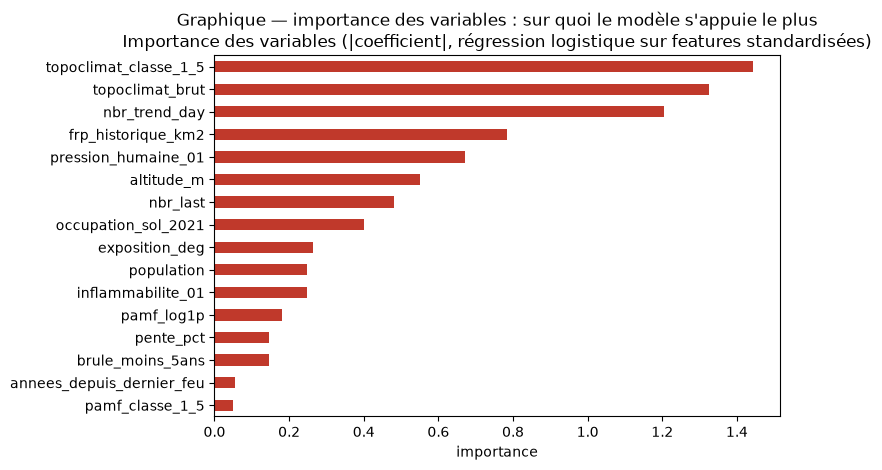

Figure saved: /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/outputs/code207_risque_feu_final/importance_variables_code207.png


In [21]:
# ------------------------------------------------------------------
# code202 : FINAL TRAINING on the training AND validation fires (the model and the alert
# share are already chosen). The TEST fire is still not used.
# ------------------------------------------------------------------
THRESHOLD=None
_incendies_finaux=INCENDIES_ENTRAINEMENT+INCENDIES_VALIDATION
# code204 : `model` (training + validation) and `model_sans_validation` are already trained by executer_decoupage.
joblib.dump({'model':model,'features':FEATURES,'fraction_alerte':FRACTION_ALERTE,'model_type':best_name,
             'incendies_entrainement':INCENDIES_ENTRAINEMENT,'incendies_validation':INCENDIES_VALIDATION,
             'incendie_test':INCENDIE_TEST,'seed_decoupage':SEED_DECOUPAGE},PREP/'modele_code207.joblib')
print('Final model ({}) trained on {} fires: {}. Test fire set aside: {}. Classes:'.format(
      best_name,len(_incendies_finaux),', '.join(_incendies_finaux),INCENDIE_TEST),'')

# ------------------------------------------------------------------
# Feature importance of the final model : what does it actually rely on?
# Useful to spot whether it clings to a single weakly robust factor (e.g. only the PAMF)
# rather than to a coherent set of risk factors.
# ------------------------------------------------------------------
final_estimator=model.named_steps.get('rf') or model.named_steps.get('xgb') or model.named_steps.get('lgbm') or model.named_steps.get('logreg')
if hasattr(final_estimator,'feature_importances_'):
    importances=pd.Series(final_estimator.feature_importances_,index=FEATURES).sort_values(ascending=False)
    imp_title='Feature importance ({})'.format(best_name)
elif hasattr(final_estimator,'coef_'):
    importances=pd.Series(np.abs(final_estimator.coef_[0]),index=FEATURES).sort_values(ascending=False)
    imp_title='Feature importance (|coefficient|, logistic regression on standardised features)'
else:
    importances=None

if importances is not None:
    display(importances.to_frame('importance'))
    fig,ax=plt.subplots(figsize=(8,max(4,len(FEATURES)*0.3)))
    importances.sort_values().plot(kind='barh',ax=ax,color='#c0392b')
    ax.set_title("Chart — feature importance: what the model relies on most\n"+imp_title); ax.set_xlabel('importance')
    plt.tight_layout()
    fig_path=REPORT/'importance_variables_code207.png'
    plt.savefig(fig_path,dpi=200,bbox_inches='tight'); plt.show()
    print('Figure saved:',fig_path)

## Daily weather danger (index separate from the spatial model)


In [22]:
# ------------------------------------------------------------------
# NEW (code106) : DAILY WEATHER DANGER ("which day?"), separate from the spatial model ("where?").
# The weather is the same for the whole forest on a given day : it cannot say WHERE the fire will start,
# but it says WHETHER the day is dangerous. It is compared with the summer days (MOIS_ETE) from 2017 to 2024
# present in the code89 cache (2025 excluded so that it remains a blind test) :
#   for each variable, share of summer days less dangerous than the studied day (0 to 1) ;
#   index = mean of these shares. Classes : low < 0.25 <= moderate < 0.50 <= high < 0.75 <= very high.
# This is a simple, transparent index, not a learned model : with only 8 fire days, a
# "fire day / no-fire day" model would mostly memorize these 8 dates.
# ------------------------------------------------------------------
# code204 : FULL summer climatology (every day from June to September 2017-2024) downloaded in one go
# from Open-Meteo at the center of the forest, instead of the ~20 days present in the code89 cache. Same definitions
# as the daily weather : hourly maximum of temperature, wind and VPD, hourly minimum of humidity.
CLIMATO_CACHE=PREP/'climatologie_ete_2017_2024.parquet'
if CLIMATO_CACHE.exists():
    CLIMATO_ETE=pd.read_parquet(CLIMATO_CACHE)
else:
    _r=requete_avec_reessais('https://archive-api.open-meteo.com/v1/archive',params={
        'latitude':CENTRE_WGS84.y,'longitude':CENTRE_WGS84.x,'start_date':'2017-06-01','end_date':'2024-09-30',
        'hourly':'temperature_2m,relative_humidity_2m,wind_speed_10m','timezone':'Africa/Casablanca'},timeout=180)
    _r.raise_for_status(); _h=_r.json()['hourly']
    _df=pd.DataFrame({'time':pd.to_datetime(_h['time']),'t':_h['temperature_2m'],'hr':_h['relative_humidity_2m'],'v':_h['wind_speed_10m']}).astype({'t':float,'hr':float,'v':float})
    _df['vpd']=.6108*np.exp(17.27*_df.t/(_df.t+237.3))*(1-_df.hr/100)
    _df['date']=_df.time.dt.normalize()
    CLIMATO_ETE=_df.groupby('date').agg(temperature_2m_max=('t','max'),relative_humidity_2m_min=('hr','min'),
                                         wind_speed_10m_max=('v','max'),vpd_max=('vpd','max')).reset_index()
    CLIMATO_ETE=CLIMATO_ETE[CLIMATO_ETE.date.dt.month.isin(MOIS_ETE)].reset_index(drop=True)
    CLIMATO_ETE.to_parquet(CLIMATO_CACHE,index=False)
print("Summer climatology: {} Open-Meteo day(s) (months {}, 2017-2024).".format(len(CLIMATO_ETE),MOIS_ETE))
if len(CLIMATO_ETE)<15:
    print("  WARNING: fewer than 15 summer days in cache - the danger index will be imprecise.")

def indice_danger_jour(frame):
    """Weather danger index (0-1) and its class for one day (frame = cells of that day)."""
    parts={}
    for var,sens in DANGER_VARS.items():
        if var not in frame or var not in CLIMATO_ETE or frame[var].notna().sum()==0: continue
        valeur=float(frame[var].median()); ref=CLIMATO_ETE[var].dropna()
        if ref.empty: continue
        parts[var]=float((ref<=valeur).mean()) if sens>0 else float((ref>=valeur).mean())
    if not parts: return np.nan,'unknown',parts
    indice=float(np.mean(list(parts.values())))
    classe='low' if indice<0.25 else 'moderate' if indice<0.50 else 'high' if indice<0.75 else 'very high'
    return indice,classe,parts

# Check : most of the 8 fire days should come out "high" or "very high", and the negative summer
# days rather lower. If not, the index does not discriminate and DANGER_VARS must be revised.
_controle=[]
for _groupe,_frame in samples.groupby('event_group'):
    _i,_c,_ = indice_danger_jour(_frame)
    _d=pd.Timestamp(_frame.date_modele.iloc[0])
    _controle.append({'journee':_groupe,'date':_d.date(),'jour_de_feu':_groupe.startswith('incendie_'),
                      'ete':_d.month in MOIS_ETE,'indice_danger':_i,'classe':_c})
_controle=pd.DataFrame(_controle).sort_values('indice_danger',ascending=False)
display(_controle)
print("Mean index: fire days = {:.2f} | summer days without fire = {:.2f} | non-summer days without fire = {:.2f}".format(
      _controle[_controle.jour_de_feu].indice_danger.mean(),
      _controle[~_controle.jour_de_feu&_controle.ete].indice_danger.mean(),
      _controle[~_controle.jour_de_feu&~_controle.ete].indice_danger.mean()))


Summer climatology: 976 Open-Meteo day(s) (months [6, 7, 8, 9], 2017-2024).


,journee,date,jour_de_feu,ete,indice_danger,classe
4,incendie_2022,2022-07-25,True,True,0.952869,very high
5,incendie_derdara_2021,2021-08-14,True,True,0.851947,very high
6,incendie_tanaqoub_2019a,2019-08-13,True,True,0.748207,high
1,incendie_2009a,2009-07-26,True,True,0.694160,high
3,incendie_2020,2020-08-25,True,True,0.667777,high
2,incendie_2009bc,2009-08-11,True,True,0.284580,moderate
7,incendie_tanaqoub_2019b,2019-09-13,True,True,0.283555,moderate
0,incendie_2005,2005-09-21,True,True,0.214395,low
8,negatif_2017-09-17,2017-09-17,False,True,NaN,unknown
9,negatif_2018-02-19,2018-02-19,False,False,NaN,unknown


Mean index: fire days = 0.59 | summer days without fire = nan | non-summer days without fire = nan


## Test on the randomly drawn fire (and maps of the 2 validation fires)

The TEST fire was used neither for training nor for model selection: its result is the only truly independent one. The 2 VALIDATION fires were used to choose the model and were added to the final training, so their maps are given for reference only.


In [23]:
# ------------------------------------------------------------------
# Informative confirmation (no longer blocks anything) : the timeline received on 23/09/2026 confirms that
# Derdara 2021 is a real fire (included in training, previous cells) and that the 2
# 2025 dates that seemed to be 2 candidates for a single uncertain fire are in fact 2 distinct fires
# (see EVENEMENTS_2025, cell 2). Here we check the local FIRMS detections for each window for
# reference only - none of these checks modifies the training or the threshold calibration,
# already frozen in the previous cells, so the blind test remains a true blind test.
# ------------------------------------------------------------------
print("Local FIRMS check (indicative) of the fires now confirmed by the external timeline:")
_fenetres_a_verifier=[('Derdara/Sougna 2021',DERDARA_2021_DATE-pd.Timedelta(days=1),DERDARA_2021_DATE+pd.Timedelta(days=5)),
                      ('Tanaqoub aout 2019',FIRE_2019A_DATE-pd.Timedelta(days=1),FIRE_2019A_DATE+pd.Timedelta(days=5)),
                      ('Tanaqoub septembre 2019',FIRE_2019B_DATE-pd.Timedelta(days=1),FIRE_2019B_DATE+pd.Timedelta(days=5)),
                      ('Tanaqoub-Bouhachem 2005',FIRE_2005_DATE-pd.Timedelta(days=1),FIRE_2005_DATE+pd.Timedelta(days=5)),
                      ('Derdara-Jbel Sougna 2009',FIRE_2009A_DATE-pd.Timedelta(days=1),FIRE_2009A_DATE+pd.Timedelta(days=5)),
                      ('Derdara-Bouhachem/Mont Bouhachem 2009 (fusion)',FIRE_2009BC_DATE-pd.Timedelta(days=1),FIRE_2009BC_DATE+pd.Timedelta(days=5))]
_fenetres_a_verifier+=[(e['nom']+' 2025',e['test']-pd.Timedelta(days=3),e['test']+pd.Timedelta(days=3)) for e in EVENEMENTS_2025]
for nom,debut,fin in _fenetres_a_verifier:
    dedans=firms_in_forest[(firms_in_forest.date>=debut)&(firms_in_forest.date<=fin)]
    print('  {:<30} {} -> {} : {} FIRMS detection(s) in the forest.'.format(nom,debut.date(),fin.date(),len(dedans)),
          sorted(dedans.date.dt.date.unique()) if len(dedans) else '(none - small fire often missed by FIRMS, consistent with the timeline)')


Local FIRMS check (indicative) of the fires now confirmed by the external timeline:
  Derdara/Sougna 2021            2021-08-13 -> 2021-08-19 : 109 FIRMS detection(s) in the forest. [datetime.date(2021, 8, 14), datetime.date(2021, 8, 15), datetime.date(2021, 8, 16), datetime.date(2021, 8, 17), datetime.date(2021, 8, 18)]
  Tanaqoub aout 2019             2019-08-12 -> 2019-08-18 : 2 FIRMS detection(s) in the forest. [datetime.date(2019, 8, 14)]
  Tanaqoub septembre 2019        2019-09-12 -> 2019-09-18 : 16 FIRMS detection(s) in the forest. [datetime.date(2019, 9, 13), datetime.date(2019, 9, 14), datetime.date(2019, 9, 15)]
  Tanaqoub-Bouhachem 2005        2005-09-20 -> 2005-09-26 : 0 FIRMS detection(s) in the forest. (none - small fire often missed by FIRMS, consistent with the timeline)
  Derdara-Jbel Sougna 2009       2009-07-25 -> 2009-07-31 : 5 FIRMS detection(s) in the forest. [datetime.date(2009, 7, 28), datetime.date(2009, 7, 29)]
  Derdara-Bouhachem/Mont Bouhachem 2009 (fusion) 

TEST -- fire 2025_bouhachem_pres_derdara (2025-08-21)
Satellite image used: 2025-08-18 (age 3 days).
Unsupervised class centers: {2: 0.2143, 4: 0.6031, 3: 0.3903, 5: 0.8233, 1: 0.0572}
Weather danger of the day: 0.47 (moderate) | alert: top 20 % of cells.
Prediction locked before comparison with the ground truth (SHA-256): 1a40b60836ab92ad42bcf38280086f2446ec5ed405a9a0b3d738818242a8f9ac
Ground truth: 50 burned cells (~312 ha) out of 4905 verifiable cells (out of 6071).
ROC-AUC = 0.521 (0.5 = chance) | PR-AUC = 0.010 for chance at 0.010, i.e. 1.0 x chance.


,Predicted burned (alert),Predicted not burned
Actually burned,7,43
Actually not burned,889,3966


precision = 0.008 (chance 0.010) | recall = 0.140
QGIS layer (EPSG:26191) written: /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/outputs/code207_risque_feu_final/verification_qgis_2025_bouhachem_pres_derdara_code207.gpkg - to overlay on the Sentinel-2 / Landsat image and the FIRMS points.


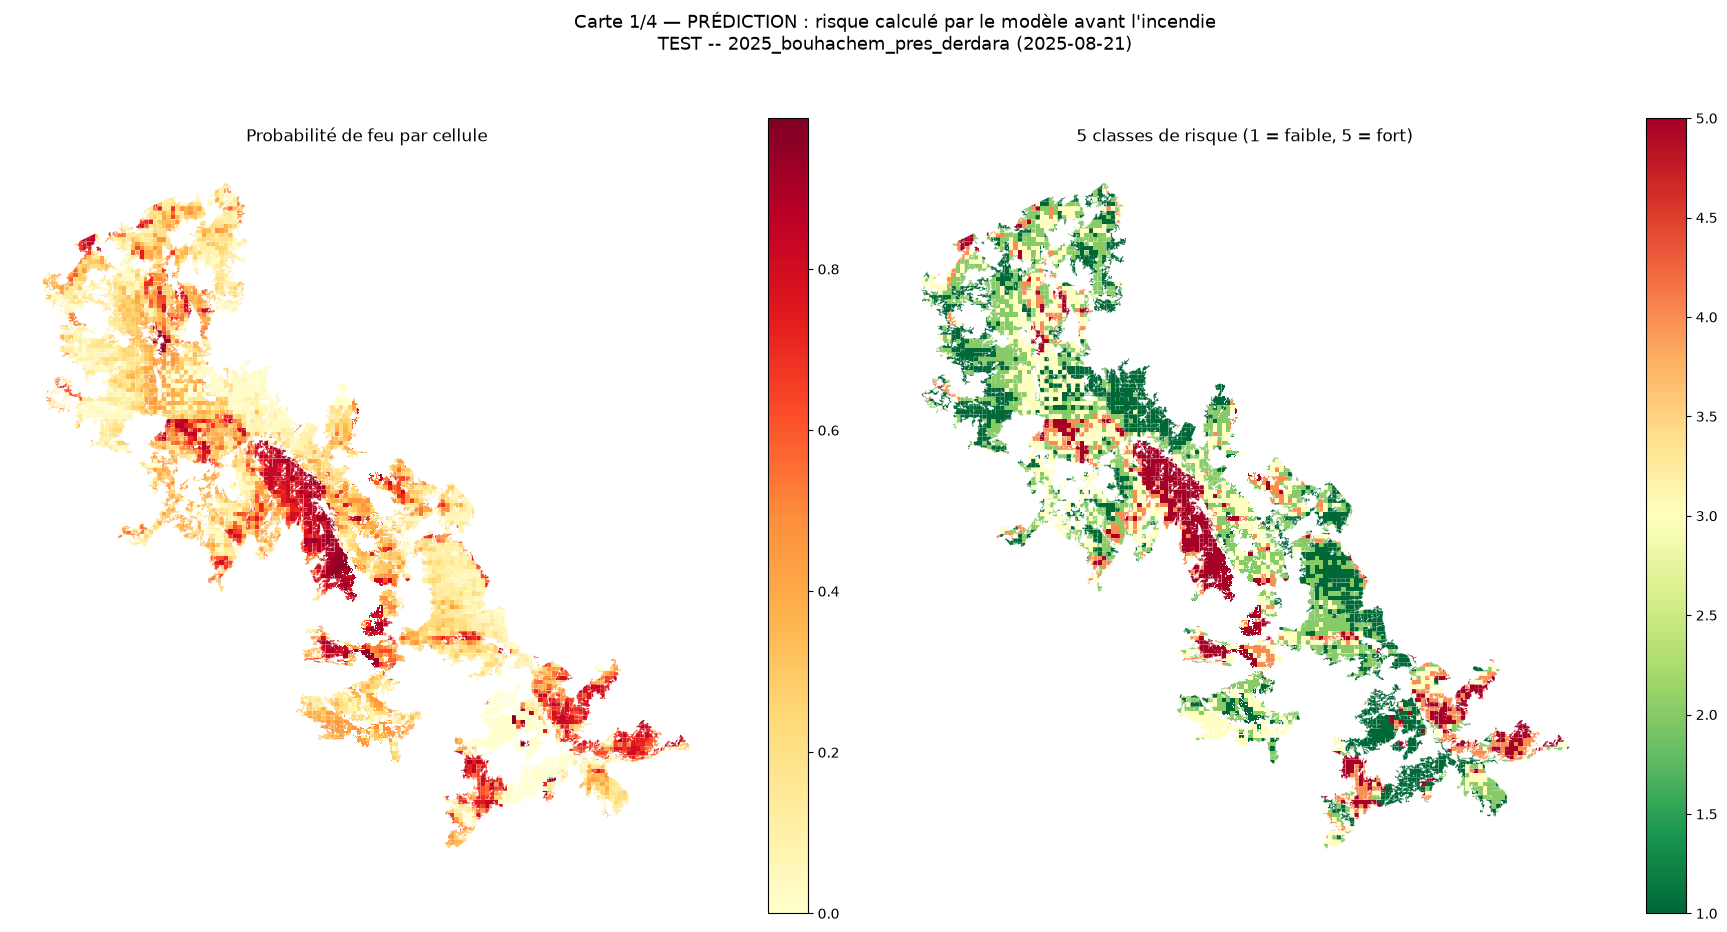

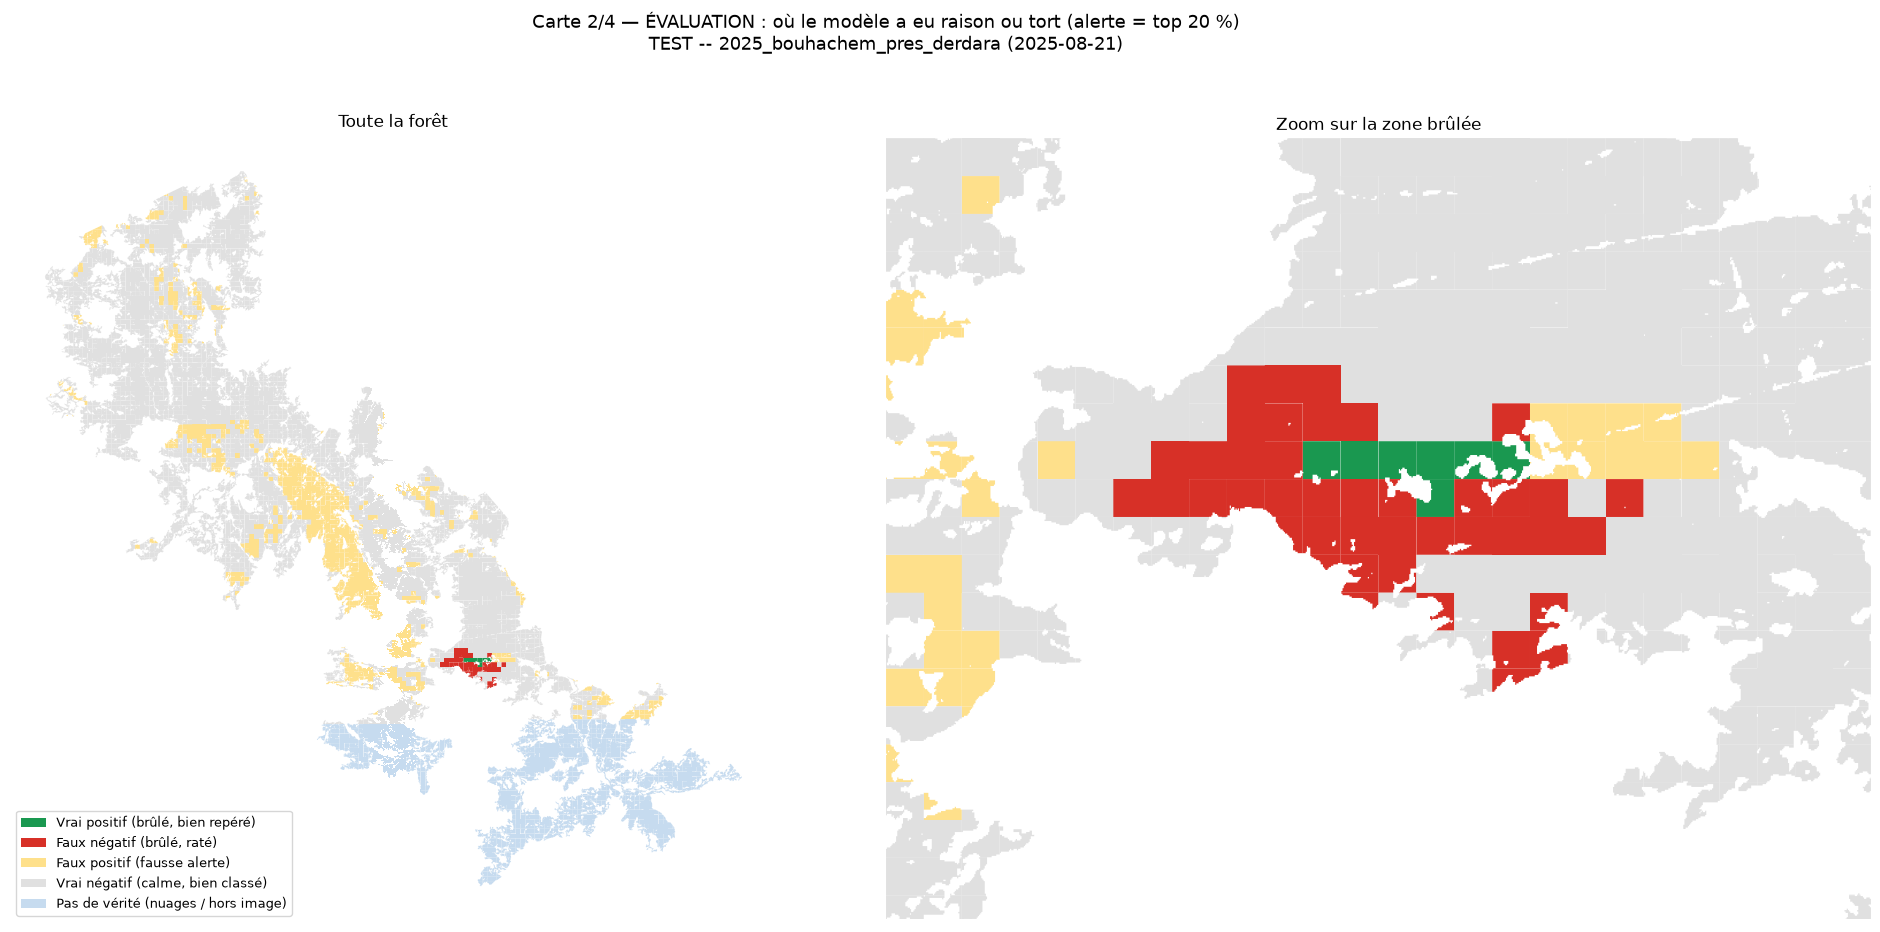

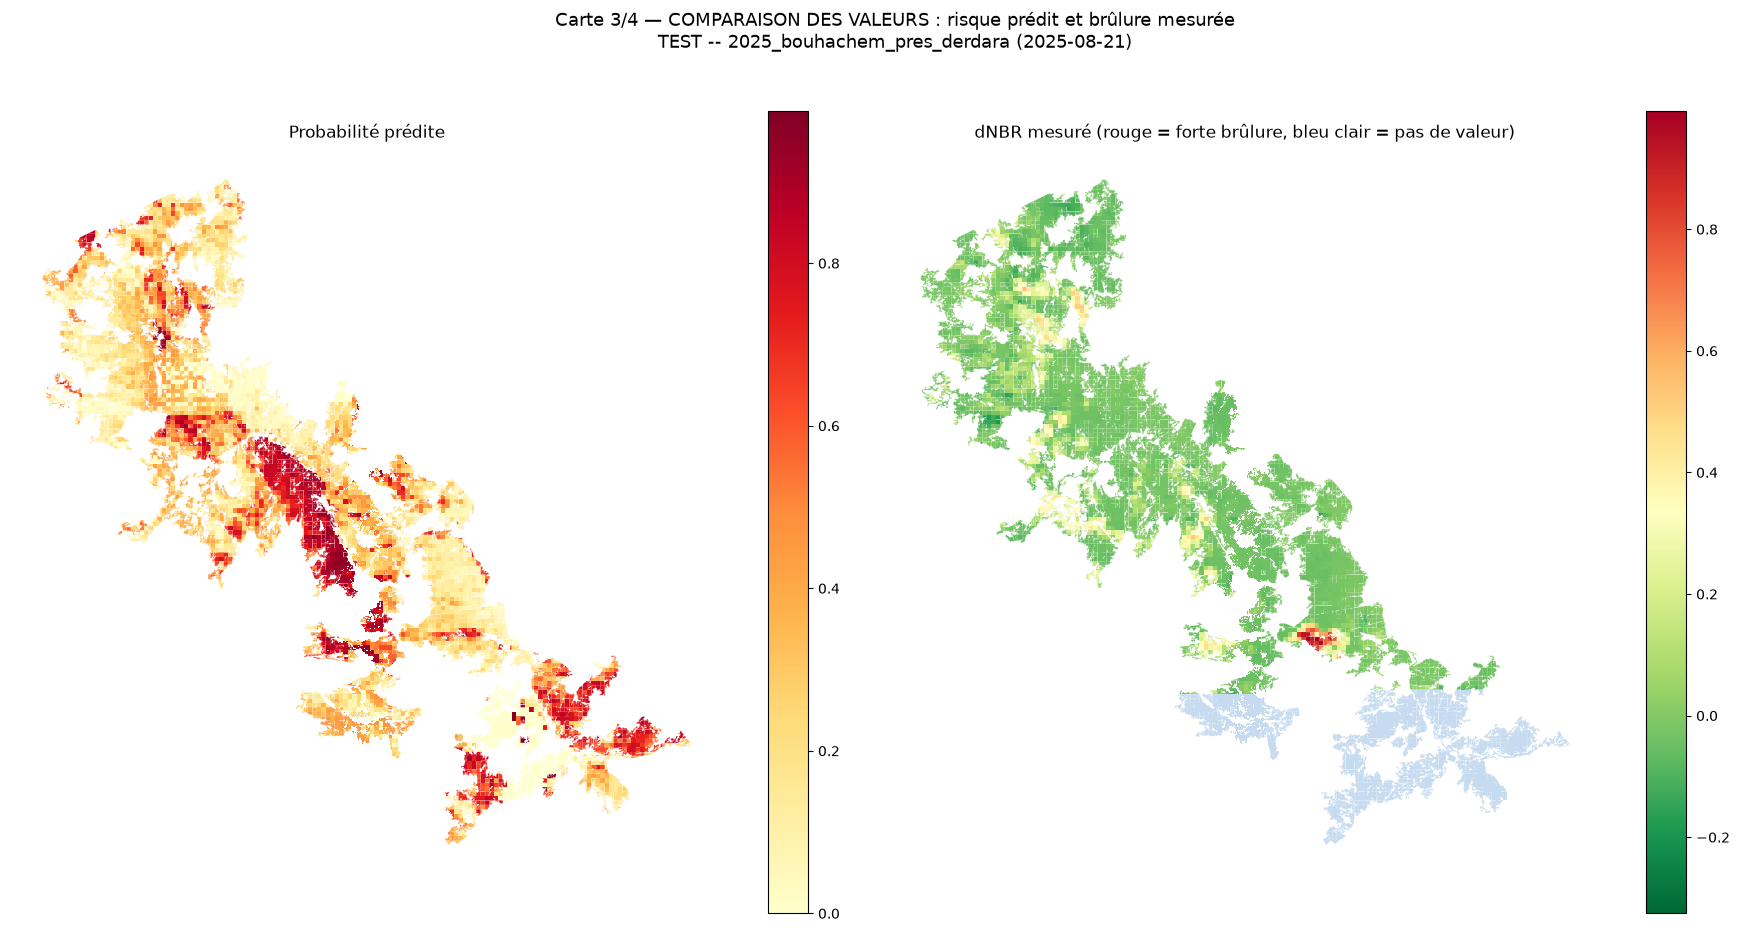

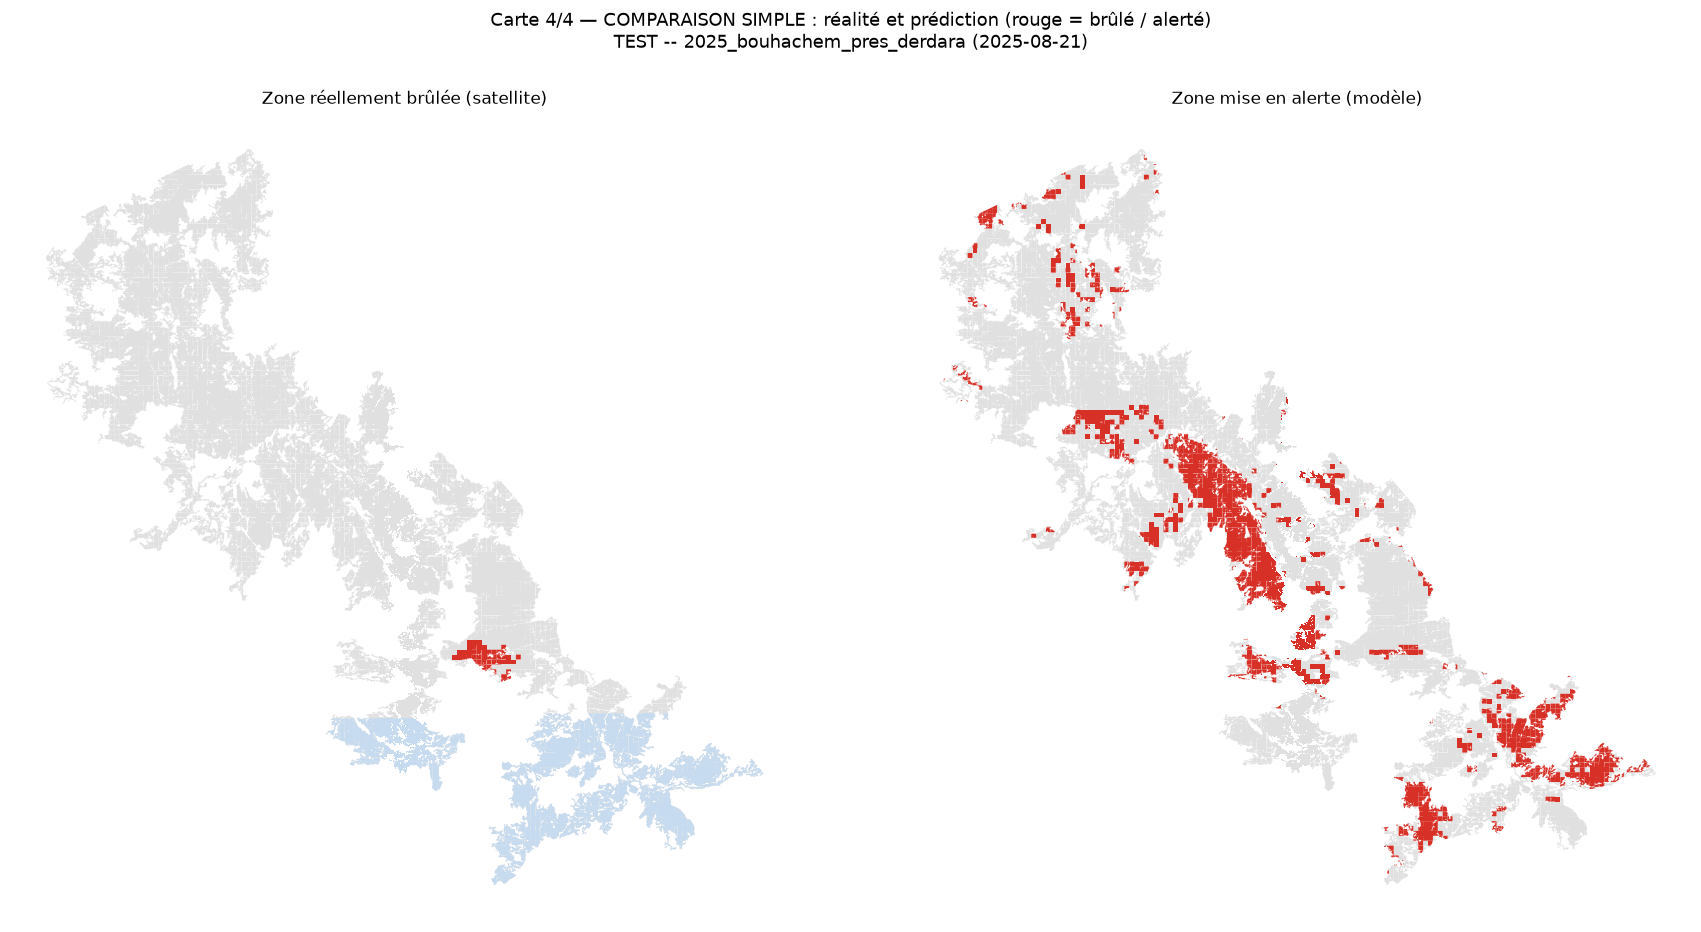

VALIDATION (model trained without this fire) -- fire 2025_derdara (2025-08-12)
Satellite image used: 2025-08-05 (age 7 days).
Unsupervised class centers: {1: 0.0204, 4: 0.5023, 3: 0.3221, 5: 0.7962, 2: 0.1505}
Weather danger of the day: 0.93 (very high) | alert: top 20 % of cells.
Ground truth: 220 burned cells (~1375 ha) out of 2800 verifiable cells (out of 6071).
ROC-AUC = 0.322 (0.5 = chance) | PR-AUC = 0.053 for chance at 0.079, i.e. 0.7 x chance.


,Predicted burned (alert),Predicted not burned
Actually burned,1,219
Actually not burned,533,2047


precision = 0.002 (chance 0.079) | recall = 0.005
QGIS layer (EPSG:26191) written: /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/outputs/code207_risque_feu_final/verification_qgis_2025_derdara_code207.gpkg - to overlay on the Sentinel-2 / Landsat image and the FIRMS points.


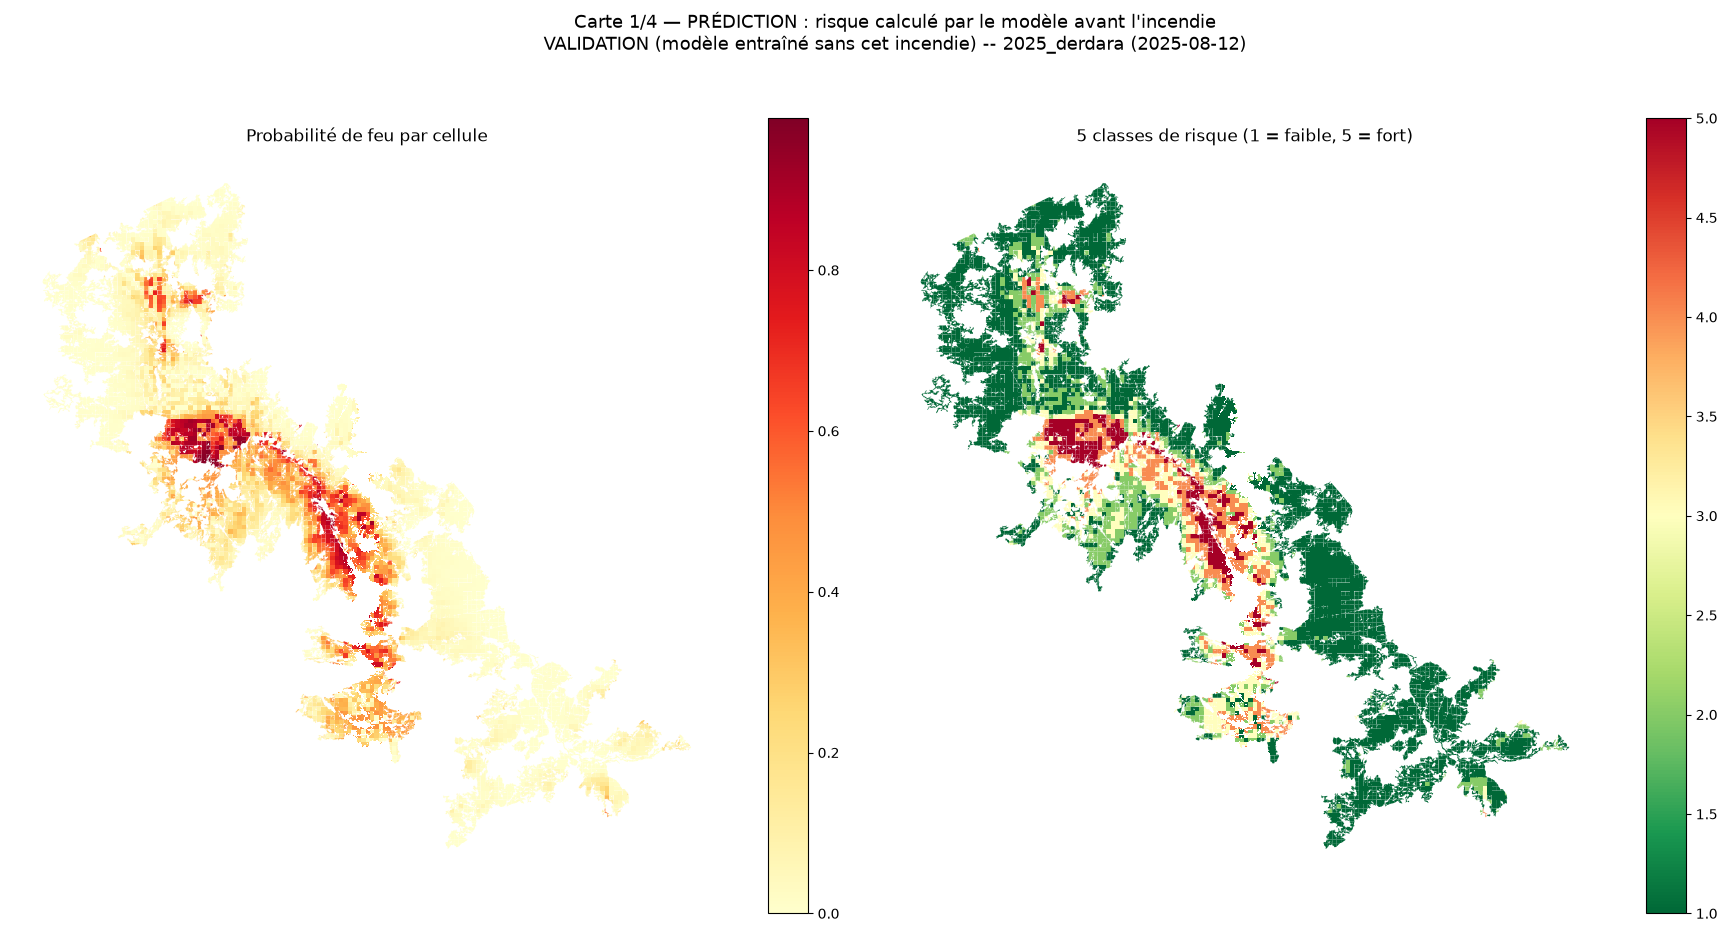

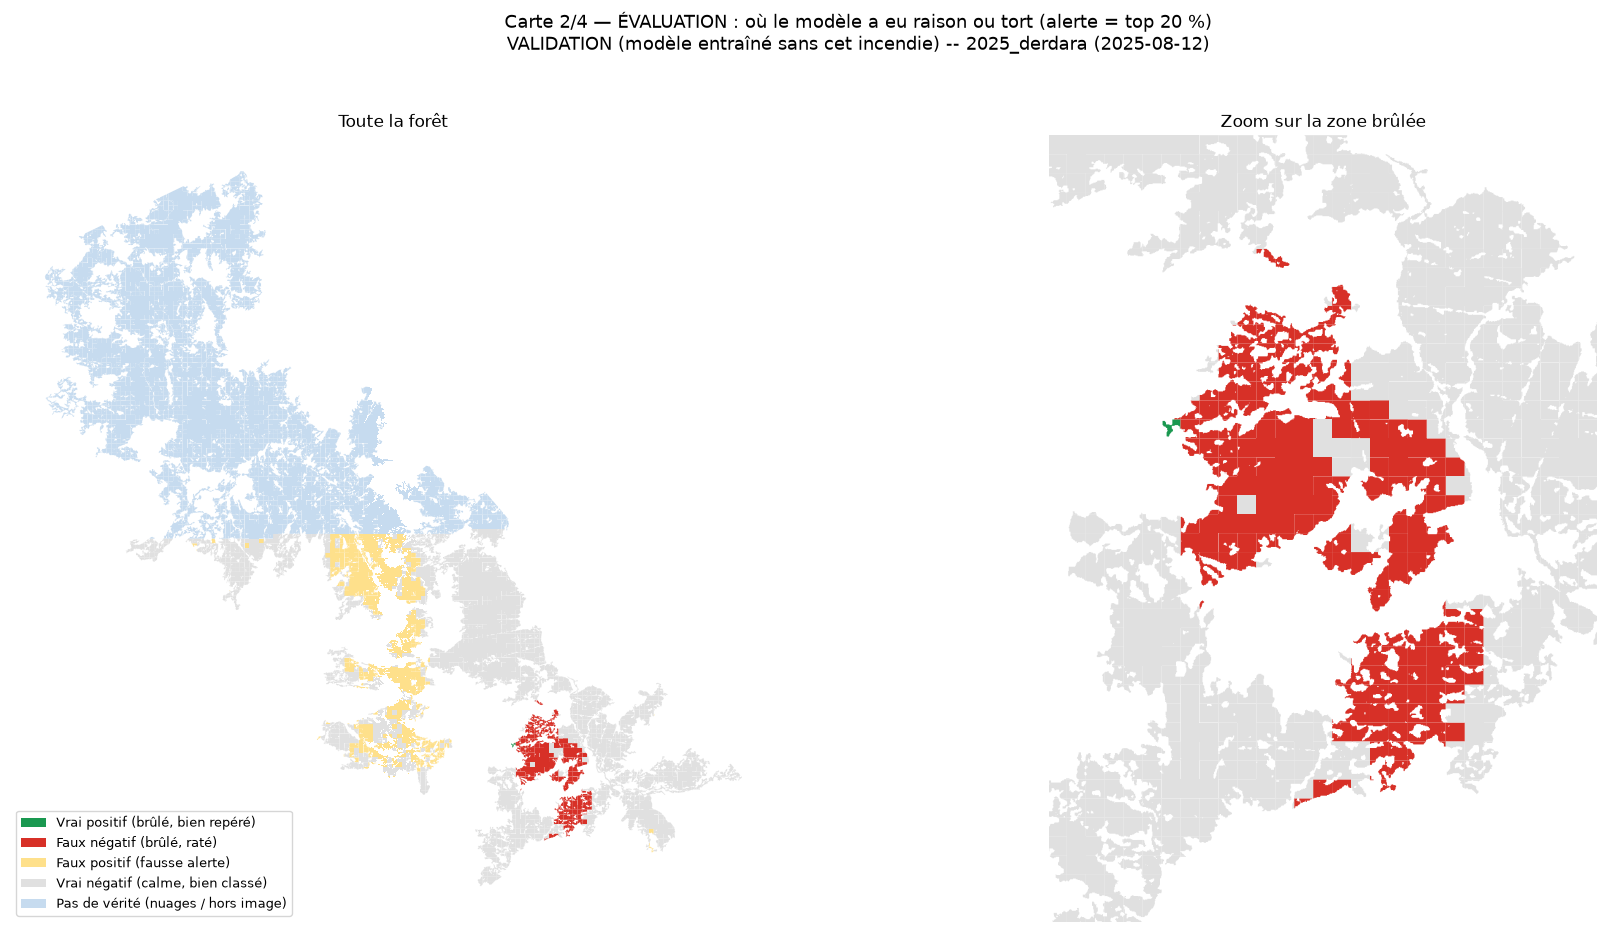

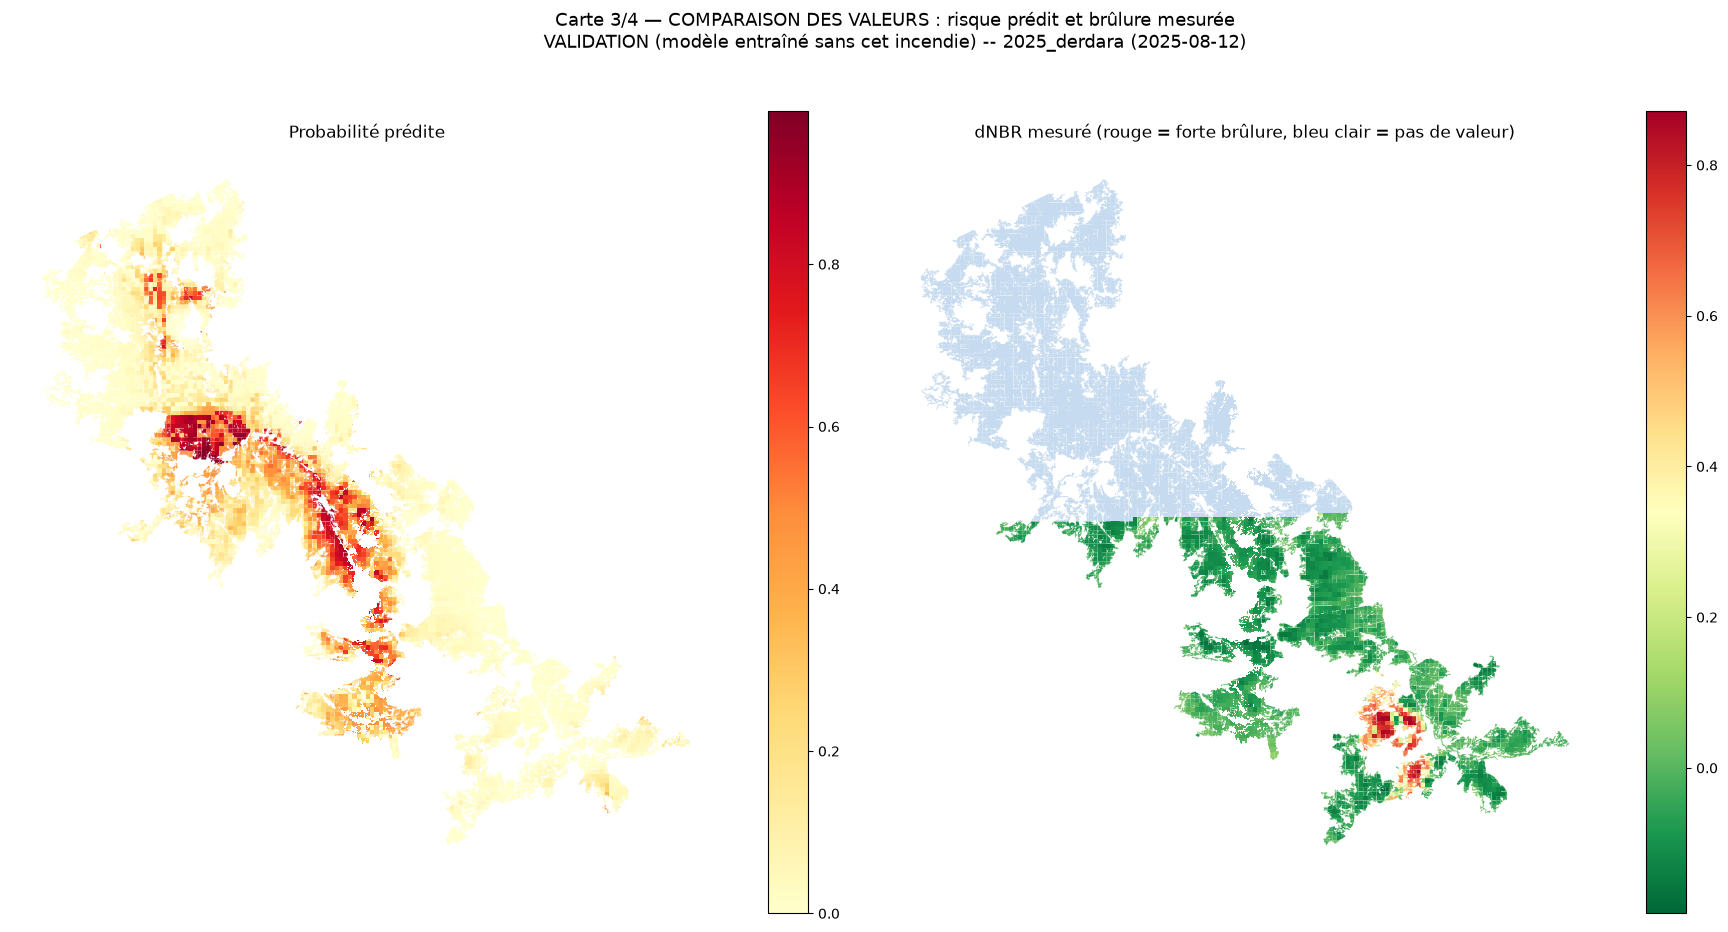

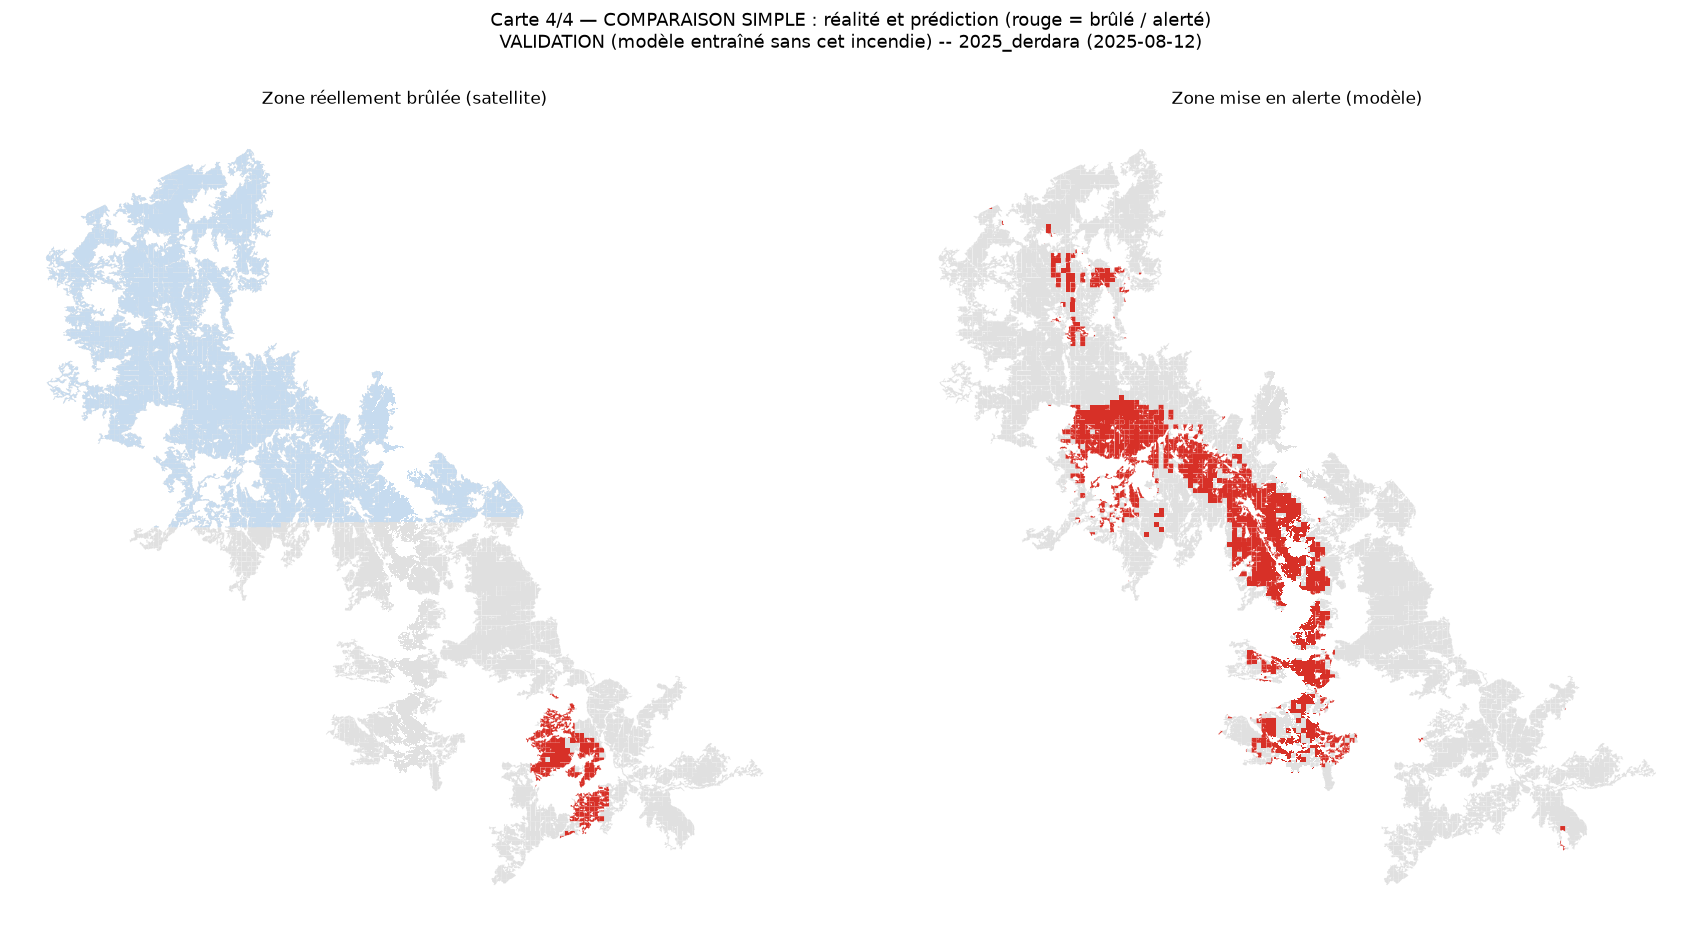

VALIDATION (model trained without this fire) -- fire 2022 (2022-07-25)
Satellite image used: 2022-07-15 (age 10.0 days).
Unsupervised class centers: {1: 0.0327, 3: 0.4231, 5: 0.8546, 2: 0.2109, 4: 0.6475}
Weather danger of the day: 0.95 (very high) | alert: top 20 % of cells.
Ground truth: 928 burned cells (~5800 ha) out of 6071 verifiable cells (out of 6071).
ROC-AUC = 0.729 (0.5 = chance) | PR-AUC = 0.277 for chance at 0.153, i.e. 1.8 x chance.


,Predicted burned (alert),Predicted not burned
Actually burned,377,551
Actually not burned,838,4305


precision = 0.310 (chance 0.153) | recall = 0.406
QGIS layer (EPSG:26191) written: /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/outputs/code207_risque_feu_final/verification_qgis_2022_code207.gpkg - to overlay on the Sentinel-2 / Landsat image and the FIRMS points.


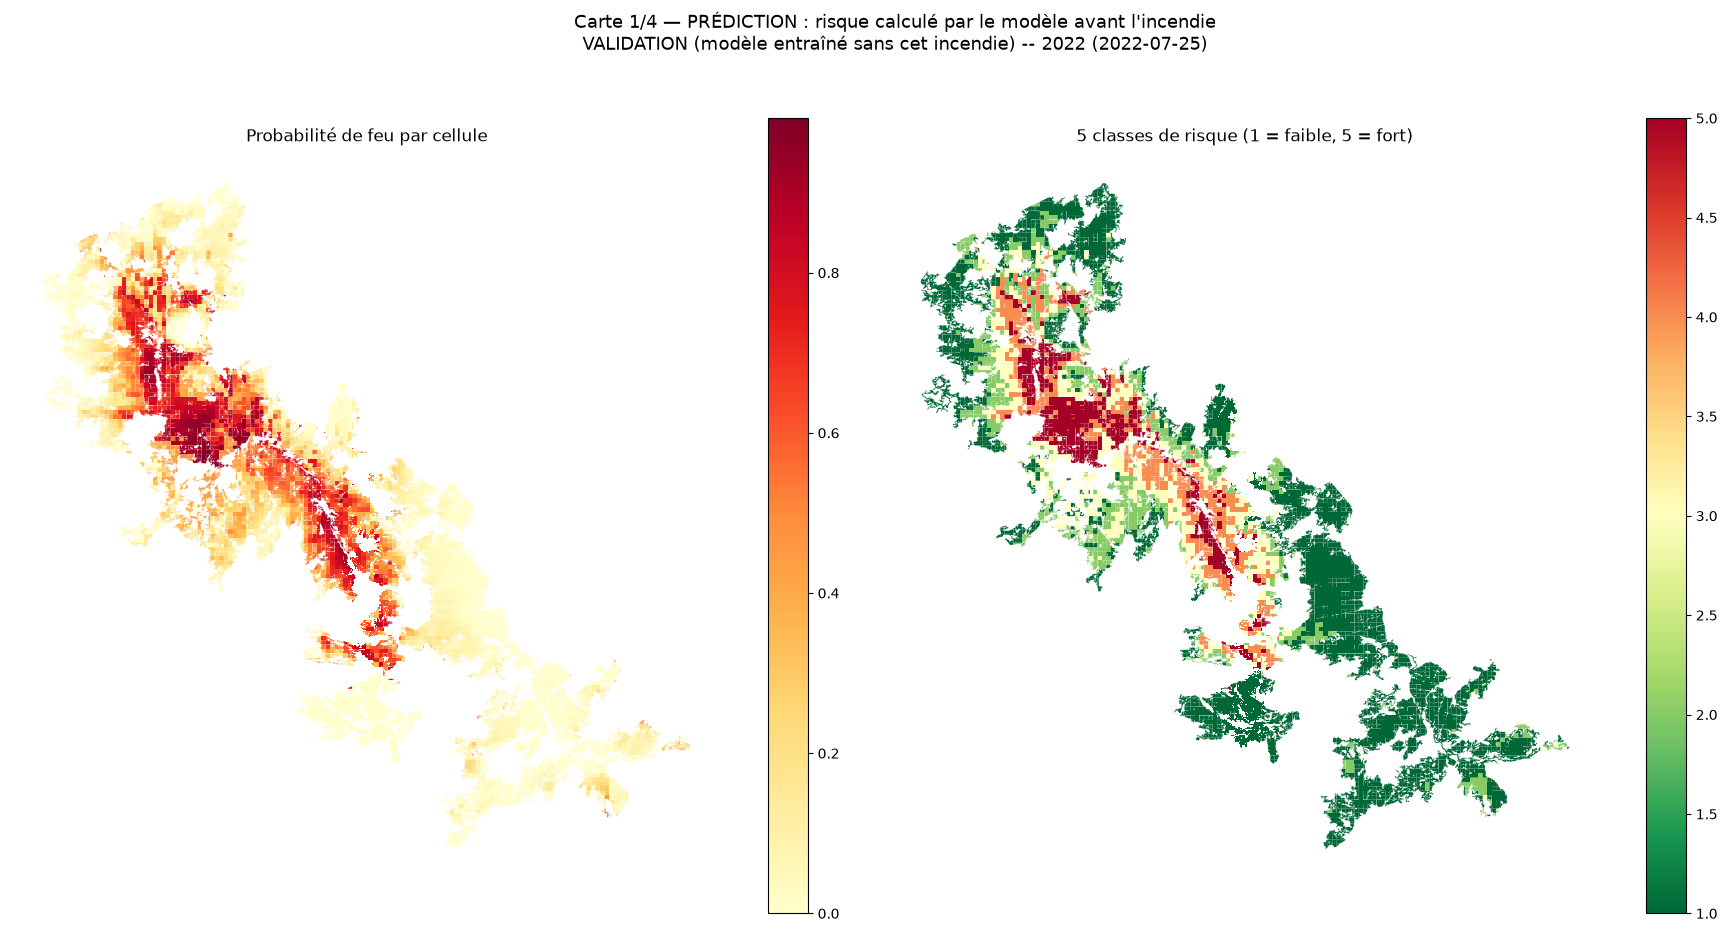

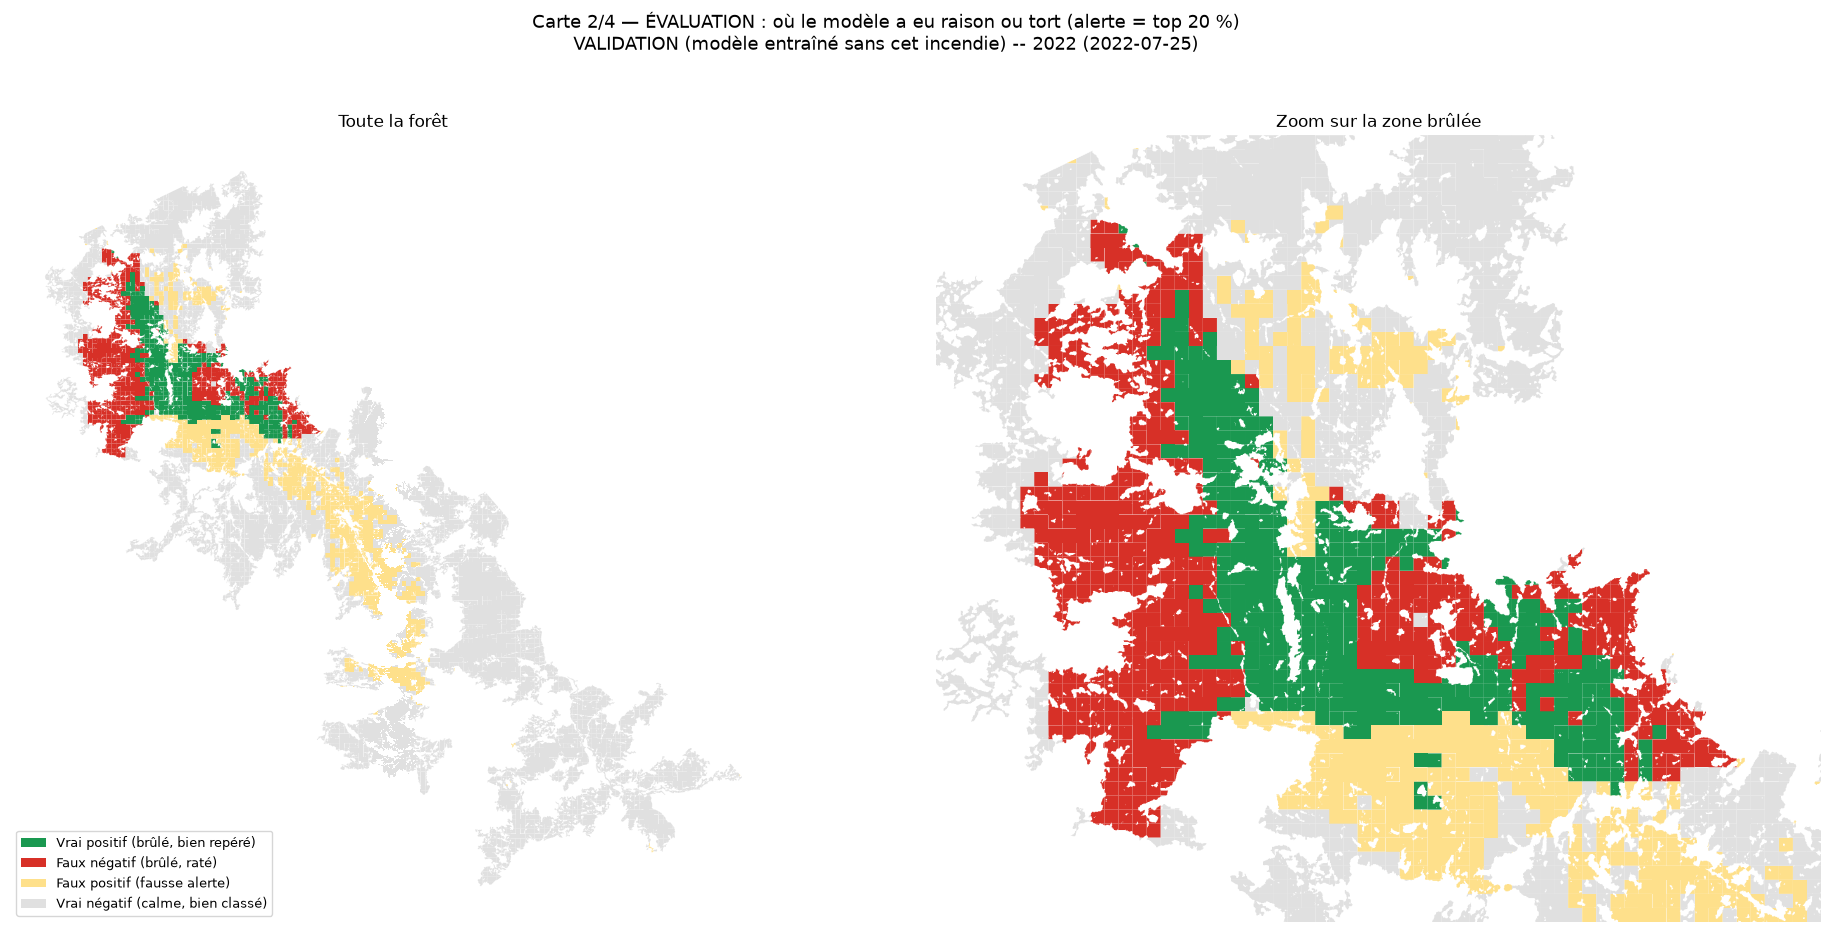

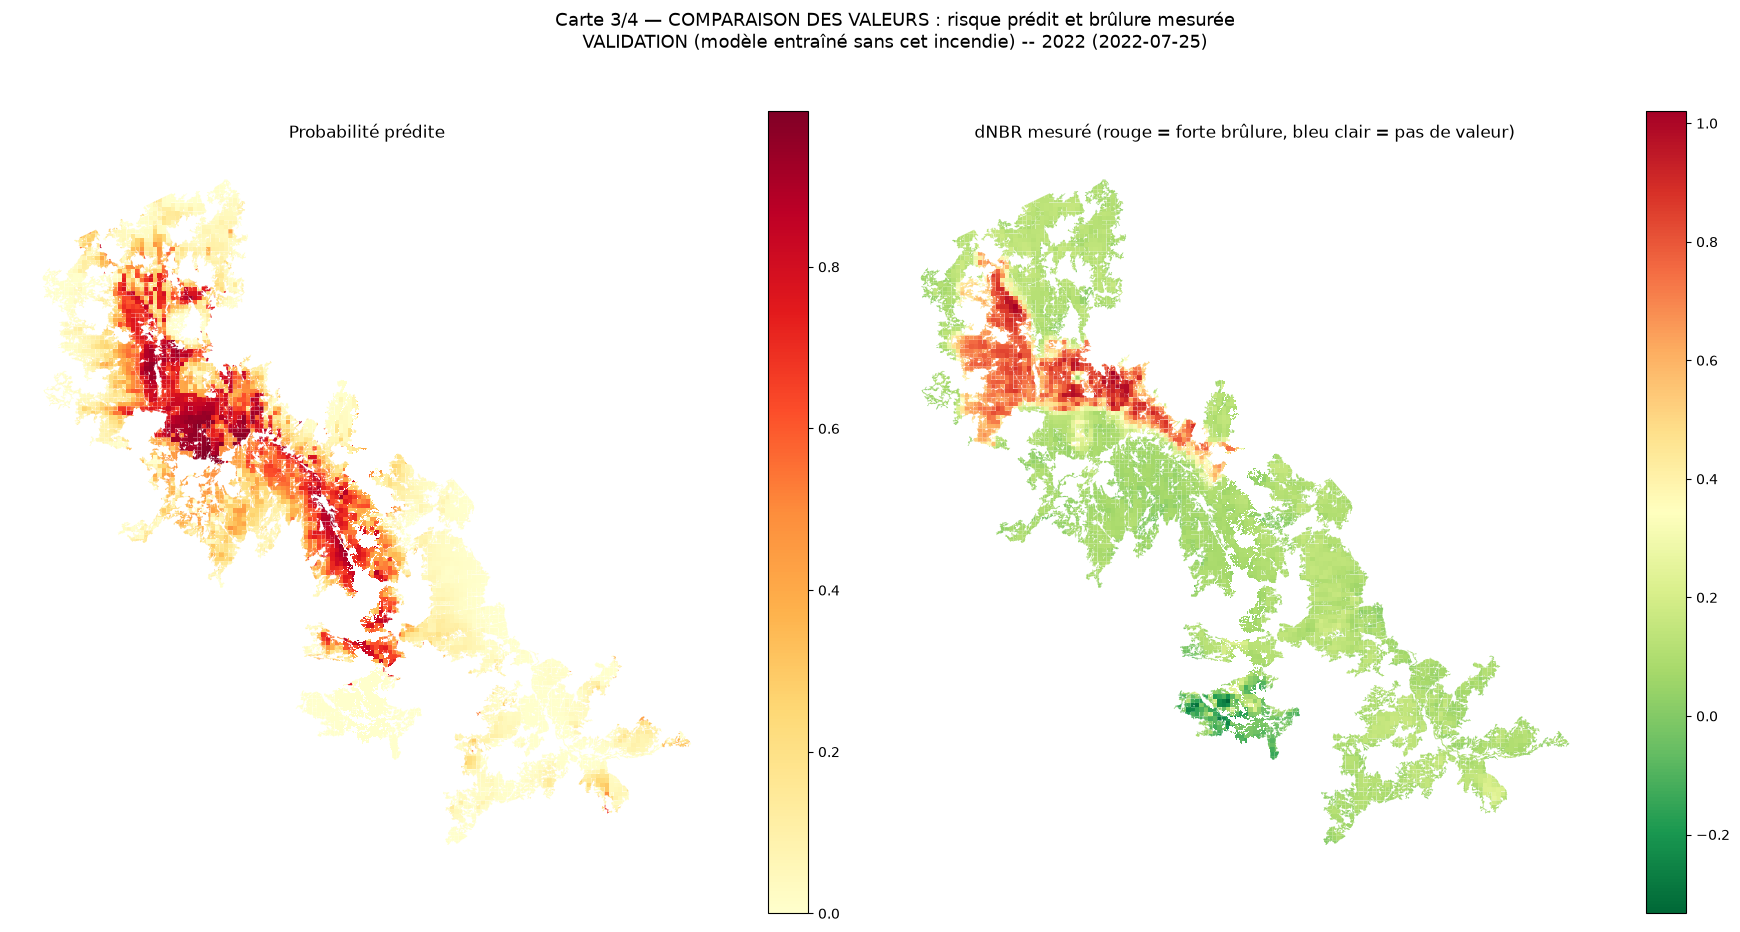

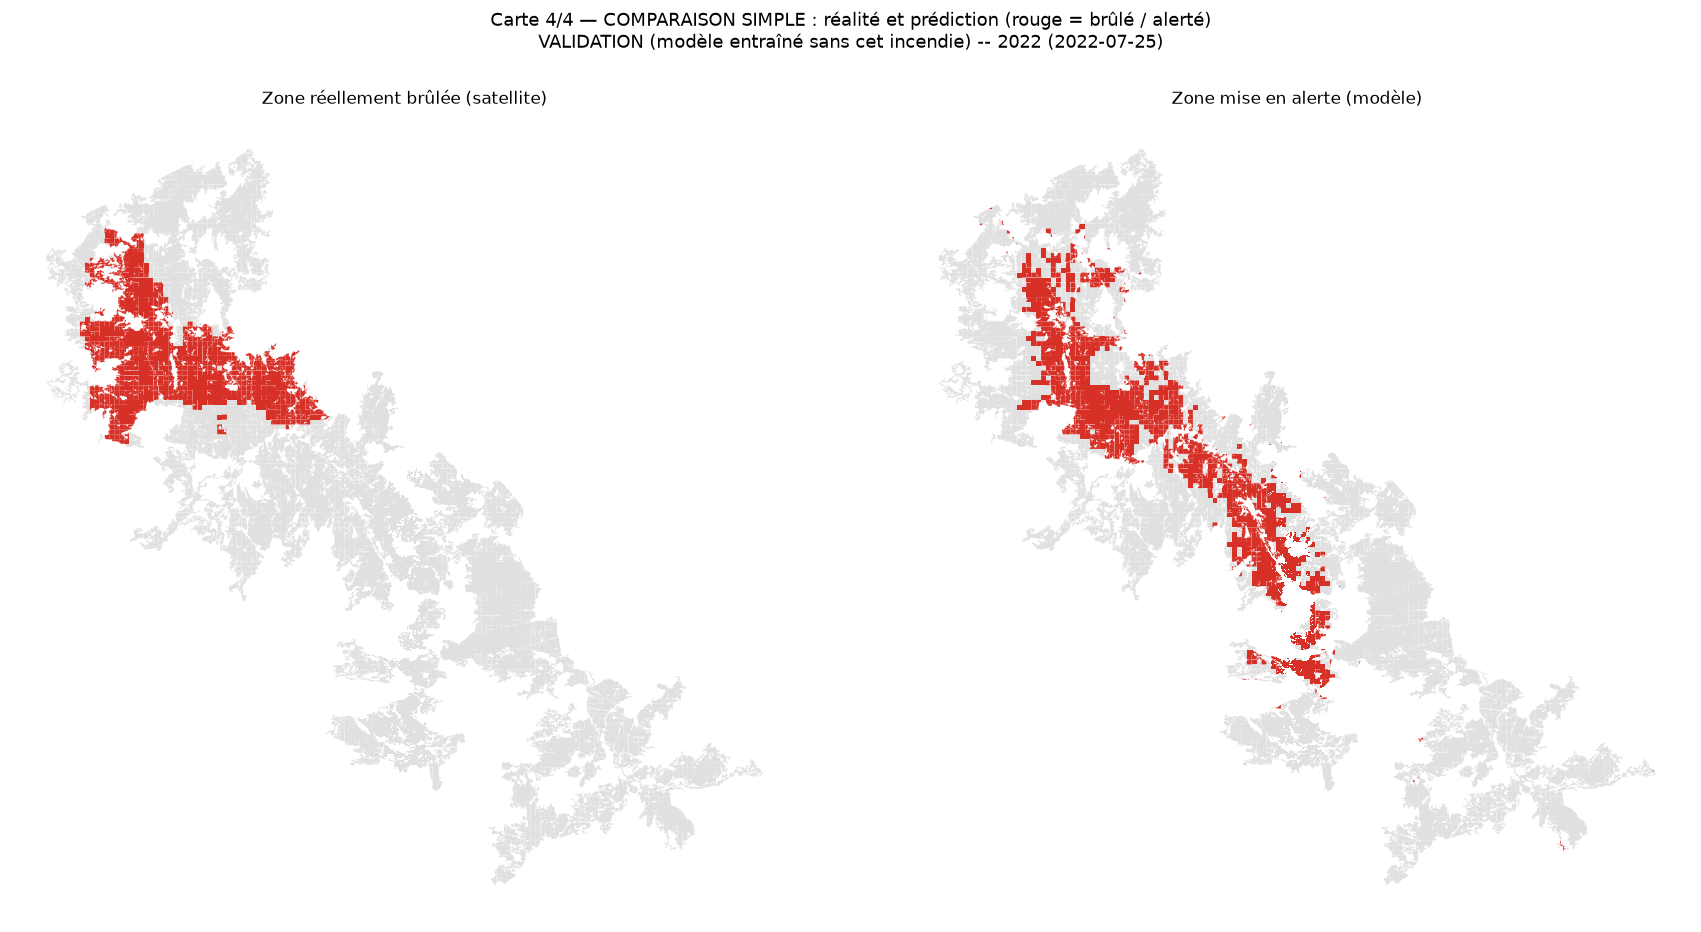

Summary of the presented split (each fire is evaluated by a model that has never seen it):


,incendie,role,ROC_AUC,PR_lift,VP,FN,FP,VN
0,2025_bouhachem_pres_derdara,TEST,0.521294,0.979520,7,43,889,3966
1,2025_derdara,VALIDATION (model trained without this fire),0.321751,0.680033,1,219,533,2047
2,2022,VALIDATION (model trained without this fire),0.729286,1.815205,377,551,838,4305


In [24]:
def cadre_complet(nom):
    """All the forest cells for this fire (including those without a valid dNBR), with the label
    and the dNBR value, so that the maps can be drawn over the whole forest."""
    if nom in CADRES_2025:
        f=CADRES_2025[nom].copy()
    else:
        f=samples[samples.event_group=='incendie_'+nom].reset_index(drop=True).copy()
        valeurs=globals().get('dnbr_values_'+EVENEMENTS_DNBR[nom]['var'])
        f['dnbr']=valeurs if valeurs is not None and len(valeurs)==len(f) else np.nan
    if 'annees_depuis_dernier_feu' not in f: f=ajouter_historique(f,f.date_modele.iloc[0])   # code205
    return gpd.GeoDataFrame(f,geometry='geometry',crs=CRS)

def evaluer_incendie(nom,role,modele=None):
    """Prediction, figures and 4 maps for a TEST or VALIDATION fire, over the whole forest."""
    f=cadre_complet(nom); date=pd.Timestamp(f.date_modele.iloc[0]).date()
    print('='*100); print('{} -- fire {} ({})'.format(role,nom,date)); print('='*100)
    print('Satellite image used: {} (age {} days).'.format(
          f['satellite_date'].iloc[0] if 'satellite_date' in f else 'unknown',f['image_age_days'].iloc[0] if 'image_age_days' in f else '?'))
    modele=modele if modele is not None else model
    f['probabilite_feu']=predire(modele,f)   # code206 : fuel rule applied
    seuil=float(np.quantile(f.probabilite_feu,1-FRACTION_ALERTE))
    f['prediction_feu']=(f.probabilite_feu>=seuil).astype('uint8')
    f['classe_risque']=classes_risque_non_supervisees(f.probabilite_feu,5)
    danger,classe_danger,_=indice_danger_jour(f)
    print('Weather danger of the day: {:.2f} ({}) | alert: top {:.0f} % of cells.'.format(danger,classe_danger,100*FRACTION_ALERTE))
    if role=='TEST':
        chemin=PREP/f'prediction_test_{nom}_code207.csv'; f.drop(columns='geometry').drop(columns=['fire_today','dnbr'],errors='ignore').to_csv(chemin,index=False)
        print('Prediction locked before comparison with the ground truth (SHA-256):',hashlib.sha256(chemin.read_bytes()).hexdigest())

    valide=np.isfinite(f['dnbr'].to_numpy(dtype=float)) if f['dnbr'].notna().any() else np.ones(len(f),bool)
    y=f.fire_today.to_numpy()[valide].astype(int); p=f.probabilite_feu.to_numpy()[valide]; a=f.prediction_feu.to_numpy()[valide]
    hasard=y.mean()
    print('Ground truth: {} burned cells (~{:.0f} ha) out of {} verifiable cells (out of {}).'.format(int(y.sum()),y.sum()*CELL_HA,int(valide.sum()),len(f)))
    print('ROC-AUC = {:.3f} (0.5 = chance) | PR-AUC = {:.3f} for chance at {:.3f}, i.e. {:.1f} x chance.'.format(
          roc_auc_score(y,p),average_precision_score(y,p),hasard,average_precision_score(y,p)/hasard))
    vp=int(((a==1)&(y==1)).sum()); fn=int(((a==0)&(y==1)).sum()); fp=int(((a==1)&(y==0)).sum()); vn=int(((a==0)&(y==0)).sum())
    display(pd.DataFrame([[vp,fn],[fp,vn]],index=['Actually burned','Actually not burned'],columns=['Predicted burned (alert)','Predicted not burned']))
    print('precision = {:.3f} (chance {:.3f}) | recall = {:.3f}'.format(vp/max(vp+fp,1),hasard,vp/max(vp+fn,1)))

    f['verite_valide']=valide; brule=(f.fire_today==1).to_numpy(); alerte=(f.prediction_feu==1).to_numpy()
    f['categorie']=np.select([~valide,alerte&brule,~alerte&brule,alerte&~brule],
        ['No ground truth (clouds / outside image)','True positive (burned, detected)','False negative (burned, missed)','False positive (false alarm)'],
        default='True negative (calm, correctly classed)')
    couleurs={'True positive (burned, detected)':'#1a9850','False negative (burned, missed)':'#d73027','False positive (false alarm)':'#fee08b',
              'True negative (calm, correctly classed)':'#e0e0e0','No ground truth (clouds / outside image)':'#c6dbef'}
    etiquette='{} -- {} ({})'.format(role,nom,date)
    # code203 : verification layer for QGIS, in Merchich / North Morocco (EPSG:26191)
    _gpkg=REPORT/f'verification_qgis_{nom}_code207.gpkg'
    if _gpkg.exists(): _gpkg.unlink()
    f[['id_cell','partie','probabilite_feu','prediction_feu','fire_today','dnbr','categorie','geometry']].to_crs(CRS).to_file(_gpkg,layer='cellules',driver='GPKG')
    print('QGIS layer (EPSG:26191) written:',_gpkg,'- to overlay on the Sentinel-2 / Landsat image and the FIRMS points.')

    fig,axes=plt.subplots(1,2,figsize=(18,9))
    f.plot(column='probabilite_feu',cmap='YlOrRd',legend=True,ax=axes[0]); f.plot(column='classe_risque',cmap='RdYlGn_r',vmin=1,vmax=5,legend=True,ax=axes[1])
    axes[0].set_title('Fire probability per cell'); axes[1].set_title('5 risk classes (1 = low, 5 = high)')
    fig.suptitle("Map 1/4 — PREDICTION: risk computed by the model before the fire\n"+etiquette,fontsize=13,y=1.03)
    for ax in axes: ax.set_axis_off()
    plt.tight_layout(); plt.savefig(REPORT/f'carte1_prediction_{nom}_code207.png',dpi=200,bbox_inches='tight'); plt.show()

    fig,axes=plt.subplots(1,2,figsize=(20,9))
    for ax in axes:
        for cat,coul in couleurs.items():
            s=f[f.categorie==cat]
            if len(s): s.plot(ax=ax,color=coul,label=cat)
        ax.set_axis_off()
    axes[0].legend(loc='lower left',fontsize=9); axes[0].set_title('Whole forest')
    if brule.any():
        xmin,ymin,xmax,ymax=f[brule].total_bounds; axes[1].set_xlim(xmin-1500,xmax+1500); axes[1].set_ylim(ymin-1500,ymax+1500)
    axes[1].set_title('Zoom on the burned area')
    fig.suptitle("Map 2/4 — EVALUATION: where the model was right or wrong (alert = top {:.0f} %)\n".format(100*FRACTION_ALERTE)+etiquette,fontsize=13,y=1.03)
    plt.tight_layout(); plt.savefig(REPORT/f'carte2_evaluation_{nom}_code207.png',dpi=200,bbox_inches='tight'); plt.show()

    fig,axes=plt.subplots(1,2,figsize=(18,9))
    f.plot(column='probabilite_feu',cmap='YlOrRd',legend=True,ax=axes[0])
    f.plot(column='dnbr',cmap='RdYlGn_r',legend=True,ax=axes[1],missing_kwds={'color':'#c6dbef'})
    axes[0].set_title('Predicted probability'); axes[1].set_title('Measured dNBR (red = severe burn, light blue = no value)')
    for ax in axes: ax.set_axis_off()
    fig.suptitle('Map 3/4 — VALUE COMPARISON: predicted risk and measured burn\n'+etiquette,fontsize=13,y=1.03)
    plt.tight_layout(); plt.savefig(REPORT/f'carte3_valeurs_{nom}_code207.png',dpi=200,bbox_inches='tight'); plt.show()

    fig,axes=plt.subplots(1,2,figsize=(18,9))
    for ax,col,titre in [(axes[0],'fire_today','Area actually burned (satellite)'),(axes[1],'prediction_feu','Area put on alert (model)')]:
        f[f[col]==0].plot(ax=ax,color='#e0e0e0'); s=f[f[col]==1]
        if len(s): s.plot(ax=ax,color='#d73027')
        if col=='fire_today' and (~valide).any(): f[~valide].plot(ax=ax,color='#c6dbef')
        ax.set_title(titre); ax.set_axis_off()
    fig.suptitle('Map 4/4 — SIMPLE COMPARISON: reality and prediction (red = burned / alerted)\n'+etiquette,fontsize=13,y=1.03)
    plt.tight_layout(); plt.savefig(REPORT/f'carte4_realite_vs_predit_{nom}_code207.png',dpi=200,bbox_inches='tight'); plt.show()
    return {'incendie':nom,'role':role,'ROC_AUC':roc_auc_score(y,p),'PR_lift':average_precision_score(y,p)/hasard,'VP':vp,'FN':fn,'FP':fp,'VN':vn}

bilan=[evaluer_incendie(INCENDIE_TEST,'TEST')]+[evaluer_incendie(n,'VALIDATION (model trained without this fire)',model_sans_validation) for n in INCENDIES_VALIDATION]
print('Summary of the presented split (each fire is evaluated by a model that has never seen it):')
display(pd.DataFrame(bilan))


## Annual susceptibility map with fire history

Learned year by year (2017-2024) on the FIRMS points, with years since the last fire as a variable. Validated by excluding one whole year at a time, then tested on 2025.


  2017 : 14 FIRMS points, 12 cells with fire
  2018 : 1 FIRMS points, 1 cells with fire
  2019 : 9 FIRMS points, 8 cells with fire
  2020 : 119 FIRMS points, 103 cells with fire
  2021 : 82 FIRMS points, 75 cells with fire
  2022 : 143 FIRMS points, 134 cells with fire
  2023 : 9 FIRMS points, 7 cells with fire
  2024 : 5 FIRMS points, 5 cells with fire
"One year out" validation (2017-2024):


,model,ROC_AUC_global,PR_lift,ROC_AUC_moyen_par_annee,ROC_2017,ROC_2018,ROC_2019,ROC_2020,ROC_2021,ROC_2022,ROC_2023,ROC_2024
0,Logistic regression,0.603253,1.323211,0.636677,0.80137,0.896376,0.970683,0.634133,0.662199,0.592326,0.403953,0.132377
1,RandomForest (regularised),0.544720,1.057353,0.605260,0.66536,0.941021,0.903266,0.461432,0.694456,0.652137,0.364964,0.159446


Unsupervised class centers: {2: 0.1734, 4: 0.4605, 3: 0.3054, 1: 0.0589, 5: 0.6949}
INDEPENDENT TEST 2025 (Logistic regression, trained on 2017-2024 with fire history):


,ground truth 2025,cellules_feu,ROC_AUC,PR_lift,rappel_top20,precision_top20,precision_hasard
0,FIRMS points 2025 (41 points) - without rule,39,0.332849,0.703839,0.000000,0.000000,0.006424
1,FIRMS points 2025 (41 points) - with rule,39,0.388849,0.760674,0.025641,0.000823,0.006424
2,dNBR burned area 2025_derdara,220,0.507865,0.934264,0.122727,0.048214,0.078571
3,dNBR burned area 2025_bouhachem_pres_derdara,50,0.447778,0.845367,0.000000,0.000000,0.010194


,importance
combustibilite_01,1.412502
pression_humaine_01,1.182274
altitude_m,1.016675
distance_batiment_m,0.926118
population,0.706440
distance_piste_m,0.633209
distance_route_m,0.503421
distance_agriculture_m,0.494779
brule_moins_5ans,0.428109
distance_douar_m,0.405481


Sign of the effect of annees_depuis_dernier_feu: negative (positive = an area burned long ago is more susceptible).


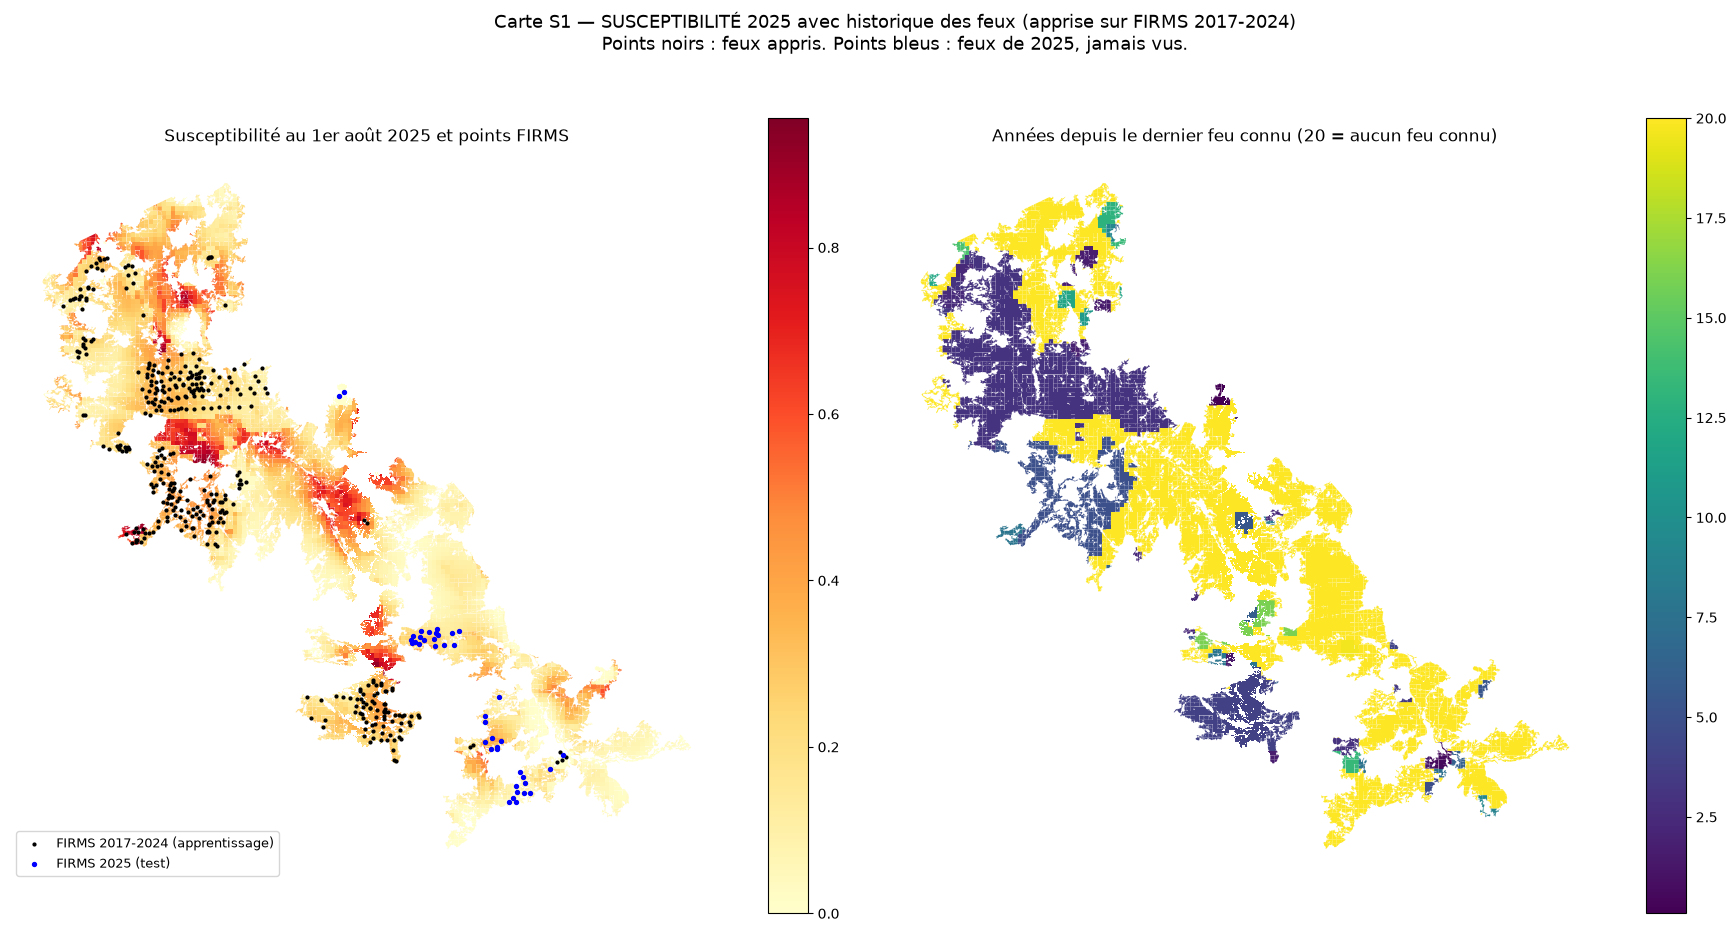

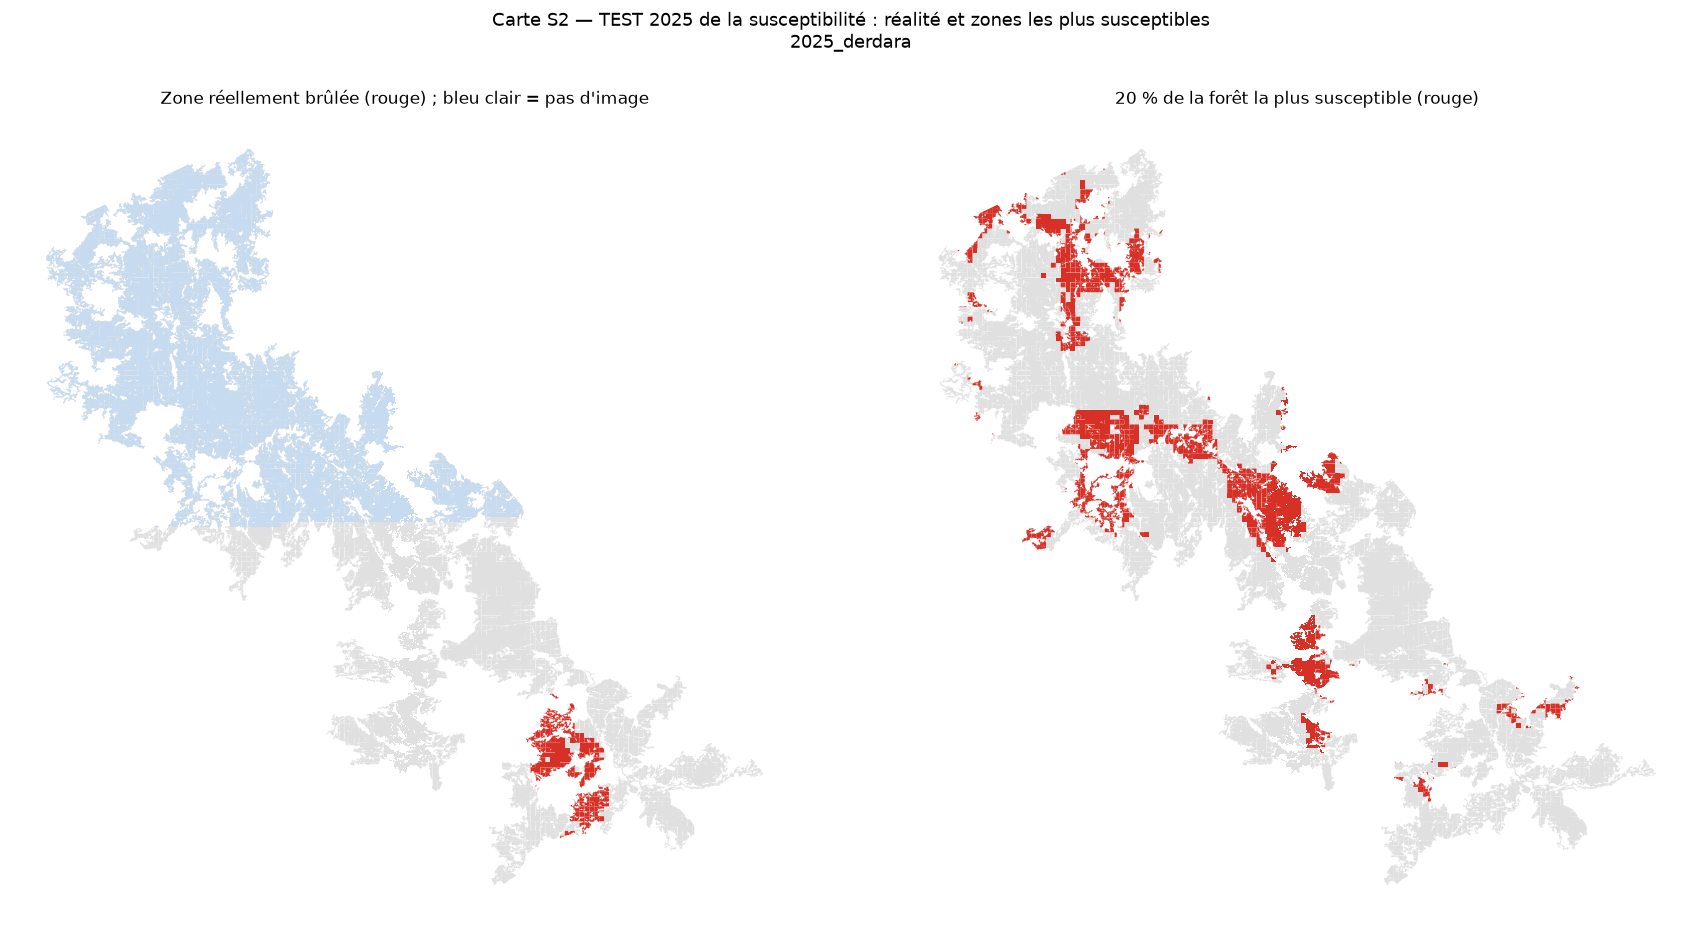

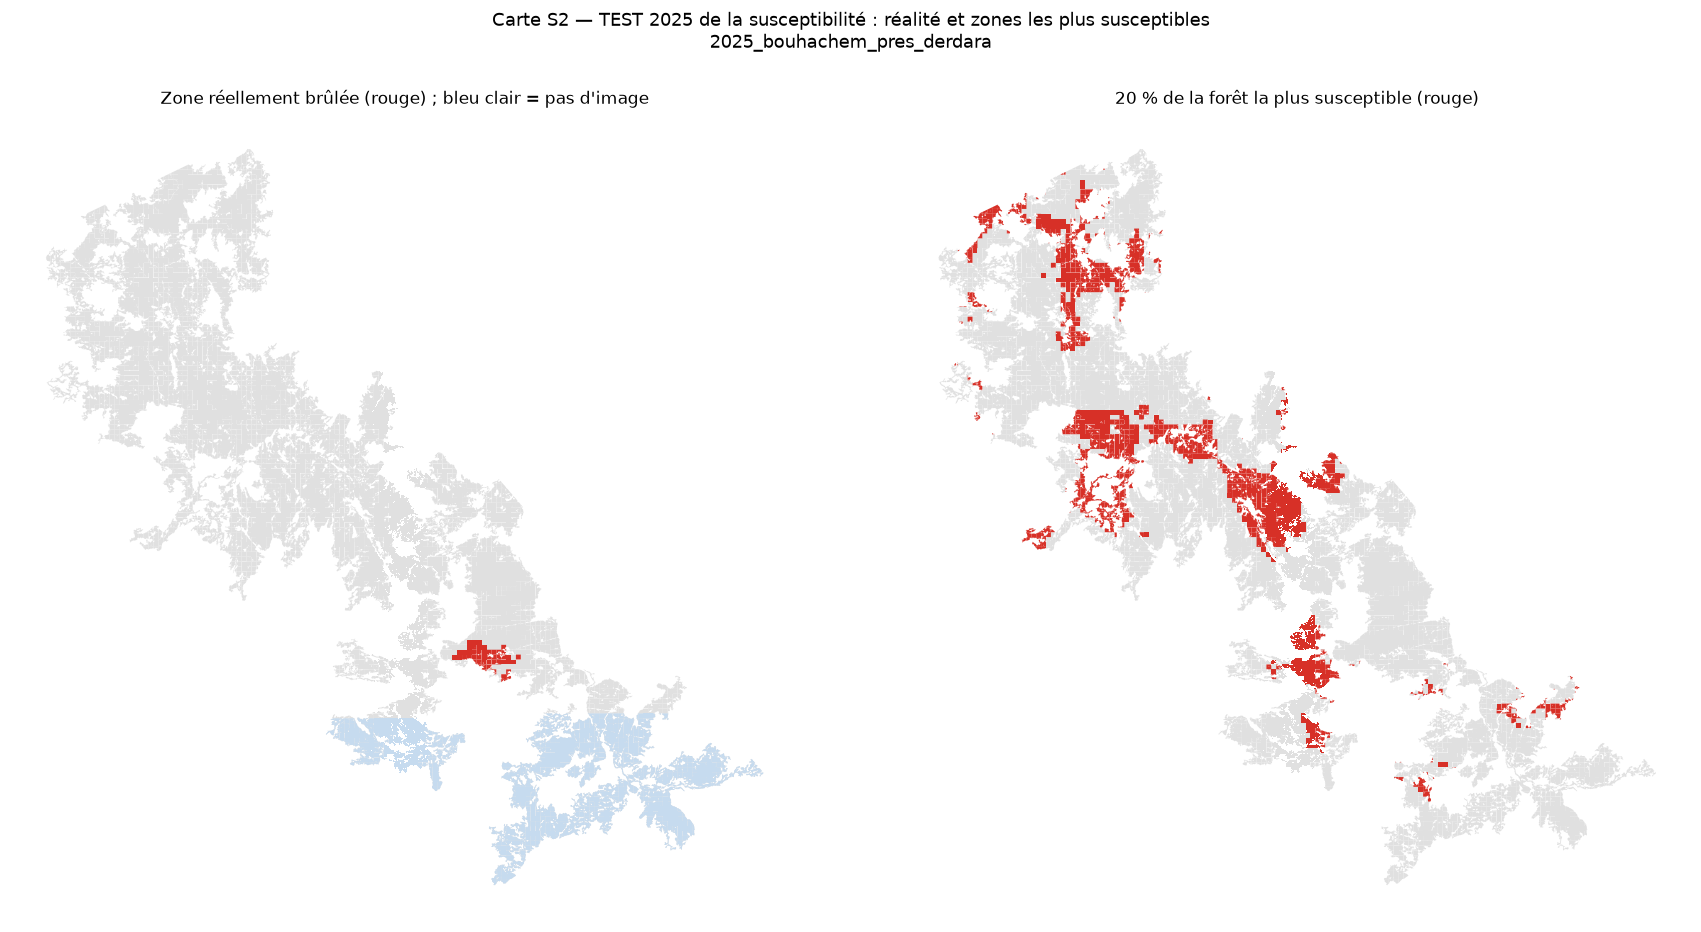

QGIS susceptibility layer (EPSG:26191): /Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/outputs/code207_risque_feu_final/susceptibilite_firms_code207.gpkg


In [25]:
# ------------------------------------------------------------------
# code205 : ANNUAL SUSCEPTIBILITY MAP (FIRMS) WITH FIRE HISTORY
# "cell x year" table from 2017 to 2024 :
#   - label   : the cell had at least one FIRMS point during the year ;
#   - inputs  : fixed factors + years since the last fire on 1 January of the year (prior history).
# "ONE YEAR OUT" validation : each year is removed in turn. Since the large fires are almost all
# in different years (2019, 2020, 2021, 2022), the same fire is never both learned and evaluated.
# Independent test : 2025 (history as of 1 August 2025, before the 2 fires), FIRMS points and dNBR burned areas.
# ------------------------------------------------------------------
from sklearn.model_selection import LeaveOneGroupOut
ANNEES_APPRENTISSAGE=list(range(2017,2025))
base=structural.copy()
base['exposition_nord']=np.cos(np.radians(base['exposition_deg']))
base['exposition_est']=np.sin(np.radians(base['exposition_deg']))
FEATURES_SUSCEPTIBILITE=[c for c in ['altitude_m','pente_pct','exposition_nord','exposition_est','population',
    'pression_humaine_01','distance_route_m','distance_piste_m','distance_batiment_m','distance_douar_m',
    'distance_agriculture_m','occupation_sol_2021','combustibilite_01'] if c in base and base[c].notna().any()]
FEATURES_SUSCEPTIBILITE+=['annees_depuis_dernier_feu','brule_moins_5ans']
_a_idx=FEATURES_SUSCEPTIBILITE.index('annees_depuis_dernier_feu')

def cellules_avec_firms(debut,fin):
    pts=firms[(firms.date>=pd.Timestamp(debut))&(firms.date<=pd.Timestamp(fin))]
    pts=pts[pts.geometry.within(foret_unique)]
    j=gpd.sjoin(pts[['geometry']],base[['id_cell','geometry']],predicate='within',how='inner')
    return base.id_cell.isin(j.id_cell).astype(int).to_numpy(),len(pts)

_panneau=[]
for _an in ANNEES_APPRENTISSAGE:
    _f=ajouter_historique(base,f'{_an}-01-01')
    _f['feu_firms'],_n=cellules_avec_firms(f'{_an}-01-01',f'{_an}-12-31'); _f['annee']=_an
    _panneau.append(_f); print('  {} : {} FIRMS points, {} cells with fire'.format(_an,_n,int(_f.feu_firms.sum())))
PANNEAU=pd.concat(_panneau,ignore_index=True)
X=PANNEAU[FEATURES_SUSCEPTIBILITE]; y=PANNEAU.feu_firms; groupes=PANNEAU.annee

_cands={'Logistic regression':make_model_logreg,'RandomForest (regularised)':make_model}
_lignes=[]
for _nom,_fab in _cands.items():
    _p=np.zeros(len(PANNEAU)); _par_an={}
    for _tr,_te in LeaveOneGroupOut().split(X,y,groupes):
        _m=_fab(); _m.fit(X.iloc[_tr],y.iloc[_tr]); _p[_te]=regle_combustible(_m.predict_proba(X.iloc[_te])[:,1],X.iloc[_te]['annees_depuis_dernier_feu'])
        _an=int(groupes.iloc[_te[0]]); _yt=y.iloc[_te]
        if 0<_yt.sum()<len(_yt): _par_an[_an]=roc_auc_score(_yt,_p[_te])
    _lignes.append({'model':_nom,'ROC_AUC_global':roc_auc_score(y,_p),'PR_lift':average_precision_score(y,_p)/y.mean(),
                    'ROC_AUC_moyen_par_annee':np.mean(list(_par_an.values())),
                    **{f'ROC_{a}':v for a,v in _par_an.items()}})
_table_susc=pd.DataFrame(_lignes).sort_values('ROC_AUC_moyen_par_annee',ascending=False)
print('"One year out" validation (2017-2024):'); display(_table_susc)
NOM_MODELE_SUSC=_table_susc.iloc[0]['model']
modele_susc=_cands[NOM_MODELE_SUSC](); modele_susc.fit(X,y)

# --- Independent test 2025 ---
susc=ajouter_historique(base,'2025-08-01')
susc['susceptibilite_sans_regle']=modele_susc.predict_proba(susc[FEATURES_SUSCEPTIBILITE])[:,1]
susc['susceptibilite']=regle_combustible(susc['susceptibilite_sans_regle'],susc['annees_depuis_dernier_feu'])
susc['classe_susceptibilite']=classes_risque_non_supervisees(susc.susceptibilite,5)
susc['feu_firms_2025'],_n25=cellules_avec_firms('2025-01-01','2025-12-31')
_lignes_test=[]
def _ajouter_test(libelle,y_,p_):
    if 0<y_.sum()<len(y_):
        m=matrice_alerte_relative(p_,y_,0.20)
        _lignes_test.append({'ground truth 2025':libelle,'cellules_feu':int(y_.sum()),'ROC_AUC':roc_auc_score(y_,p_),
            'PR_lift':average_precision_score(y_,p_)/y_.mean(),'rappel_top20':m['rappel'],'precision_top20':m['precision'],'precision_hasard':y_.mean()})
_ajouter_test('FIRMS points 2025 ({} points) - without rule'.format(_n25),susc.feu_firms_2025.to_numpy(),susc.susceptibilite_sans_regle.to_numpy())
_ajouter_test('FIRMS points 2025 ({} points) - with rule'.format(_n25),susc.feu_firms_2025.to_numpy(),susc.susceptibilite.to_numpy())
for _nom,_cadre in CADRES_2025.items():
    _t=_cadre[['id_cell','fire_today','dnbr']].merge(susc[['id_cell','susceptibilite']],on='id_cell')
    _t=_t[np.isfinite(_t.dnbr.astype(float))]
    _ajouter_test('dNBR burned area '+_nom,_t.fire_today.to_numpy().astype(int),_t.susceptibilite.to_numpy())
print('INDEPENDENT TEST 2025 ({}, trained on 2017-2024 with fire history):'.format(NOM_MODELE_SUSC))
display(pd.DataFrame(_lignes_test))

_est=modele_susc.steps[-1][1]
_imp=pd.Series(np.abs(_est.coef_[0]) if hasattr(_est,'coef_') else _est.feature_importances_,index=FEATURES_SUSCEPTIBILITE)
display(_imp.sort_values(ascending=False).to_frame('importance'))
if hasattr(_est,'coef_'):
    print("Sign of the effect of annees_depuis_dernier_feu: {} (positive = an area burned long ago is more susceptible).".format(
          'positive' if _est.coef_[0][FEATURES_SUSCEPTIBILITE.index('annees_depuis_dernier_feu')]>0 else 'negative'))

_pts_app=firms[(firms.date>=TRAIN_START)&(firms.date<='2024-12-31')]; _pts_app=_pts_app[_pts_app.geometry.within(foret_unique)]
_pts_25=firms[firms.date.dt.year==2025]; _pts_25=_pts_25[_pts_25.geometry.within(foret_unique)]
fig,axes=plt.subplots(1,2,figsize=(18,9))
susc.plot(column='susceptibilite',cmap='YlOrRd',legend=True,ax=axes[0])
if len(_pts_app): _pts_app.plot(ax=axes[0],color='black',markersize=4,label='FIRMS 2017-2024 (training)')
if len(_pts_25): _pts_25.plot(ax=axes[0],color='blue',markersize=8,label='FIRMS 2025 (test)')
axes[0].legend(loc='lower left',fontsize=9); axes[0].set_title('Susceptibility on 1 August 2025 and FIRMS points')
susc.plot(column='annees_depuis_dernier_feu',cmap='viridis',legend=True,ax=axes[1])
axes[1].set_title('Years since the last known fire (20 = no known fire)')
for _ax in axes: _ax.set_axis_off()
fig.suptitle('Map S1 — 2025 SUSCEPTIBILITY with fire history (learned from FIRMS 2017-2024)\n'
             'Black points: learned fires. Blue points: 2025 fires, never seen.',fontsize=13,y=1.03)
plt.tight_layout(); plt.savefig(REPORT/'carteS1_susceptibilite_code207.png',dpi=200,bbox_inches='tight'); plt.show()

for _nom,_cadre in CADRES_2025.items():
    _t=gpd.GeoDataFrame(_cadre[['id_cell','fire_today','dnbr','geometry']].merge(susc[['id_cell','susceptibilite']],on='id_cell'),geometry='geometry',crs=CRS)
    _valide=np.isfinite(_t.dnbr.astype(float)); _t['alerte']=(_t.susceptibilite>=np.quantile(_t.susceptibilite,0.80)).astype(int)
    fig,axes=plt.subplots(1,2,figsize=(18,9))
    _t[_t.fire_today==0].plot(ax=axes[0],color='#e0e0e0')
    if (_t.fire_today==1).any(): _t[_t.fire_today==1].plot(ax=axes[0],color='#d73027')
    if (~_valide).any(): _t[~_valide].plot(ax=axes[0],color='#c6dbef')
    _t[_t.alerte==0].plot(ax=axes[1],color='#e0e0e0'); _t[_t.alerte==1].plot(ax=axes[1],color='#d73027')
    axes[0].set_title("Actually burned area (red); light blue = no image"); axes[1].set_title('Most susceptible 20 % of the forest (red)')
    for _ax in axes: _ax.set_axis_off()
    fig.suptitle('Map S2 — 2025 TEST of susceptibility: reality and most susceptible areas\n'+_nom,fontsize=13,y=1.03)
    plt.tight_layout(); plt.savefig(REPORT/f'carteS2_test_susceptibilite_{_nom}_code207.png',dpi=200,bbox_inches='tight'); plt.show()

_gpkg=REPORT/'susceptibilite_firms_code207.gpkg'
if _gpkg.exists(): _gpkg.unlink()
susc[['id_cell','partie','susceptibilite','classe_susceptibilite','annees_depuis_dernier_feu','feu_firms_2025','geometry']].to_file(_gpkg,layer='susceptibilite',driver='GPKG')
print('QGIS susceptibility layer (EPSG:26191):',_gpkg)


## Risk map for today

This cell reuses the daily cache created by `code89`. If this cache does not exist, it creates it (real-time weather + latest available Sentinel-2 scene) without ever touching the existing `code89`/`code90` caches.

Unsupervised class centers: {3: 0.4063, 5: 0.7975, 1: 0.1135, 2: 0.2627, 4: 0.5754}
Weather danger on 2026-10-10: 0.17 (low) | alert: top 20 % of cells (probability >= 0.5203).


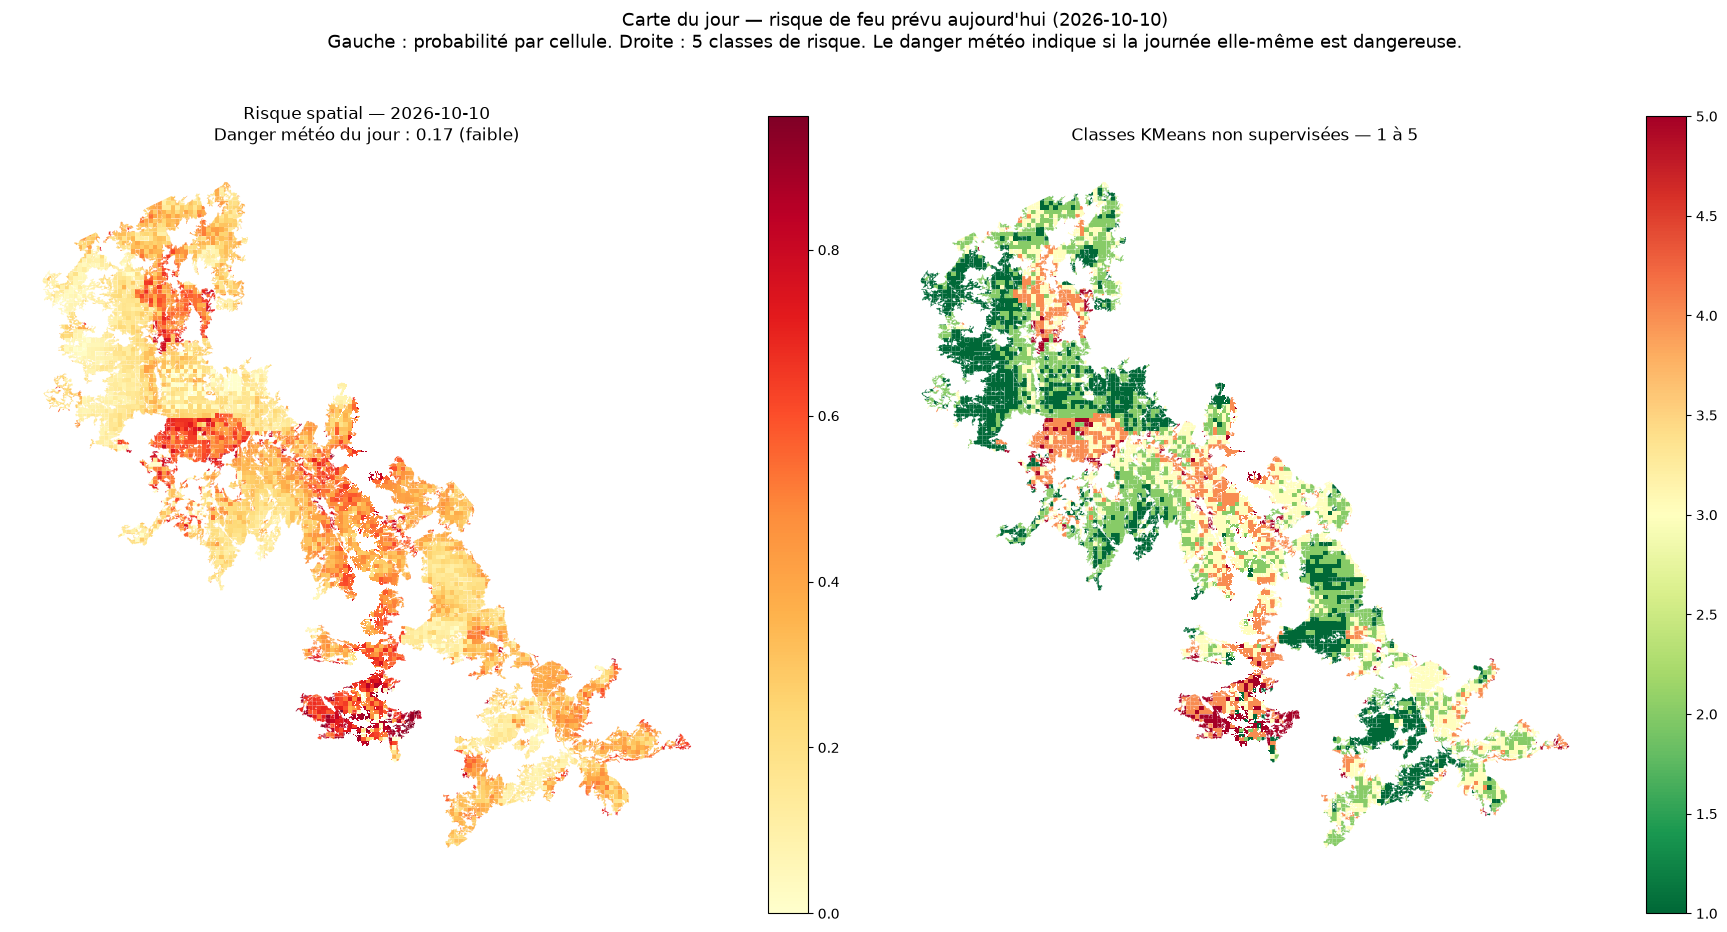

/Users/wiamekane/Desktop/Topo/hackaton/Projet Bouhachem/data_prepared/code207_risque_feu_final/risque_feu_2026-10-10_code207.gpkg


In [26]:
# NEW (code106) : today's map = spatial risk ("where?") + daily weather danger ("which day?") +
# relative alert (top FRACTION_ALERTE of the cells). The daily alert only has operational meaning if the
# weather danger is "high" or "very high" ; in calm weather, the map only shows the most
# sensitive areas of the forest.
TODAY=pd.Timestamp.now(tz='Africa/Casablanca').tz_localize(None).normalize()
today=load_code89_day(TODAY,include_target=False,allow_missing_download=True,operational=True)
today=ajouter_historique(today,TODAY)   # code205
today['probabilite_feu']=predire(model,today)   # code206 : fuel rule
today['classe_risque']=classes_risque_non_supervisees(today.probabilite_feu,5)
_seuil_jour=float(np.quantile(today.probabilite_feu,1-FRACTION_ALERTE))
today['alerte_feu']=(today.probabilite_feu>=_seuil_jour).astype('uint8')
danger_today,classe_danger_today,_=indice_danger_jour(today)
today['danger_meteo_jour']=danger_today; today['classe_danger_jour']=classe_danger_today
print('Weather danger on {}: {:.2f} ({}) | alert: top {:.0f} % of cells (probability >= {:.4f}).'.format(
      TODAY.date(),danger_today,classe_danger_today,100*FRACTION_ALERTE,_seuil_jour))
gpkg=PREP/f'risque_feu_{TODAY.date()}_code207.gpkg'
if gpkg.exists(): gpkg.unlink()
today.to_file(gpkg,layer='risque_du_jour',driver='GPKG')
today.drop(columns='geometry').to_csv(PREP/f'risque_feu_{TODAY.date()}_code207.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(18,9))
today.plot(column='probabilite_feu',cmap='YlOrRd',legend=True,ax=axes[0])
today.plot(column='classe_risque',cmap='RdYlGn_r',vmin=1,vmax=5,legend=True,ax=axes[1])
axes[0].set_title(f'Spatial risk — {TODAY.date()}\nWeather danger of the day: {danger_today:.2f} ({classe_danger_today})')
axes[1].set_title('Unsupervised KMeans classes — 1 to 5')
for ax in axes:ax.set_axis_off()
fig.suptitle("Today's map — fire risk forecast for today ({})\nLeft: probability per cell. Right: 5 risk classes. The weather danger shows whether the day itself is dangerous.".format(TODAY.date()),fontsize=13,y=1.03)
plt.tight_layout()
plt.savefig(REPORT/f'risque_feu_{TODAY.date()}_code207.png',dpi=220,bbox_inches='tight');plt.show();print(gpkg)


## Final model summary


In [27]:
# ------------------------------------------------------------------
# code207 : FINAL SUMMARY (summary to carry over into the report)
# ------------------------------------------------------------------
print('='*90); print('FINAL SUMMARY'); print('='*90)
print('1) SPATIAL MODEL ("where?") — 12 splits, each fire evaluated by a model that has never seen it')
print('   Mean test ROC-AUC: {:.3f} without the fuel rule, {:.3f} with it (0.5 = chance).'.format(
      TABLE_REPETITIONS.ROC_AUC_test_sans_regle.mean(),TABLE_REPETITIONS.ROC_AUC_test.mean()))
print('   Mean test PR-AUC: {:.1f} x chance.'.format(TABLE_REPETITIONS.PR_lift_test.mean()))
display(TABLE_REPETITIONS.groupby('test')[['ROC_AUC_test','PR_lift_test','rappel_test','precision_test','precision_hasard']].mean().round(3))
print('2) WEATHER DANGER OF THE DAY ("when?") — compared with {} summer days 2017-2024'.format(len(CLIMATO_ETE)))
_jf=_controle[_controle.jour_de_feu]
print('   Fire days classed "high" or "very high": {} out of {}; mean index of fire days = {:.2f} (0.50 for an arbitrary summer day).'.format(
      int(_jf.classe.isin(['high','very high']).sum()),len(_jf),_jf.indice_danger.mean()))
display(_jf[['journee','date','indice_danger','classe']].reset_index(drop=True))


FINAL SUMMARY
1) SPATIAL MODEL ("where?") — 12 splits, each fire evaluated by a model that has never seen it
   Mean test ROC-AUC: 0.576 without the fuel rule, 0.597 with it (0.5 = chance).
   Mean test PR-AUC: 2.8 x chance.


,ROC_AUC_test,PR_lift_test,rappel_test,precision_test,precision_hasard
test,,,,,
2009a,0.739,2.088,0.400,0.010,0.005
2020,0.437,0.851,0.155,0.029,0.038
2022,0.636,1.473,0.237,0.230,0.153
2025_bouhachem_pres_derdara,0.518,0.972,0.130,0.007,0.010
2025_derdara,0.358,0.746,0.070,0.032,0.079
derdara_2021,0.891,10.855,0.799,0.172,0.043


2) WEATHER DANGER OF THE DAY ("when?") — compared with 976 summer days 2017-2024
   Fire days classed "high" or "very high": 5 out of 8; mean index of fire days = 0.59 (0.50 for an arbitrary summer day).


,journee,date,indice_danger,classe
0,incendie_2022,2022-07-25,0.952869,very high
1,incendie_derdara_2021,2021-08-14,0.851947,very high
2,incendie_tanaqoub_2019a,2019-08-13,0.748207,high
3,incendie_2009a,2009-07-26,0.694160,high
4,incendie_2020,2020-08-25,0.667777,high
5,incendie_2009bc,2009-08-11,0.284580,moderate
6,incendie_tanaqoub_2019b,2019-09-13,0.283555,moderate
7,incendie_2005,2005-09-21,0.214395,low
